# Baseline LSTM

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import random

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
CUDA available: False


In [3]:
df = pd.read_csv("Solar_Forecasting.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (26297, 14)


,Datetime_UTC,Solar_MW,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,0.449746,11.32,69.29,5.05,2.37,0.0,0.0,0.0,NaN,7,6,1,1
1,2023-01-01 08:00:00+00:00,0.454733,10.36,75.44,4.62,10.12,0.0,0.0,0.0,NaN,8,6,1,1
2,2023-01-01 09:00:00+00:00,0.443528,9.76,79.94,4.48,17.85,0.0,0.0,0.0,NaN,9,6,1,1
3,2023-01-01 10:00:00+00:00,0.458567,9.22,83.95,4.39,57.65,0.0,0.0,0.0,NaN,10,6,1,1
4,2023-01-01 11:00:00+00:00,0.451126,8.69,87.17,4.19,99.70,0.0,0.0,0.0,NaN,11,6,1,1


In [4]:
df['Datetime_UTC'] = pd.to_datetime(df['Datetime_UTC'])

df = df.sort_values('Datetime_UTC').reset_index(drop=True)

print("Start:", df['Datetime_UTC'].min())
print("End  :", df['Datetime_UTC'].max())

Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00


In [5]:
# Split the data into 2 years for training and 1 year for testing

TRAIN_END = '2024-12-31 23:59:59'

train_df = df[df['Datetime_UTC'] <= TRAIN_END].copy()
test_df = df[df['Datetime_UTC'] > TRAIN_END].copy()

print("Training samples:", len(train_df))
print("Testing samples :", len(test_df))

print("\nTraining period:")
print(train_df['Datetime_UTC'].min(), "→", train_df['Datetime_UTC'].max())

print("\nTesting period:")
print(test_df['Datetime_UTC'].min(), "→", test_df['Datetime_UTC'].max())

Training samples: 17537
Testing samples : 8760

Training period:
2023-01-01 07:00:00+00:00 → 2024-12-31 23:00:00+00:00

Testing period:
2025-01-01 00:00:00+00:00 → 2025-12-31 23:00:00+00:00


In [7]:
# Define the input features and forecasting target

FEATURES = [
    'Solar_MW',
    'T2M',
    'RH2M',
    'WS10M',
    'CLOUD_AMT',
    'ALLSKY_SFC_SW_DWN',
    'ALLSKY_SFC_SW_DNI',
    'ALLSKY_SFC_SW_DIFF',
    'Hour',
    'DayOfWeek',
    'DayOfYear',
    'Month'
]

TARGET = 'Solar_MW'

print("Number of features:", len(FEATURES))
print("Target:", TARGET)

Number of features: 12
Target: Solar_MW


In [8]:
# Check that all required forecasting features are available

missing_features = [
    col for col in FEATURES
    if col not in df.columns
]

if len(missing_features) == 0:
    print("All features are available.")
else:
    print("Missing features:")
    print(missing_features)

All features are available.


In [125]:
# Check missing values in the selected forecasting features

print(df[FEATURES].isnull().sum())

Solar_MW              0
T2M                   0
RH2M                  0
WS10M                 0
CLOUD_AMT             0
ALLSKY_SFC_SW_DWN     0
ALLSKY_SFC_SW_DNI     0
ALLSKY_SFC_SW_DIFF    0
Hour                  0
DayOfWeek             0
DayOfYear             0
Month                 0
dtype: int64


In [126]:
# Extract training and testing features and targets

X_train_raw = train_df[FEATURES].values
y_train_raw = train_df[TARGET].values.reshape(-1, 1)

X_test_raw = test_df[FEATURES].values
y_test_raw = test_df[TARGET].values.reshape(-1, 1)

print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)

print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

X_train: (17537, 12)
y_train: (17537, 1)
X_test : (8760, 12)
y_test : (8760, 1)


In [127]:
# Create scalers using training data only

from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

In [128]:
# Fit scalers on training data and transform both training and testing data

X_train_scaled = feature_scaler.fit_transform(X_train_raw)
X_test_scaled = feature_scaler.transform(X_test_raw)

y_train_scaled = target_scaler.fit_transform(y_train_raw)
y_test_scaled = target_scaler.transform(y_test_raw)

print("Training feature mean:", X_train_scaled.mean(axis=0))
print("Training feature std :", X_train_scaled.std(axis=0))

Training feature mean: [ 2.59307379e-17 -2.33376641e-16 -2.07445903e-16 -2.33376641e-16
 -5.83441603e-17  8.42748982e-17  9.39989250e-17 -1.73411810e-16
 -7.25250326e-17  3.48444291e-17  1.03722952e-16 -5.18614758e-17]
Training feature std : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [129]:
# Define the historical lookback window and forecasting horizon

LOOKBACK = 24
HORIZON = 1

print("Lookback:", LOOKBACK, "hours")
print("Forecast horizon:", HORIZON, "hour")

Lookback: 24 hours
Forecast horizon: 1 hour


In [130]:
# Create 24-hour sliding-window sequences for training

def create_sequences(X, y, lookback):
    
    X_seq = []
    y_seq = []
    
    for i in range(lookback, len(X)):
        
        X_seq.append(
            X[i - lookback:i]
        )
        
        y_seq.append(
            y[i]
        )
    
    return np.array(X_seq), np.array(y_seq)


X_train_seq, y_train_seq = create_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK
)

print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)

X_train_seq: (17513, 24, 12)
y_train_seq: (17513, 1)


In [131]:
# Create test sequences while allowing the first 2025 prediction to use late-2024 history

X_combined = np.concatenate(
    [X_train_scaled, X_test_scaled],
    axis=0
)

y_combined = np.concatenate(
    [y_train_scaled, y_test_scaled],
    axis=0
)

train_size = len(X_train_scaled)

X_test_seq = []
y_test_seq = []

for i in range(train_size, len(X_combined)):
    
    X_test_seq.append(
        X_combined[i - LOOKBACK:i]
    )
    
    y_test_seq.append(
        y_combined[i]
    )

X_test_seq = np.array(X_test_seq)
y_test_seq = np.array(y_test_seq)

print("X_test_seq:", X_test_seq.shape)
print("y_test_seq:", y_test_seq.shape)

X_test_seq: (8760, 24, 12)
y_test_seq: (8760, 1)


In [132]:
# Verify that the test sequences correspond exactly to the 2025 target timestamps

print("First test target:")
print(test_df['Datetime_UTC'].iloc[0])

print("\nLast test target:")
print(test_df['Datetime_UTC'].iloc[-1])

print("\nNumber of test predictions:")
print(len(y_test_seq))

First test target:
2025-01-01 00:00:00+00:00

Last test target:
2025-12-31 23:00:00+00:00

Number of test predictions:
8760


In [133]:
# Convert the sequence data into PyTorch tensors

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_seq,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_seq,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_seq,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_seq,
    dtype=torch.float32
)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train: torch.Size([17513, 24, 12])
y_train: torch.Size([17513, 1])
X_test : torch.Size([8760, 24, 12])
y_test : torch.Size([8760, 1])


In [30]:
# Create DataLoaders for training and final testing

BATCH_SIZE = 64

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches :", len(test_loader))

Training batches: 274
Testing batches : 137


In [31]:
# Select GPU if available, otherwise use CPU

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print("Using device:", device)

Using device: cpu


In [32]:
# Define the baseline one-layer LSTM forecasting model

class SolarLSTM(nn.Module):
    
    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2
    ):
        
        super(SolarLSTM, self).__init__()
        
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        
        self.dropout = nn.Dropout(dropout)
        
        self.fc = nn.Linear(
            hidden_size,
            1
        )
    
    def forward(self, x):
        
        # LSTM output shape: (batch, sequence, hidden)
        out, _ = self.lstm(x)
        
        # Use the final timestep
        out = out[:, -1, :]
        
        out = self.dropout(out)
        
        out = self.fc(out)
        
        return out

In [33]:
# Initialize the baseline LSTM with one layer and 128 hidden neurons

INPUT_SIZE = len(FEATURES)
HIDDEN_SIZE = 128
NUM_LAYERS = 1
DROPOUT = 0.2

model = SolarLSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(model)

SolarLSTM(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [34]:
# Count the trainable parameters in the baseline model

total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 72833


In [35]:
# Define the loss function and Adam optimizer

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [36]:
# Train the LSTM for one complete epoch

def train_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    
    model.train()
    
    running_loss = 0.0
    
    for X_batch, y_batch in loader:
        
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        
        predictions = model(X_batch)
        
        loss = criterion(
            predictions,
            y_batch
        )
        
        loss.backward()
        
        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        
        optimizer.step()
        
        running_loss += (
            loss.item() * X_batch.size(0)
        )
    
    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )
    
    return epoch_loss

In [37]:
# Train the baseline LSTM using only the 2023-2024 training data

EPOCHS = 20

train_losses = []

for epoch in range(EPOCHS):
    
    train_loss = train_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )
    
    train_losses.append(train_loss)
    
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/20] Train Loss: 0.107628
Epoch [02/20] Train Loss: 0.028115
Epoch [03/20] Train Loss: 0.020374
Epoch [04/20] Train Loss: 0.016349
Epoch [05/20] Train Loss: 0.014478
Epoch [06/20] Train Loss: 0.012902
Epoch [07/20] Train Loss: 0.012531
Epoch [08/20] Train Loss: 0.011703
Epoch [09/20] Train Loss: 0.011029
Epoch [10/20] Train Loss: 0.010829
Epoch [11/20] Train Loss: 0.010351
Epoch [12/20] Train Loss: 0.010334
Epoch [13/20] Train Loss: 0.009995
Epoch [14/20] Train Loss: 0.010059
Epoch [15/20] Train Loss: 0.009549
Epoch [16/20] Train Loss: 0.009450
Epoch [17/20] Train Loss: 0.009271
Epoch [18/20] Train Loss: 0.009093
Epoch [19/20] Train Loss: 0.008946
Epoch [20/20] Train Loss: 0.009056


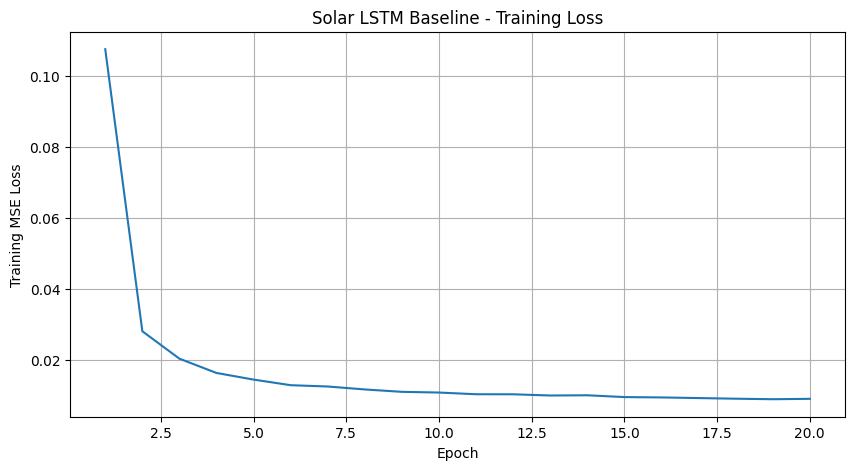

In [38]:
# Plot the training loss across epochs

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Solar LSTM Baseline - Training Loss")

plt.grid(True)
plt.show()

In [39]:
# Generate predictions on the unseen 2025 test data

def predict(
    model,
    loader,
    device
):
    
    model.eval()
    
    predictions = []
    actuals = []
    
    with torch.no_grad():
        
        for X_batch, y_batch in loader:
            
            X_batch = X_batch.to(device)
            
            outputs = model(X_batch)
            
            predictions.append(
                outputs.cpu().numpy()
            )
            
            actuals.append(
                y_batch.numpy()
            )
    
    predictions = np.concatenate(
        predictions
    )
    
    actuals = np.concatenate(
        actuals
    )
    
    return predictions, actuals

In [40]:
# Generate predictions for the complete 2025 test year

pred_scaled, actual_scaled = predict(
    model,
    test_loader,
    device
)

print("Prediction shape:", pred_scaled.shape)
print("Actual shape    :", actual_scaled.shape)

Prediction shape: (8760, 1)
Actual shape    : (8760, 1)


In [41]:
# Convert scaled predictions and actual values back to MW

pred = target_scaler.inverse_transform(
    pred_scaled
).flatten()

actual = target_scaler.inverse_transform(
    actual_scaled
).flatten()

print("First 10 actual values:")
print(actual[:10])

print("\nFirst 10 predicted values:")
print(pred[:10])

First 10 actual values:
[1.4551191e+03 5.9277344e-01 6.1669922e-01 6.8115234e-01 6.8408203e-01
 6.9531250e-01 7.0361328e-01 7.2509766e-01 7.4365234e-01 7.4267578e-01]

First 10 predicted values:
[1420.9839    963.7991    444.16895   151.58984   116.944336   59.1875
  -21.38623   -48.60791   -65.78906   -85.59277 ]


In [42]:
# Evaluate the baseline LSTM using MAE, RMSE and R-squared

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    actual,
    pred
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        pred
    )
)

r2 = r2_score(
    actual,
    pred
)

print("=" * 50)
print("SOLAR LSTM BASELINE RESULTS")
print("=" * 50)

print(f"MAE  : {mae:.4f} MW")
print(f"RMSE : {rmse:.4f} MW")
print(f"R²   : {r2:.6f}")

print("=" * 50)

SOLAR LSTM BASELINE RESULTS
MAE  : 513.8299 MW
RMSE : 910.8867 MW
R²   : 0.990805


In [43]:
# Calculate MAPE only for periods with meaningful solar generation

daylight_mask = actual > 10

daylight_mape = np.mean(
    np.abs(
        (actual[daylight_mask] - pred[daylight_mask])
        / actual[daylight_mask]
    )
) * 100

print(
    f"Daylight MAPE: {daylight_mape:.2f}%"
)

Daylight MAPE: 43.60%


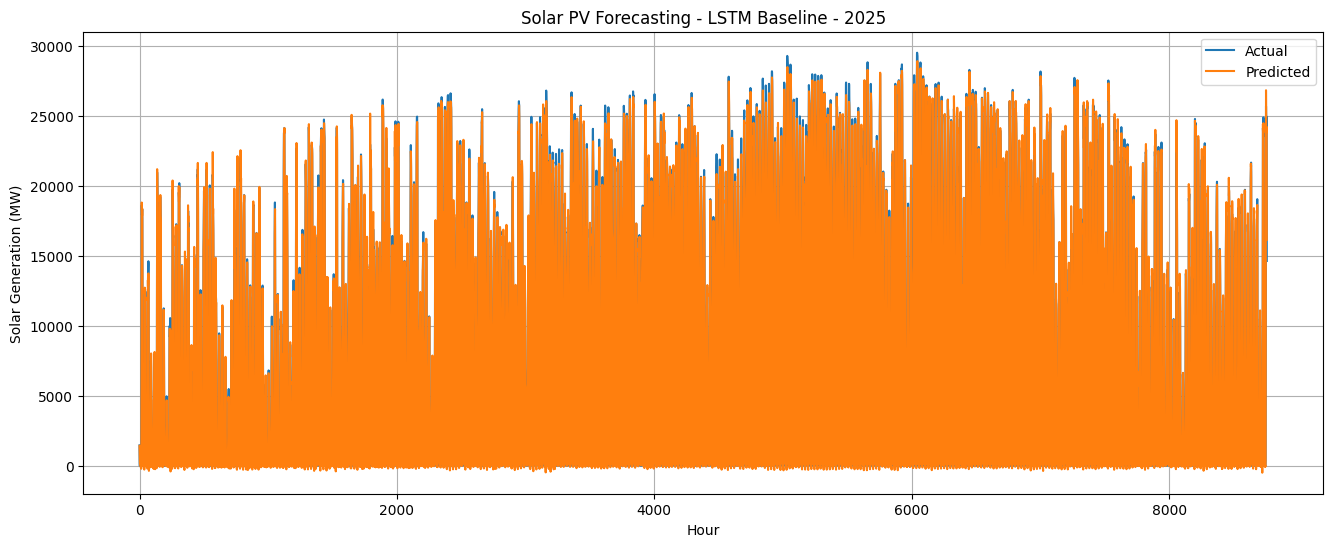

In [44]:
# Plot actual and predicted solar generation for the complete 2025 test year

plt.figure(figsize=(16, 6))

plt.plot(
    actual,
    label='Actual'
)

plt.plot(
    pred,
    label='Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")
plt.title("Solar PV Forecasting - LSTM Baseline - 2025")

plt.legend()
plt.grid(True)

plt.show()

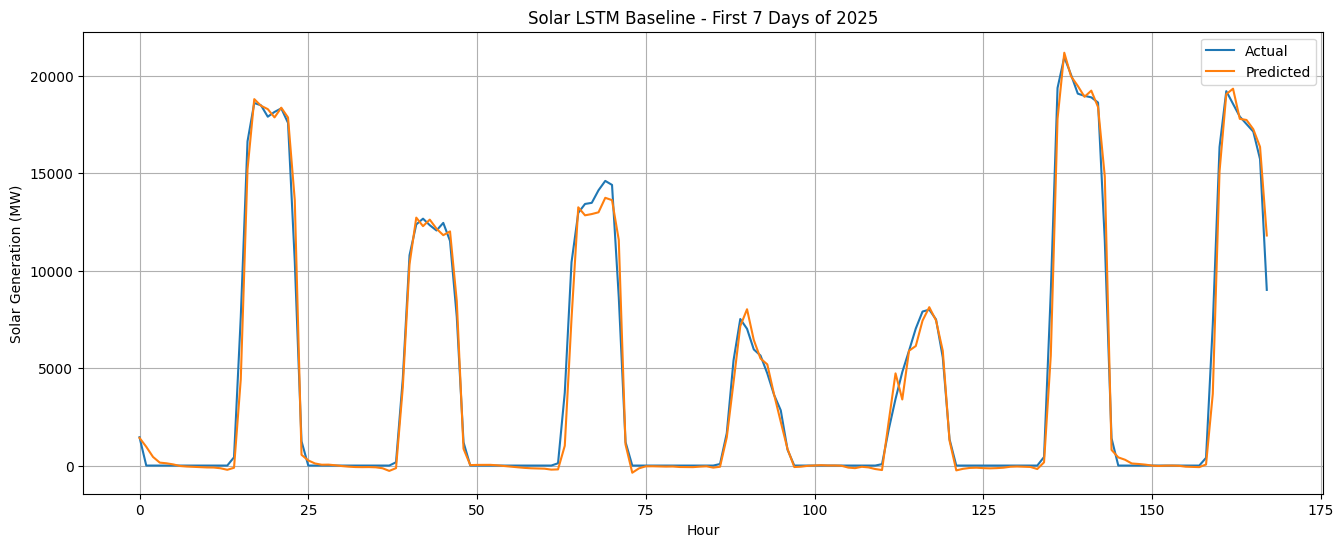

In [45]:
# Plot actual and predicted generation for the first seven days of 2025

HOURS_TO_PLOT = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    actual[:HOURS_TO_PLOT],
    label='Actual'
)

plt.plot(
    pred[:HOURS_TO_PLOT],
    label='Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")
plt.title("Solar LSTM Baseline - First 7 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

In [46]:
# Calculate the prediction residuals for the 2025 test period

residuals = actual - pred

print("Mean residual:", residuals.mean())
print("Residual std  :", residuals.std())

Mean residual: 114.40694
Residual std  : 903.6733


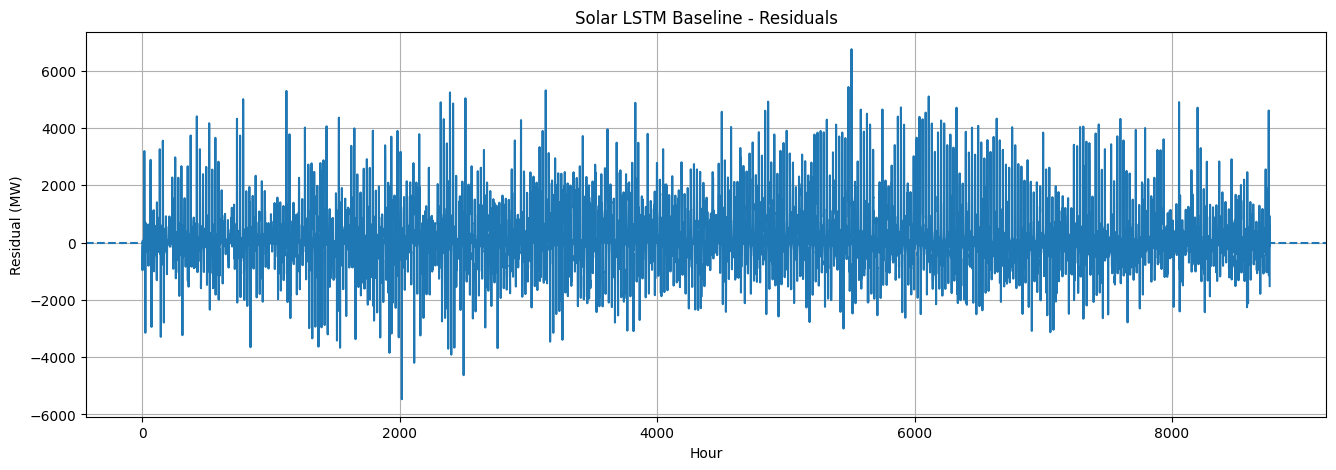

In [47]:
# Plot the residual errors across the 2025 test period

plt.figure(figsize=(16, 5))

plt.plot(
    residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Hour")
plt.ylabel("Residual (MW)")
plt.title("Solar LSTM Baseline - Residuals")

plt.grid(True)

plt.show()

# CNN - LSTM

In [49]:
# Define the CNN-LSTM hybrid forecasting model

class SolarCNNLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_channels=64,
        kernel_size=3,
        hidden_size=128,
        num_layers=1,
        dropout=0.2
    ):

        super(SolarCNNLSTM, self).__init__()

        # CNN extracts local temporal patterns
        self.cnn = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_channels,
            kernel_size=kernel_size,
            padding=1
        )

        self.relu = nn.ReLU()

        # LSTM learns temporal dependencies from CNN features
        self.lstm = nn.LSTM(
            input_size=cnn_channels,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        # Final regression layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        # Input shape:
        # (batch, sequence_length, features)

        # CNN expects:
        # (batch, features, sequence_length)
        x = x.permute(0, 2, 1)

        # CNN feature extraction
        x = self.cnn(x)

        x = self.relu(x)

        # Convert back for LSTM:
        # (batch, sequence_length, CNN features)
        x = x.permute(0, 2, 1)

        # LSTM temporal learning
        out, _ = self.lstm(x)

        # Take the final timestep
        out = out[:, -1, :]

        # Dropout
        out = self.dropout(out)

        # Solar generation prediction
        out = self.fc(out)

        return out

In [50]:
# Set the CNN-LSTM architecture parameters

INPUT_SIZE = len(FEATURES)

CNN_CHANNELS = 64
KERNEL_SIZE = 3

HIDDEN_SIZE = 128
NUM_LAYERS = 1
DROPOUT = 0.2

print("Input features :", INPUT_SIZE)
print("CNN channels   :", CNN_CHANNELS)
print("Kernel size    :", KERNEL_SIZE)
print("LSTM hidden    :", HIDDEN_SIZE)
print("LSTM layers    :", NUM_LAYERS)
print("Dropout        :", DROPOUT)

Input features : 12
CNN channels   : 64
Kernel size    : 3
LSTM hidden    : 128
LSTM layers    : 1
Dropout        : 0.2


In [51]:
# Initialize the CNN-LSTM model

cnn_lstm_model = SolarCNNLSTM(
    input_size=INPUT_SIZE,
    cnn_channels=CNN_CHANNELS,
    kernel_size=KERNEL_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(cnn_lstm_model)

SolarCNNLSTM(
  (cnn): Conv1d(12, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(64, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [52]:
# Count the trainable parameters in the CNN-LSTM model

cnn_lstm_parameters = sum(
    p.numel()
    for p in cnn_lstm_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", cnn_lstm_parameters)

Trainable parameters: 101825


In [53]:
# Define the loss function and optimizer for CNN-LSTM

cnn_lstm_criterion = nn.MSELoss()

cnn_lstm_optimizer = torch.optim.Adam(
    cnn_lstm_model.parameters(),
    lr=0.001
)

In [54]:
# Train the CNN-LSTM model for one complete epoch

def train_cnn_lstm_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        # Clip gradients to improve training stability
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [56]:
# Train the CNN-LSTM model using only the 2023-2024 training data

EPOCHS = 20

cnn_lstm_train_losses = []

for epoch in range(EPOCHS):

    train_loss = train_cnn_lstm_epoch(
        cnn_lstm_model,
        train_loader,
        cnn_lstm_criterion,
        cnn_lstm_optimizer,
        device
    )

    cnn_lstm_train_losses.append(train_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/20] Train Loss: 0.016410
Epoch [02/20] Train Loss: 0.013302
Epoch [03/20] Train Loss: 0.011620
Epoch [04/20] Train Loss: 0.010809
Epoch [05/20] Train Loss: 0.010131
Epoch [06/20] Train Loss: 0.009972
Epoch [07/20] Train Loss: 0.009809
Epoch [08/20] Train Loss: 0.009378
Epoch [09/20] Train Loss: 0.008933
Epoch [10/20] Train Loss: 0.008809
Epoch [11/20] Train Loss: 0.008671
Epoch [12/20] Train Loss: 0.008281
Epoch [13/20] Train Loss: 0.007856
Epoch [14/20] Train Loss: 0.008012
Epoch [15/20] Train Loss: 0.007896
Epoch [16/20] Train Loss: 0.007765
Epoch [17/20] Train Loss: 0.007757
Epoch [18/20] Train Loss: 0.007519
Epoch [19/20] Train Loss: 0.007749
Epoch [20/20] Train Loss: 0.007298


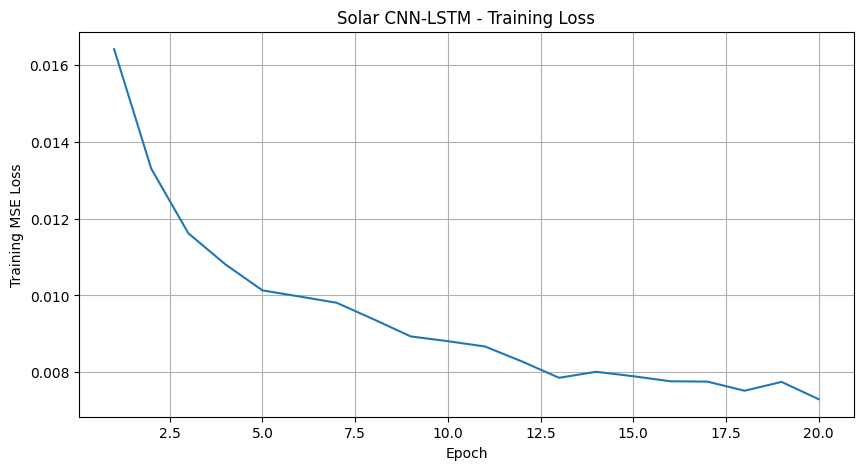

In [57]:
# Plot the CNN-LSTM training loss across epochs

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    cnn_lstm_train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Solar CNN-LSTM - Training Loss")

plt.grid(True)

plt.show()

In [58]:
# Generate predictions from the trained CNN-LSTM model

def predict_cnn_lstm(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(X_batch)

            predictions.append(
                outputs.cpu().numpy()
            )

            actuals.append(
                y_batch.numpy()
            )

    predictions = np.concatenate(
        predictions
    )

    actuals = np.concatenate(
        actuals
    )

    return predictions, actuals

In [59]:
# Generate predictions for the unseen 2025 test year

cnn_lstm_pred_scaled, cnn_lstm_actual_scaled = predict_cnn_lstm(
    cnn_lstm_model,
    test_loader,
    device
)

print(
    "Prediction shape:",
    cnn_lstm_pred_scaled.shape
)

print(
    "Actual shape:",
    cnn_lstm_actual_scaled.shape
)

Prediction shape: (8760, 1)
Actual shape: (8760, 1)


In [60]:
# Convert CNN-LSTM predictions back from scaled values to MW

cnn_lstm_pred = target_scaler.inverse_transform(
    cnn_lstm_pred_scaled
).flatten()

cnn_lstm_actual = target_scaler.inverse_transform(
    cnn_lstm_actual_scaled
).flatten()

print("First 10 actual values:")
print(cnn_lstm_actual[:10])

print("\nFirst 10 predicted values:")
print(cnn_lstm_pred[:10])

First 10 actual values:
[1.4551191e+03 5.9277344e-01 6.1669922e-01 6.8115234e-01 6.8408203e-01
 6.9531250e-01 7.0361328e-01 7.2509766e-01 7.4365234e-01 7.4267578e-01]

First 10 predicted values:
[1554.7749      -3.8745117   30.57666     59.737793    82.9624
   81.31592     46.634766   112.77295    101.398926    91.91016  ]


In [61]:
# Evaluate CNN-LSTM using MAE, RMSE and R-squared

cnn_lstm_mae = mean_absolute_error(
    cnn_lstm_actual,
    cnn_lstm_pred
)

cnn_lstm_rmse = np.sqrt(
    mean_squared_error(
        cnn_lstm_actual,
        cnn_lstm_pred
    )
)

cnn_lstm_r2 = r2_score(
    cnn_lstm_actual,
    cnn_lstm_pred
)

print("=" * 55)
print("SOLAR CNN-LSTM RESULTS")
print("=" * 55)

print(
    f"MAE  : {cnn_lstm_mae:.4f} MW"
)

print(
    f"RMSE : {cnn_lstm_rmse:.4f} MW"
)

print(
    f"R²   : {cnn_lstm_r2:.6f}"
)

print("=" * 55)

SOLAR CNN-LSTM RESULTS
MAE  : 651.1410 MW
RMSE : 1077.3985 MW
R²   : 0.987136


In [62]:
# Compare CNN-LSTM performance with the frozen LSTM baseline

comparison = pd.DataFrame({

    'Model': [
        'LSTM Baseline',
        'CNN-LSTM'
    ],

    'MAE_MW': [
        mae,
        cnn_lstm_mae
    ],

    'RMSE_MW': [
        rmse,
        cnn_lstm_rmse
    ],

    'R2': [
        r2,
        cnn_lstm_r2
    ]
})

display(comparison)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM Baseline,513.829895,910.886656,0.990805
1,CNN-LSTM,651.140991,1077.398487,0.987136


In [63]:
# Calculate the percentage improvement of CNN-LSTM over the LSTM baseline

mae_improvement = (
    (mae - cnn_lstm_mae) / mae
) * 100

rmse_improvement = (
    (rmse - cnn_lstm_rmse) / rmse
) * 100

r2_improvement = (
    (cnn_lstm_r2 - r2) / r2
) * 100

print(
    f"MAE improvement : {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    f"R² improvement  : {r2_improvement:.4f}%"
)

MAE improvement : -26.72%
RMSE improvement: -18.28%
R² improvement  : -0.3703%


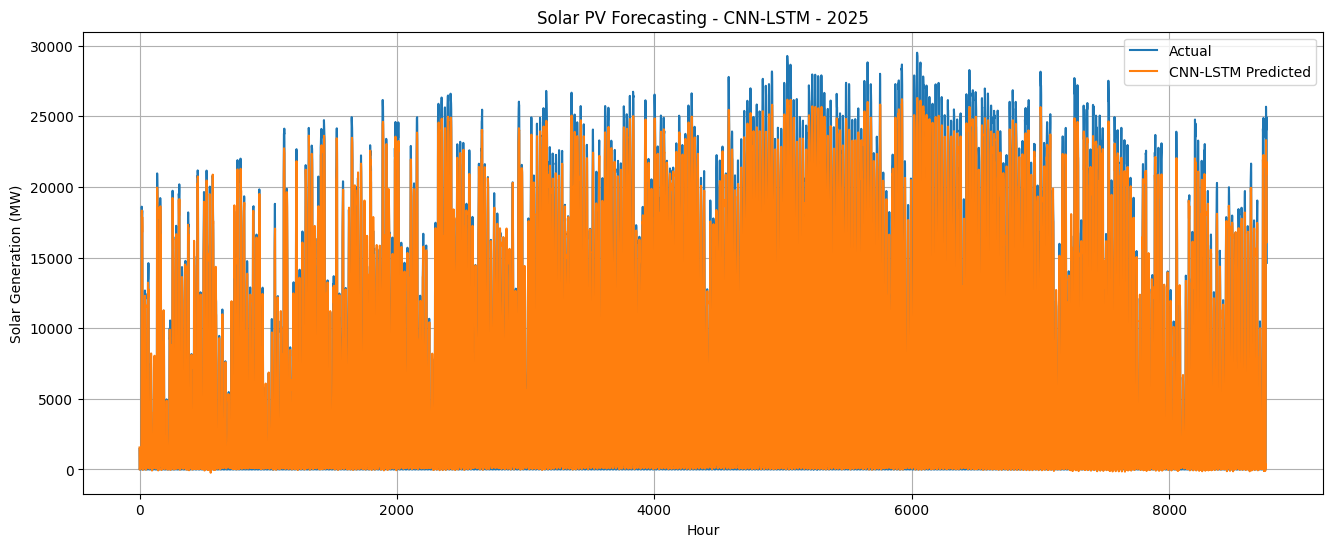

In [64]:
# Plot actual and CNN-LSTM predicted solar generation for 2025

plt.figure(figsize=(16, 6))

plt.plot(
    cnn_lstm_actual,
    label='Actual'
)

plt.plot(
    cnn_lstm_pred,
    label='CNN-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar PV Forecasting - CNN-LSTM - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

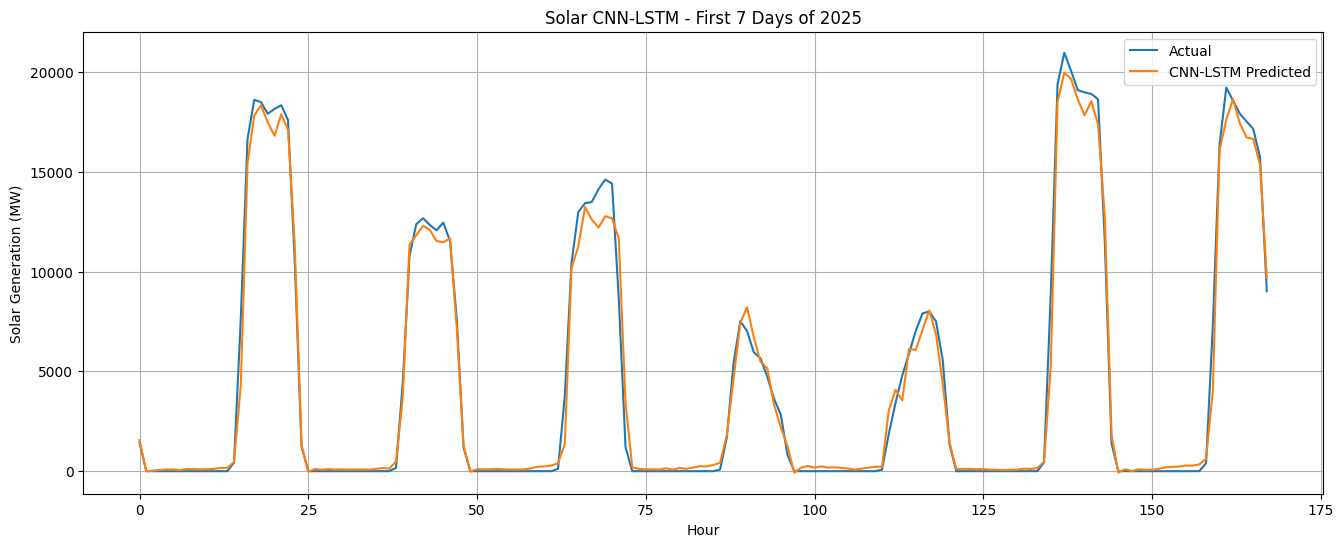

In [65]:
# Plot CNN-LSTM predictions for the first seven days of 2025

HOURS_TO_PLOT = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    cnn_lstm_actual[:HOURS_TO_PLOT],
    label='Actual'
)

plt.plot(
    cnn_lstm_pred[:HOURS_TO_PLOT],
    label='CNN-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar CNN-LSTM - First 7 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

In [66]:
# Calculate CNN-LSTM prediction residuals for the 2025 test period

cnn_lstm_residuals = (
    cnn_lstm_actual -
    cnn_lstm_pred
)

print(
    "Mean residual:",
    cnn_lstm_residuals.mean()
)

print(
    "Residual std:",
    cnn_lstm_residuals.std()
)

Mean residual: 397.0402
Residual std: 1001.572


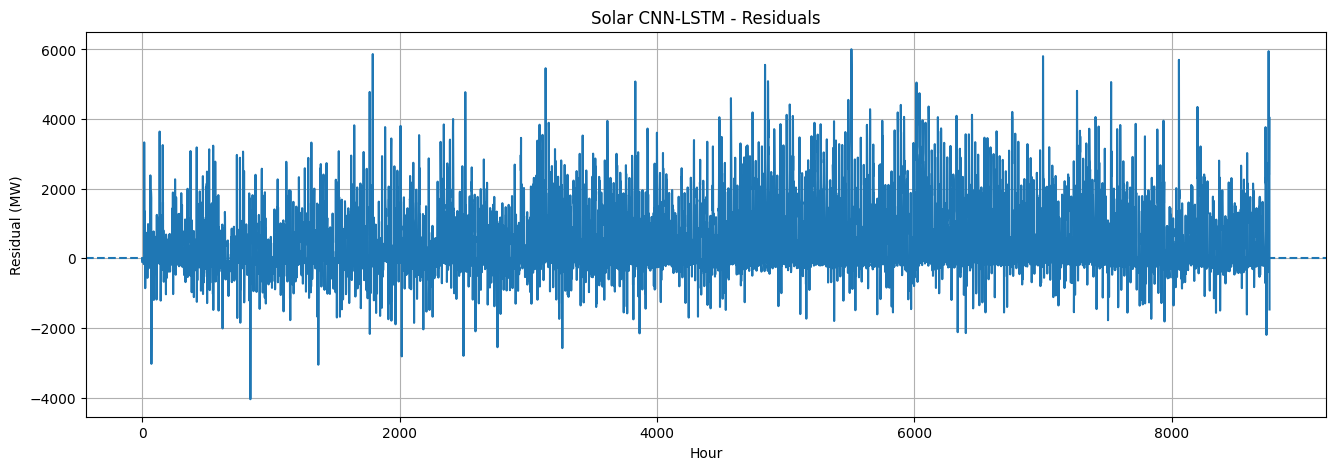

In [67]:
# Plot CNN-LSTM residual errors across the 2025 test period

plt.figure(figsize=(16, 5))

plt.plot(
    cnn_lstm_residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Hour")
plt.ylabel("Residual (MW)")

plt.title(
    "Solar CNN-LSTM - Residuals"
)

plt.grid(True)

plt.show()

# Attention-LSTM

In [68]:
# Define the Attention-LSTM hybrid forecasting model

class SolarAttentionLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2
    ):

        super(SolarAttentionLSTM, self).__init__()

        # LSTM extracts temporal representations
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Attention score for each timestep
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        # Dropout before final prediction
        self.dropout = nn.Dropout(dropout)

        # Final regression layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        # Input shape:
        # (batch, sequence_length, features)

        # LSTM output:
        # (batch, sequence_length, hidden_size)
        lstm_out, _ = self.lstm(x)

        # Calculate attention scores
        attention_scores = self.attention(lstm_out)

        # Convert scores into attention weights
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Weighted sum of all timesteps
        context = torch.sum(
            attention_weights * lstm_out,
            dim=1
        )

        # Dropout
        context = self.dropout(context)

        # Final solar prediction
        output = self.fc(context)

        return output

In [69]:
# Set the Attention-LSTM architecture parameters

INPUT_SIZE = len(FEATURES)

HIDDEN_SIZE = 128
NUM_LAYERS = 1
DROPOUT = 0.2

print("Input features :", INPUT_SIZE)
print("LSTM hidden    :", HIDDEN_SIZE)
print("LSTM layers    :", NUM_LAYERS)
print("Dropout        :", DROPOUT)

Input features : 12
LSTM hidden    : 128
LSTM layers    : 1
Dropout        : 0.2


In [70]:
# Initialize the Attention-LSTM model

attention_lstm_model = SolarAttentionLSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(attention_lstm_model)

SolarAttentionLSTM(
  (lstm): LSTM(12, 128, batch_first=True)
  (attention): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [71]:
# Count the trainable parameters in the Attention-LSTM model

attention_lstm_parameters = sum(
    p.numel()
    for p in attention_lstm_model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    attention_lstm_parameters
)

Trainable parameters: 81154


In [72]:
# Define the loss function and optimizer for Attention-LSTM

attention_lstm_criterion = nn.MSELoss()

attention_lstm_optimizer = torch.optim.Adam(
    attention_lstm_model.parameters(),
    lr=0.001
)

In [73]:
# Train the Attention-LSTM model for one complete epoch

def train_attention_lstm_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [74]:
# Train Attention-LSTM using only the 2023-2024 training data

EPOCHS = 50

attention_lstm_train_losses = []

for epoch in range(EPOCHS):

    train_loss = train_attention_lstm_epoch(
        attention_lstm_model,
        train_loader,
        attention_lstm_criterion,
        attention_lstm_optimizer,
        device
    )

    attention_lstm_train_losses.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/50] Train Loss: 0.260813
Epoch [02/50] Train Loss: 0.059498
Epoch [03/50] Train Loss: 0.040483
Epoch [04/50] Train Loss: 0.030345
Epoch [05/50] Train Loss: 0.024973
Epoch [06/50] Train Loss: 0.020875
Epoch [07/50] Train Loss: 0.017846
Epoch [08/50] Train Loss: 0.015955
Epoch [09/50] Train Loss: 0.014425
Epoch [10/50] Train Loss: 0.012938
Epoch [11/50] Train Loss: 0.012577
Epoch [12/50] Train Loss: 0.011564
Epoch [13/50] Train Loss: 0.011787
Epoch [14/50] Train Loss: 0.010937
Epoch [15/50] Train Loss: 0.010762
Epoch [16/50] Train Loss: 0.010863
Epoch [17/50] Train Loss: 0.010405
Epoch [18/50] Train Loss: 0.010575
Epoch [19/50] Train Loss: 0.009920
Epoch [20/50] Train Loss: 0.010086
Epoch [21/50] Train Loss: 0.009900
Epoch [22/50] Train Loss: 0.009463
Epoch [23/50] Train Loss: 0.009538
Epoch [24/50] Train Loss: 0.009490
Epoch [25/50] Train Loss: 0.008875
Epoch [26/50] Train Loss: 0.008753
Epoch [27/50] Train Loss: 0.009286
Epoch [28/50] Train Loss: 0.008773
Epoch [29/50] Train 

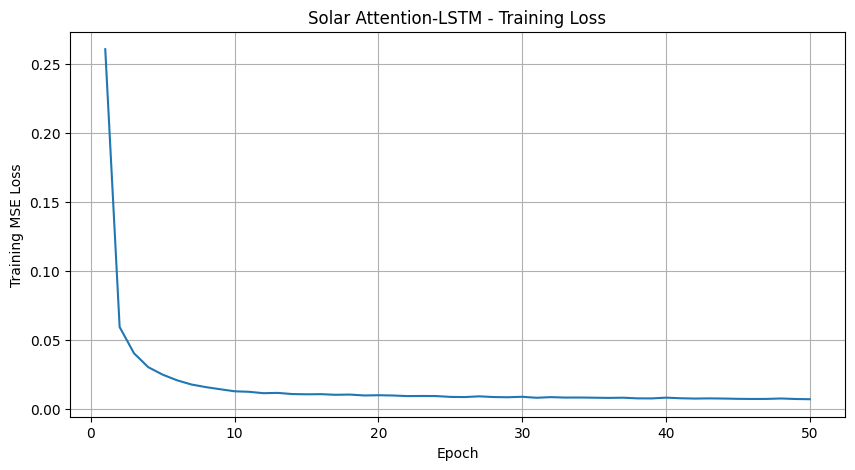

In [75]:
# Plot the Attention-LSTM training loss across epochs

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    attention_lstm_train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")

plt.title(
    "Solar Attention-LSTM - Training Loss"
)

plt.grid(True)

plt.show()

In [76]:
# Generate predictions from the trained Attention-LSTM model

def predict_attention_lstm(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(X_batch)

            predictions.append(
                outputs.cpu().numpy()
            )

            actuals.append(
                y_batch.numpy()
            )

    predictions = np.concatenate(
        predictions
    )

    actuals = np.concatenate(
        actuals
    )

    return predictions, actuals

In [77]:
# Generate predictions for the unseen 2025 test year

attention_lstm_pred_scaled, attention_lstm_actual_scaled = (
    predict_attention_lstm(
        attention_lstm_model,
        test_loader,
        device
    )
)

print(
    "Prediction shape:",
    attention_lstm_pred_scaled.shape
)

print(
    "Actual shape:",
    attention_lstm_actual_scaled.shape
)

Prediction shape: (8760, 1)
Actual shape: (8760, 1)


In [78]:
# Convert Attention-LSTM predictions back from scaled values to MW

attention_lstm_pred = target_scaler.inverse_transform(
    attention_lstm_pred_scaled
).flatten()

attention_lstm_actual = target_scaler.inverse_transform(
    attention_lstm_actual_scaled
).flatten()

print("First 10 actual values:")
print(attention_lstm_actual[:10])

print("\nFirst 10 predicted values:")
print(attention_lstm_pred[:10])

First 10 actual values:
[1.4551191e+03 5.9277344e-01 6.1669922e-01 6.8115234e-01 6.8408203e-01
 6.9531250e-01 7.0361328e-01 7.2509766e-01 7.4365234e-01 7.4267578e-01]

First 10 predicted values:
[ 1.3298823e+03  1.2071826e+02 -2.7783203e+00  9.5263672e-01
  3.0097656e+00  3.8120117e+00  5.0668945e+00  7.1542969e+00
  9.8432617e+00  1.0873047e+01]


In [79]:
# Evaluate Attention-LSTM using MAE, RMSE and R-squared

attention_lstm_mae = mean_absolute_error(
    attention_lstm_actual,
    attention_lstm_pred
)

attention_lstm_rmse = np.sqrt(
    mean_squared_error(
        attention_lstm_actual,
        attention_lstm_pred
    )
)

attention_lstm_r2 = r2_score(
    attention_lstm_actual,
    attention_lstm_pred
)

print("=" * 55)
print("SOLAR ATTENTION-LSTM RESULTS")
print("=" * 55)

print(
    f"MAE  : {attention_lstm_mae:.4f} MW"
)

print(
    f"RMSE : {attention_lstm_rmse:.4f} MW"
)

print(
    f"R²   : {attention_lstm_r2:.6f}"
)

print("=" * 55)

SOLAR ATTENTION-LSTM RESULTS
MAE  : 541.2037 MW
RMSE : 970.1069 MW
R²   : 0.989571


In [80]:
# Compare Attention-LSTM against the LSTM and CNN-LSTM models

attention_comparison = pd.DataFrame({

    'Model': [
        'LSTM Baseline',
        'CNN-LSTM',
        'Attention-LSTM'
    ],

    'MAE_MW': [
        mae,
        cnn_lstm_mae,
        attention_lstm_mae
    ],

    'RMSE_MW': [
        rmse,
        cnn_lstm_rmse,
        attention_lstm_rmse
    ],

    'R2': [
        r2,
        cnn_lstm_r2,
        attention_lstm_r2
    ]
})

display(attention_comparison)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM Baseline,513.829895,910.886656,0.990805
1,CNN-LSTM,651.140991,1077.398487,0.987136
2,Attention-LSTM,541.203674,970.106921,0.989571


In [81]:
# Calculate Attention-LSTM improvement relative to the LSTM baseline

attention_mae_improvement = (
    (mae - attention_lstm_mae) / mae
) * 100

attention_rmse_improvement = (
    (rmse - attention_lstm_rmse) / rmse
) * 100

attention_r2_improvement = (
    (attention_lstm_r2 - r2) / r2
) * 100

print(
    f"MAE improvement : "
    f"{attention_mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{attention_rmse_improvement:.2f}%"
)

print(
    f"R² improvement  : "
    f"{attention_r2_improvement:.4f}%"
)

MAE improvement : -5.33%
RMSE improvement: -6.50%
R² improvement  : -0.1246%


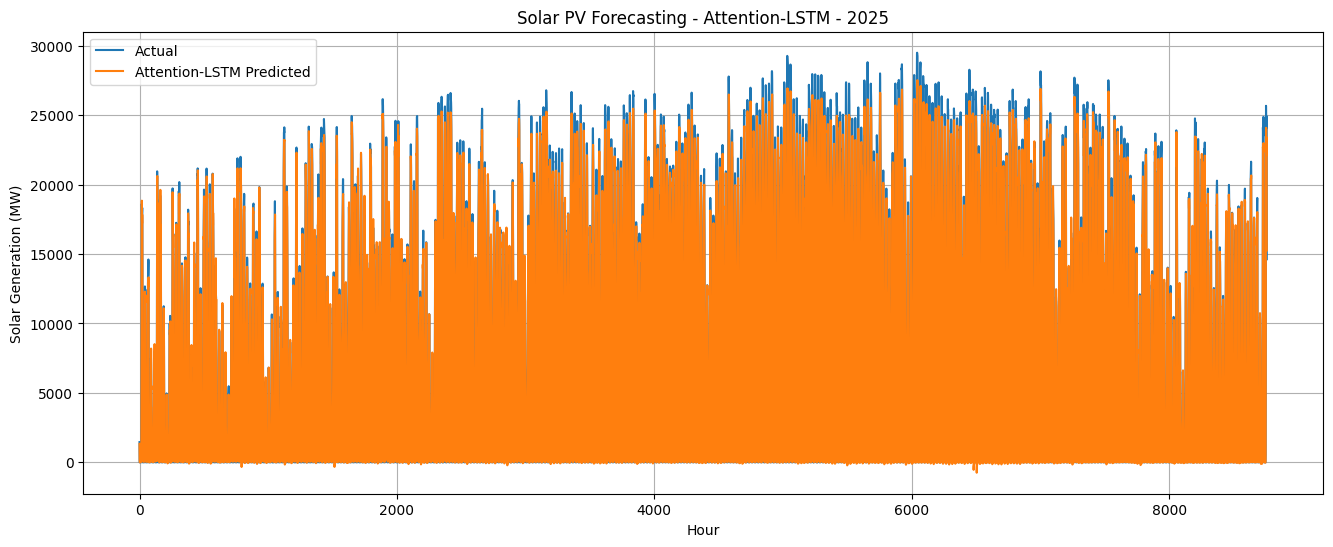

In [82]:
# Plot actual and Attention-LSTM predicted solar generation for 2025

plt.figure(figsize=(16, 6))

plt.plot(
    attention_lstm_actual,
    label='Actual'
)

plt.plot(
    attention_lstm_pred,
    label='Attention-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar PV Forecasting - Attention-LSTM - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

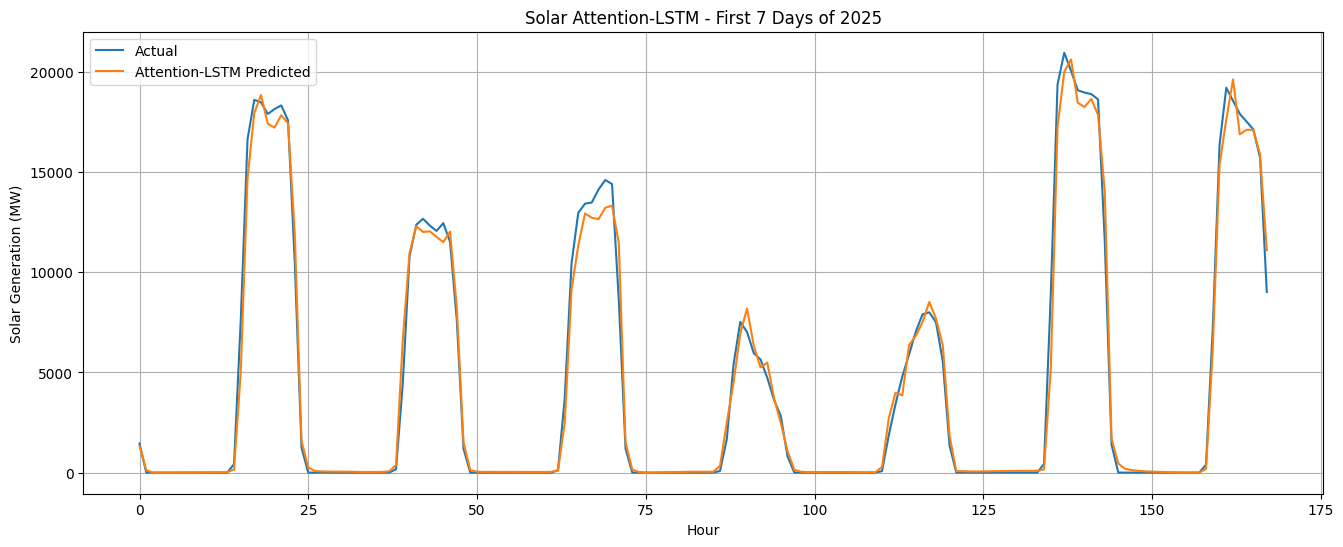

In [83]:
# Plot Attention-LSTM predictions for the first seven days of 2025

HOURS_TO_PLOT = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    attention_lstm_actual[:HOURS_TO_PLOT],
    label='Actual'
)

plt.plot(
    attention_lstm_pred[:HOURS_TO_PLOT],
    label='Attention-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Attention-LSTM - First 7 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

In [84]:
# Calculate Attention-LSTM prediction residuals for the 2025 test period

attention_lstm_residuals = (
    attention_lstm_actual -
    attention_lstm_pred
)

print(
    "Mean residual:",
    attention_lstm_residuals.mean()
)

print(
    "Residual std:",
    attention_lstm_residuals.std()
)

Mean residual: 250.18839
Residual std: 937.2903


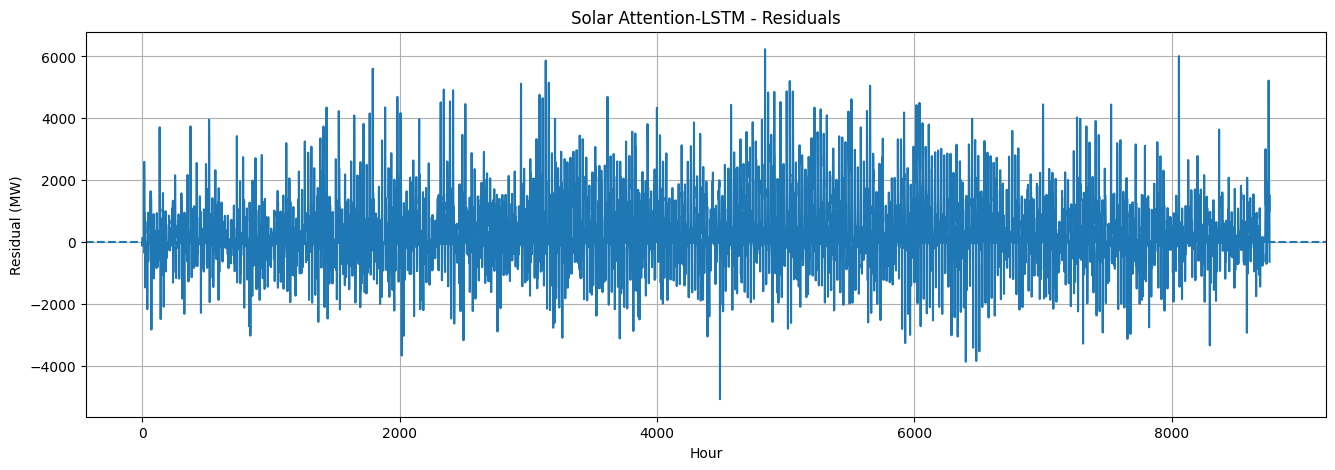

In [85]:
# Plot Attention-LSTM residual errors across the 2025 test period

plt.figure(figsize=(16, 5))

plt.plot(
    attention_lstm_residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Hour")
plt.ylabel("Residual (MW)")

plt.title(
    "Solar Attention-LSTM - Residuals"
)

plt.grid(True)

plt.show()

# Residual LSTM

In [86]:
# Generate predictions from the trained base LSTM on the training data

base_train_pred_scaled, base_train_actual_scaled = predict(
    model,
    train_loader,
    device
)

print("Base training prediction shape:", base_train_pred_scaled.shape)
print("Base training actual shape    :", base_train_actual_scaled.shape)

Base training prediction shape: (17513, 1)
Base training actual shape    : (17513, 1)


In [87]:
# Calculate the residual errors produced by the base LSTM on training data

train_residual_scaled = (
    base_train_actual_scaled -
    base_train_pred_scaled
)

print(
    "Training residual shape:",
    train_residual_scaled.shape
)

print(
    "Mean training residual:",
    train_residual_scaled.mean()
)

print(
    "Training residual std:",
    train_residual_scaled.std()
)

Training residual shape: (17513, 1)
Mean training residual: -0.01711807
Training residual std: 0.08117323


In [88]:
# Create residual targets aligned with the LSTM training sequences

residual_train_targets = train_residual_scaled.copy()

print(
    "Residual target shape:",
    residual_train_targets.shape
)

Residual target shape: (17513, 1)


In [89]:
# Create a DataLoader for Residual-LSTM training

residual_train_dataset = TensorDataset(
    X_train_tensor,
    torch.tensor(
        residual_train_targets,
        dtype=torch.float32
    )
)

residual_train_loader = DataLoader(
    residual_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print(
    "Residual training samples:",
    len(residual_train_dataset)
)

print(
    "Residual training batches:",
    len(residual_train_loader)
)

Residual training samples: 17513
Residual training batches: 274


In [90]:
# Define the Residual-LSTM model for learning base-model errors

class SolarResidualLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2
    ):

        super(SolarResidualLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        # Input:
        # (batch, sequence_length, features)

        out, _ = self.lstm(x)

        # Use the final timestep
        out = out[:, -1, :]

        out = self.dropout(out)

        # Predict residual correction
        out = self.fc(out)

        return out

In [91]:
# Set the Residual-LSTM architecture parameters

RESIDUAL_INPUT_SIZE = len(FEATURES)

RESIDUAL_HIDDEN_SIZE = 128
RESIDUAL_NUM_LAYERS = 1
RESIDUAL_DROPOUT = 0.2

print("Input features :", RESIDUAL_INPUT_SIZE)
print("Hidden neurons :", RESIDUAL_HIDDEN_SIZE)
print("LSTM layers    :", RESIDUAL_NUM_LAYERS)
print("Dropout        :", RESIDUAL_DROPOUT)

Input features : 12
Hidden neurons : 128
LSTM layers    : 1
Dropout        : 0.2


In [92]:
# Initialize the Residual-LSTM model

residual_lstm_model = SolarResidualLSTM(
    input_size=RESIDUAL_INPUT_SIZE,
    hidden_size=RESIDUAL_HIDDEN_SIZE,
    num_layers=RESIDUAL_NUM_LAYERS,
    dropout=RESIDUAL_DROPOUT
).to(device)

print(residual_lstm_model)

SolarResidualLSTM(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [93]:
# Count the trainable parameters in the Residual-LSTM

residual_parameters = sum(
    p.numel()
    for p in residual_lstm_model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    residual_parameters
)

Trainable parameters: 72833


In [94]:
# Define the loss function and optimizer for Residual-LSTM

residual_criterion = nn.MSELoss()

residual_optimizer = torch.optim.Adam(
    residual_lstm_model.parameters(),
    lr=0.001
)

In [95]:
# Train the Residual-LSTM model for one complete epoch

def train_residual_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, residual_batch in loader:

        X_batch = X_batch.to(device)
        residual_batch = residual_batch.to(device)

        optimizer.zero_grad()

        residual_prediction = model(
            X_batch
        )

        loss = criterion(
            residual_prediction,
            residual_batch
        )

        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [96]:
# Train Residual-LSTM using the base LSTM residuals from 2023-2024

EPOCHS = 50

residual_train_losses = []

for epoch in range(EPOCHS):

    train_loss = train_residual_epoch(
        residual_lstm_model,
        residual_train_loader,
        residual_criterion,
        residual_optimizer,
        device
    )

    residual_train_losses.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Residual Train Loss: {train_loss:.6f}"
    )

Epoch [01/50] Residual Train Loss: 0.007107
Epoch [02/50] Residual Train Loss: 0.006725
Epoch [03/50] Residual Train Loss: 0.006659
Epoch [04/50] Residual Train Loss: 0.006640
Epoch [05/50] Residual Train Loss: 0.006627
Epoch [06/50] Residual Train Loss: 0.006617
Epoch [07/50] Residual Train Loss: 0.006612
Epoch [08/50] Residual Train Loss: 0.006607
Epoch [09/50] Residual Train Loss: 0.006611
Epoch [10/50] Residual Train Loss: 0.006608
Epoch [11/50] Residual Train Loss: 0.006608
Epoch [12/50] Residual Train Loss: 0.006611
Epoch [13/50] Residual Train Loss: 0.006601
Epoch [14/50] Residual Train Loss: 0.006600
Epoch [15/50] Residual Train Loss: 0.006606
Epoch [16/50] Residual Train Loss: 0.006597
Epoch [17/50] Residual Train Loss: 0.006599
Epoch [18/50] Residual Train Loss: 0.006596
Epoch [19/50] Residual Train Loss: 0.006600
Epoch [20/50] Residual Train Loss: 0.006597
Epoch [21/50] Residual Train Loss: 0.006591
Epoch [22/50] Residual Train Loss: 0.006599
Epoch [23/50] Residual Train Los

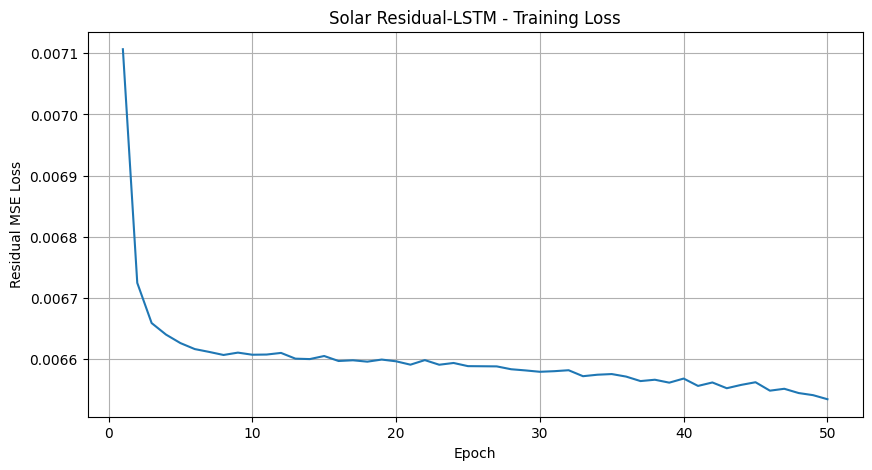

In [97]:
# Plot the Residual-LSTM training loss across epochs

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    residual_train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Residual MSE Loss")

plt.title(
    "Solar Residual-LSTM - Training Loss"
)

plt.grid(True)

plt.show()

In [98]:
# Generate the base LSTM forecast for the unseen 2025 test data

base_test_pred_scaled, base_test_actual_scaled = predict(
    model,
    test_loader,
    device
)

print(
    "Base prediction shape:",
    base_test_pred_scaled.shape
)

Base prediction shape: (8760, 1)


In [99]:
# Predict the base LSTM errors for the unseen 2025 test data

def predict_residuals(
    model,
    loader,
    device
):

    model.eval()

    residual_predictions = []

    with torch.no_grad():

        for X_batch, _ in loader:

            X_batch = X_batch.to(device)

            outputs = model(
                X_batch
            )

            residual_predictions.append(
                outputs.cpu().numpy()
            )

    residual_predictions = np.concatenate(
        residual_predictions
    )

    return residual_predictions


predicted_residual_scaled = predict_residuals(
    residual_lstm_model,
    test_loader,
    device
)

print(
    "Predicted residual shape:",
    predicted_residual_scaled.shape
)

Predicted residual shape: (8760, 1)


In [100]:
# Add the predicted residual correction to the base LSTM forecast

final_pred_scaled = (
    base_test_pred_scaled +
    predicted_residual_scaled
)

print(
    "Final prediction shape:",
    final_pred_scaled.shape
)

Final prediction shape: (8760, 1)


In [101]:
# Convert the residual-corrected forecast back to MW

residual_lstm_pred = target_scaler.inverse_transform(
    final_pred_scaled
).flatten()

residual_lstm_actual = target_scaler.inverse_transform(
    base_test_actual_scaled
).flatten()

print("First 10 actual values:")
print(residual_lstm_actual[:10])

print("\nFirst 10 Residual-LSTM values:")
print(residual_lstm_pred[:10])

First 10 actual values:
[1.4551191e+03 5.9277344e-01 6.1669922e-01 6.8115234e-01 6.8408203e-01
 6.9531250e-01 7.0361328e-01 7.2509766e-01 7.4365234e-01 7.4267578e-01]

First 10 Residual-LSTM values:
[1282.7847    811.90234   309.83252    35.546875    8.356934  -48.587402
 -125.83252  -160.81494  -181.36816  -195.44336 ]


In [102]:
# Evaluate the Residual-LSTM corrected forecast using MAE, RMSE and R-squared

residual_lstm_mae = mean_absolute_error(
    residual_lstm_actual,
    residual_lstm_pred
)

residual_lstm_rmse = np.sqrt(
    mean_squared_error(
        residual_lstm_actual,
        residual_lstm_pred
    )
)

residual_lstm_r2 = r2_score(
    residual_lstm_actual,
    residual_lstm_pred
)

print("=" * 55)
print("SOLAR RESIDUAL-LSTM RESULTS")
print("=" * 55)

print(
    f"MAE  : {residual_lstm_mae:.4f} MW"
)

print(
    f"RMSE : {residual_lstm_rmse:.4f} MW"
)

print(
    f"R²   : {residual_lstm_r2:.6f}"
)

print("=" * 55)

SOLAR RESIDUAL-LSTM RESULTS
MAE  : 536.0579 MW
RMSE : 924.4362 MW
R²   : 0.990530


In [103]:
# Compare Residual-LSTM with all previously tested models

residual_comparison = pd.DataFrame({

    'Model': [
        'LSTM Baseline',
        'CNN-LSTM',
        'Attention-LSTM',
        'Residual-LSTM'
    ],

    'MAE_MW': [
        mae,
        cnn_lstm_mae,
        attention_lstm_mae,
        residual_lstm_mae
    ],

    'RMSE_MW': [
        rmse,
        cnn_lstm_rmse,
        attention_lstm_rmse,
        residual_lstm_rmse
    ],

    'R2': [
        r2,
        cnn_lstm_r2,
        attention_lstm_r2,
        residual_lstm_r2
    ]
})

display(residual_comparison)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM Baseline,513.829895,910.886656,0.990805
1,CNN-LSTM,651.140991,1077.398487,0.987136
2,Attention-LSTM,541.203674,970.106921,0.989571
3,Residual-LSTM,536.057922,924.436247,0.990530


In [104]:
# Calculate Residual-LSTM improvement relative to the LSTM baseline

residual_mae_improvement = (
    (mae - residual_lstm_mae) / mae
) * 100

residual_rmse_improvement = (
    (rmse - residual_lstm_rmse) / rmse
) * 100

residual_r2_improvement = (
    (residual_lstm_r2 - r2) / r2
) * 100

print(
    f"MAE improvement : "
    f"{residual_mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{residual_rmse_improvement:.2f}%"
)

print(
    f"R² improvement  : "
    f"{residual_r2_improvement:.4f}%"
)

MAE improvement : -4.33%
RMSE improvement: -1.49%
R² improvement  : -0.0278%


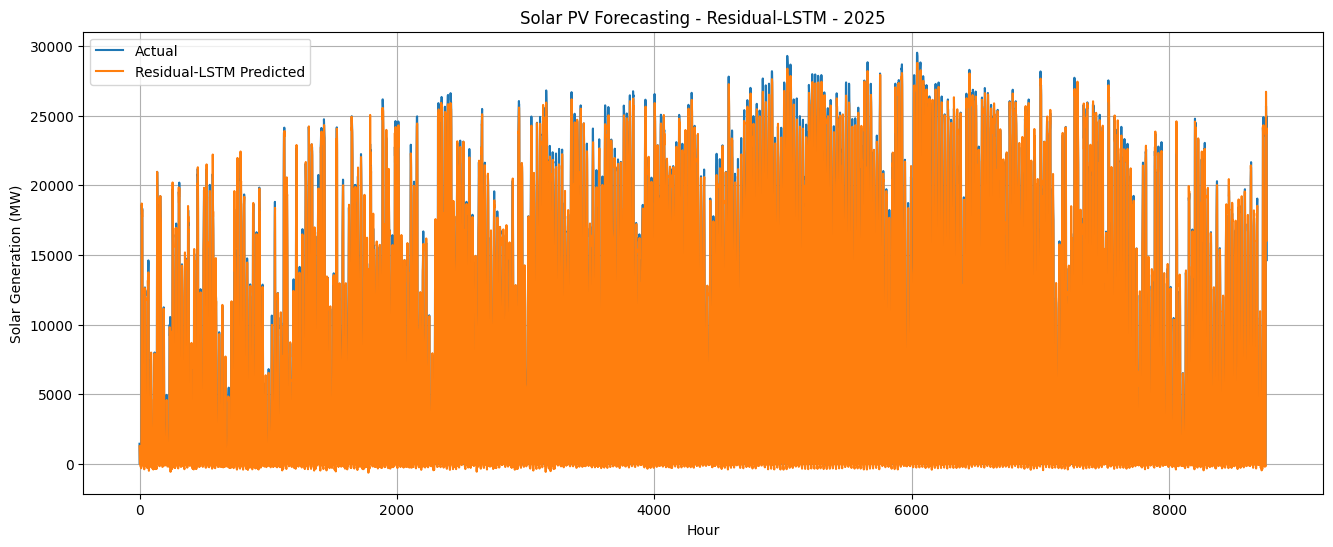

In [105]:
# Plot actual and Residual-LSTM predicted solar generation for 2025

plt.figure(figsize=(16, 6))

plt.plot(
    residual_lstm_actual,
    label='Actual'
)

plt.plot(
    residual_lstm_pred,
    label='Residual-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar PV Forecasting - Residual-LSTM - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

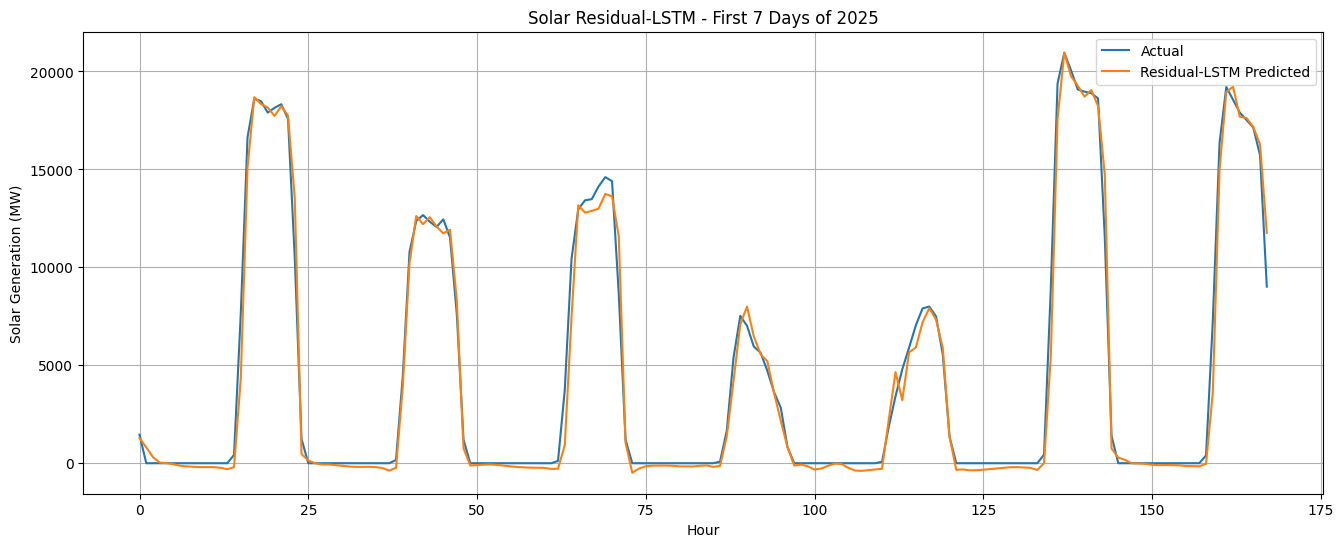

In [106]:
# Plot Residual-LSTM predictions for the first seven days of 2025

HOURS_TO_PLOT = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    residual_lstm_actual[:HOURS_TO_PLOT],
    label='Actual'
)

plt.plot(
    residual_lstm_pred[:HOURS_TO_PLOT],
    label='Residual-LSTM Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM - First 7 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

In [107]:
# Calculate final Residual-LSTM prediction errors for the 2025 test period

residual_lstm_errors = (
    residual_lstm_actual -
    residual_lstm_pred
)

print(
    "Mean residual:",
    residual_lstm_errors.mean()
)

print(
    "Residual std:",
    residual_lstm_errors.std()
)

Mean residual: 212.75186
Residual std: 899.6216


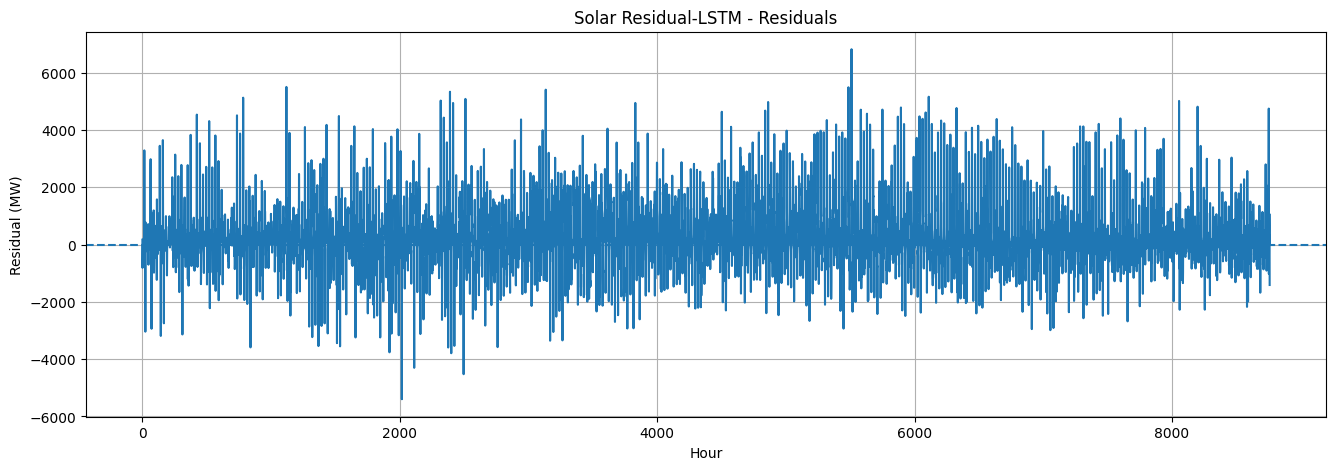

In [108]:
# Plot Residual-LSTM errors across the 2025 test period

plt.figure(figsize=(16, 5))

plt.plot(
    residual_lstm_errors
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Hour")
plt.ylabel("Residual (MW)")

plt.title(
    "Solar Residual-LSTM - Residuals"
)

plt.grid(True)

plt.show()

# non negative LSTM-Residual

In [109]:
# Apply a non-negative physical constraint to the final solar forecast

# Find the scaled value corresponding to 0 MW
zero_scaled = target_scaler.transform(
    np.array([[0.0]])
)[0, 0]

# Base forecast + predicted residual
final_pred_scaled = (
    base_test_pred_scaled +
    predicted_residual_scaled
)

# Prevent the final forecast from going below 0 MW
final_pred_scaled = np.maximum(
    final_pred_scaled,
    zero_scaled
)

print("Scaled zero threshold:", zero_scaled)

Scaled zero threshold: -0.7735054290103056


In [110]:
# Convert the non-negative Residual-LSTM forecast back to MW

residual_lstm_pred = target_scaler.inverse_transform(
    final_pred_scaled
).flatten()

residual_lstm_actual = target_scaler.inverse_transform(
    base_test_actual_scaled
).flatten()

print("Minimum predicted solar generation:",
      residual_lstm_pred.min())

print("Maximum predicted solar generation:",
      residual_lstm_pred.max())

Minimum predicted solar generation: 0.0
Maximum predicted solar generation: 28766.978487553813


In [111]:
# Evaluate the non-negative Residual-LSTM forecast

residual_lstm_mae = mean_absolute_error(
    residual_lstm_actual,
    residual_lstm_pred
)

residual_lstm_rmse = np.sqrt(
    mean_squared_error(
        residual_lstm_actual,
        residual_lstm_pred
    )
)

residual_lstm_r2 = r2_score(
    residual_lstm_actual,
    residual_lstm_pred
)

print("=" * 55)
print("SOLAR RESIDUAL-LSTM WITH NON-NEGATIVE CONSTRAINT")
print("=" * 55)

print(
    f"MAE  : {residual_lstm_mae:.4f} MW"
)

print(
    f"RMSE : {residual_lstm_rmse:.4f} MW"
)

print(
    f"R²   : {residual_lstm_r2:.6f}"
)

print("=" * 55)

SOLAR RESIDUAL-LSTM WITH NON-NEGATIVE CONSTRAINT
MAE  : 483.3971 MW
RMSE : 918.3333 MW
R²   : 0.990654


In [112]:
# Compare the constrained Residual-LSTM with all previous models

residual_comparison = pd.DataFrame({

    'Model': [
        'LSTM Baseline',
        'CNN-LSTM',
        'Attention-LSTM',
        'Residual-LSTM',
        'Residual-LSTM + Non-Negative'
    ],

    'MAE_MW': [
        mae,
        cnn_lstm_mae,
        attention_lstm_mae,
        536.057922,
        residual_lstm_mae
    ],

    'RMSE_MW': [
        rmse,
        cnn_lstm_rmse,
        attention_lstm_rmse,
        924.436247,
        residual_lstm_rmse
    ],

    'R2': [
        r2,
        cnn_lstm_r2,
        attention_lstm_r2,
        0.990530,
        residual_lstm_r2
    ]
})

display(residual_comparison)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM Baseline,513.829895,910.886656,0.990805
1,CNN-LSTM,651.140991,1077.398487,0.987136
2,Attention-LSTM,541.203674,970.106921,0.989571
3,Residual-LSTM,536.057922,924.436247,0.990530
4,Residual-LSTM + Non-Negative,483.397096,918.333284,0.990654


In [113]:
# Calculate improvement of the constrained Residual-LSTM over the baseline

residual_mae_improvement = (
    (mae - residual_lstm_mae) / mae
) * 100

residual_rmse_improvement = (
    (rmse - residual_lstm_rmse) / rmse
) * 100

residual_r2_improvement = (
    (residual_lstm_r2 - r2) / r2
) * 100

print(
    f"MAE improvement : "
    f"{residual_mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{residual_rmse_improvement:.2f}%"
)

print(
    f"R² improvement  : "
    f"{residual_r2_improvement:.4f}%"
)

MAE improvement : 5.92%
RMSE improvement: -0.82%
R² improvement  : -0.0152%


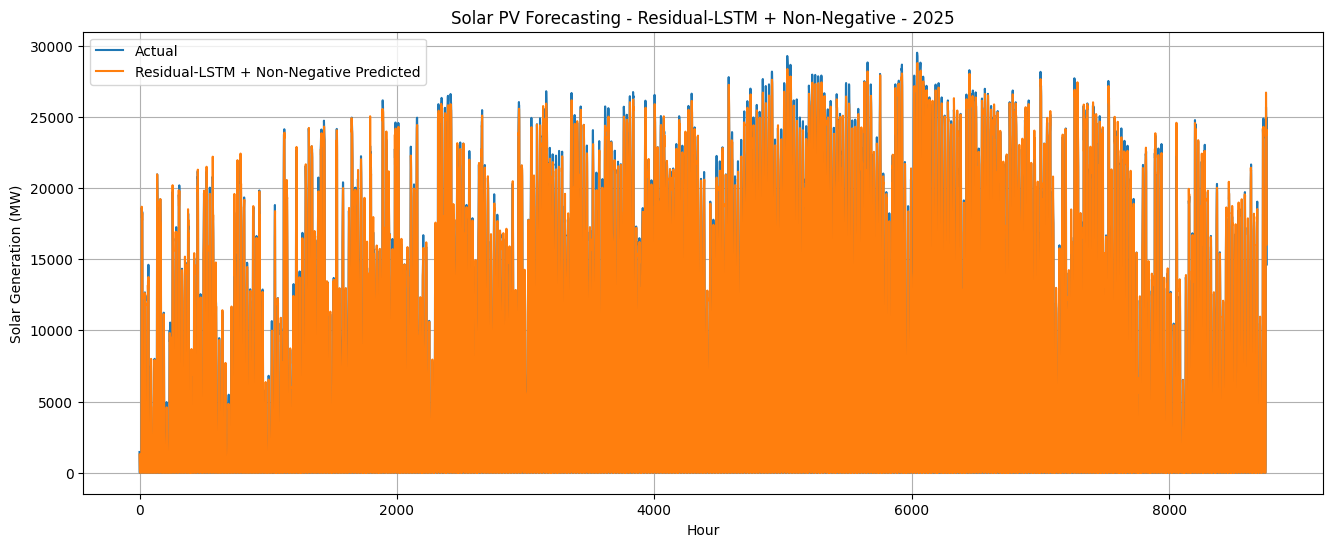

In [114]:
# Plot the final non-negative Residual-LSTM prediction for 2025

plt.figure(figsize=(16, 6))

plt.plot(
    residual_lstm_actual,
    label='Actual'
)

plt.plot(
    residual_lstm_pred,
    label='Residual-LSTM + Non-Negative Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar PV Forecasting - Residual-LSTM + Non-Negative - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

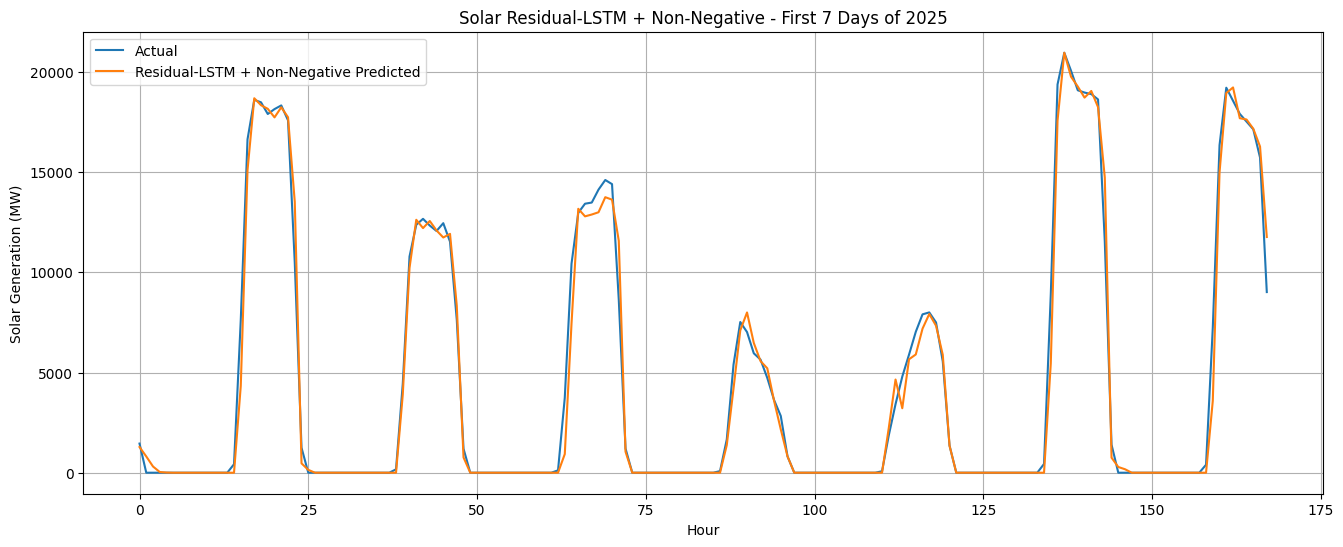

In [115]:
# Plot the final non-negative Residual-LSTM prediction for the first seven days

HOURS_TO_PLOT = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    residual_lstm_actual[:HOURS_TO_PLOT],
    label='Actual'
)

plt.plot(
    residual_lstm_pred[:HOURS_TO_PLOT],
    label='Residual-LSTM + Non-Negative Predicted'
)

plt.xlabel("Hour")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM + Non-Negative - First 7 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

In [116]:
# Calculate residual errors of the final non-negative forecast

residual_lstm_errors = (
    residual_lstm_actual -
    residual_lstm_pred
)

print(
    "Mean residual:",
    residual_lstm_errors.mean()
)

print(
    "Residual std:",
    residual_lstm_errors.std()
)

Mean residual: 160.09117914028124
Residual std: 904.2714382497113


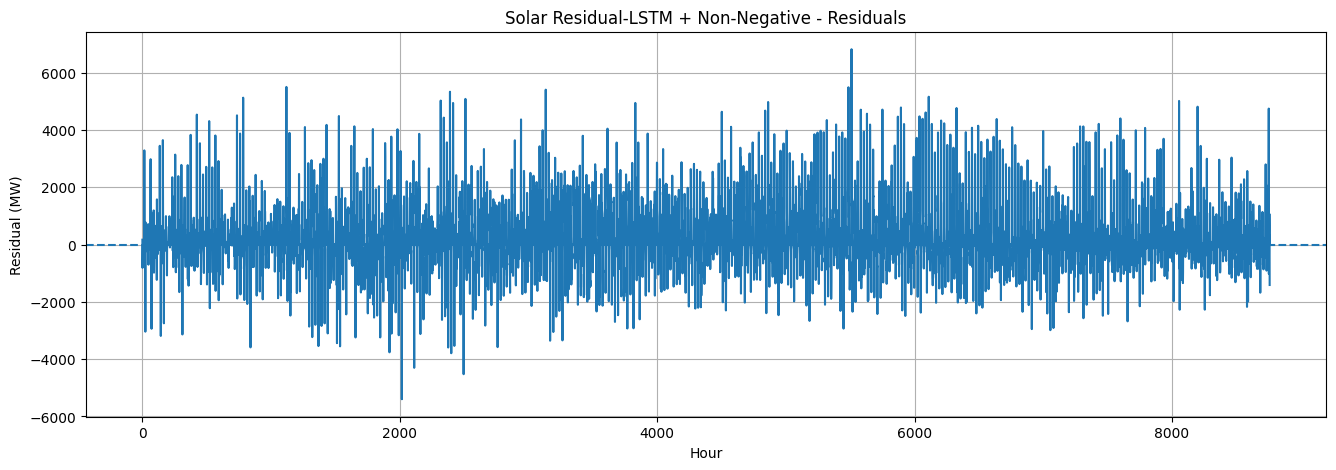

In [117]:
# Plot residual errors of the final non-negative Residual-LSTM

plt.figure(figsize=(16, 5))

plt.plot(
    residual_lstm_errors
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Hour")
plt.ylabel("Residual (MW)")

plt.title(
    "Solar Residual-LSTM + Non-Negative - Residuals"
)

plt.grid(True)

plt.show()

# Baseline LSTM 6 hour

In [134]:
# Set the forecasting parameters for 6-hour ahead prediction

LOOKBACK_6H = 24
HORIZON_6H = 6

print("Lookback :", LOOKBACK_6H, "hours")
print("Horizon  :", HORIZON_6H, "hours")

Lookback : 24 hours
Horizon  : 6 hours


In [135]:
# Create 24-hour input sequences with 6-hour future targets for training

def create_multistep_sequences(
    X,
    y,
    lookback,
    horizon
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X) - horizon + 1
    ):

        X_seq.append(
            X[i - lookback:i]
        )

        y_seq.append(
            y[i:i + horizon].flatten()
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


X_train_6h, y_train_6h = create_multistep_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK_6H,
    HORIZON_6H
)

print("X_train_6h:", X_train_6h.shape)
print("y_train_6h:", y_train_6h.shape)

X_train_6h: (17508, 24, 12)
y_train_6h: (17508, 6)


In [136]:
# Create 6-hour test sequences using late-2024 history for the first 2025 forecast

X_combined_6h = np.concatenate(
    [X_train_scaled, X_test_scaled],
    axis=0
)

y_combined_6h = np.concatenate(
    [y_train_scaled, y_test_scaled],
    axis=0
)

train_size_6h = len(X_train_scaled)

X_test_6h = []
y_test_6h = []

for i in range(
    train_size_6h,
    len(X_combined_6h) - HORIZON_6H + 1
):

    X_test_6h.append(
        X_combined_6h[
            i - LOOKBACK_6H:i
        ]
    )

    y_test_6h.append(
        y_combined_6h[
            i:i + HORIZON_6H
        ].flatten()
    )

X_test_6h = np.array(X_test_6h)
y_test_6h = np.array(y_test_6h)

print("X_test_6h:", X_test_6h.shape)
print("y_test_6h:", y_test_6h.shape)

X_test_6h: (8755, 24, 12)
y_test_6h: (8755, 6)


In [137]:
# Verify the first and last 6-hour forecast target periods

print("First 6-hour forecast:")

print(
    test_df['Datetime_UTC'].iloc[0]
)

print(
    "→",
    test_df['Datetime_UTC'].iloc[5]
)

print("\nLast complete 6-hour forecast:")

print(
    test_df['Datetime_UTC'].iloc[-6]
)

print(
    "→",
    test_df['Datetime_UTC'].iloc[-1]
)

print(
    "\nNumber of 6-hour forecasts:",
    len(y_test_6h)
)

First 6-hour forecast:
2025-01-01 00:00:00+00:00
→ 2025-01-01 05:00:00+00:00

Last complete 6-hour forecast:
2025-12-31 18:00:00+00:00
→ 2025-12-31 23:00:00+00:00

Number of 6-hour forecasts: 8755


In [138]:
# Convert the 6-hour sequence data into PyTorch tensors

X_train_6h_tensor = torch.tensor(
    X_train_6h,
    dtype=torch.float32
)

y_train_6h_tensor = torch.tensor(
    y_train_6h,
    dtype=torch.float32
)

X_test_6h_tensor = torch.tensor(
    X_test_6h,
    dtype=torch.float32
)

y_test_6h_tensor = torch.tensor(
    y_test_6h,
    dtype=torch.float32
)

print(
    "X_train:",
    X_train_6h_tensor.shape
)

print(
    "y_train:",
    y_train_6h_tensor.shape
)

print(
    "X_test :",
    X_test_6h_tensor.shape
)

print(
    "y_test :",
    y_test_6h_tensor.shape
)

X_train: torch.Size([17508, 24, 12])
y_train: torch.Size([17508, 6])
X_test : torch.Size([8755, 24, 12])
y_test : torch.Size([8755, 6])


In [139]:
# Create DataLoaders for 6-hour LSTM forecasting

BATCH_SIZE_6H = 64

train_dataset_6h = TensorDataset(
    X_train_6h_tensor,
    y_train_6h_tensor
)

test_dataset_6h = TensorDataset(
    X_test_6h_tensor,
    y_test_6h_tensor
)

train_loader_6h = DataLoader(
    train_dataset_6h,
    batch_size=BATCH_SIZE_6H,
    shuffle=True
)

test_loader_6h = DataLoader(
    test_dataset_6h,
    batch_size=BATCH_SIZE_6H,
    shuffle=False
)

print(
    "Training batches:",
    len(train_loader_6h)
)

print(
    "Testing batches :",
    len(test_loader_6h)
)

Training batches: 274
Testing batches : 137


In [140]:
# Define the baseline LSTM model for 6-hour multi-output forecasting

class SolarLSTM6H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=6
    ):

        super(SolarLSTM6H, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        out, _ = self.lstm(x)

        # Use the final timestep representation
        out = out[:, -1, :]

        out = self.dropout(out)

        # Predict the next 6 hours simultaneously
        out = self.fc(out)

        return out

In [141]:
# Initialize the 6-hour baseline LSTM

INPUT_SIZE_6H = len(FEATURES)

HIDDEN_SIZE_6H = 128
NUM_LAYERS_6H = 1
DROPOUT_6H = 0.2

model_6h = SolarLSTM6H(
    input_size=INPUT_SIZE_6H,
    hidden_size=HIDDEN_SIZE_6H,
    num_layers=NUM_LAYERS_6H,
    dropout=DROPOUT_6H,
    horizon=HORIZON_6H
).to(device)

print(model_6h)

SolarLSTM6H(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [142]:
# Count the trainable parameters in the 6-hour baseline model

parameters_6h = sum(
    p.numel()
    for p in model_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    parameters_6h
)

Trainable parameters: 73478


In [143]:
# Define the loss function and optimizer for the 6-hour baseline

criterion_6h = nn.MSELoss()

optimizer_6h = torch.optim.Adam(
    model_6h.parameters(),
    lr=0.001
)

In [144]:
# Train the 6-hour LSTM for one complete epoch

def train_epoch_6h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [145]:
# Train the 6-hour baseline LSTM for 25 epochs

EPOCHS_6H = 25

train_losses_6h = []

for epoch in range(EPOCHS_6H):

    train_loss = train_epoch_6h(
        model_6h,
        train_loader_6h,
        criterion_6h,
        optimizer_6h,
        device
    )

    train_losses_6h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_6H}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/25] Train Loss: 0.204988
Epoch [02/25] Train Loss: 0.075508
Epoch [03/25] Train Loss: 0.059736
Epoch [04/25] Train Loss: 0.054257
Epoch [05/25] Train Loss: 0.048031
Epoch [06/25] Train Loss: 0.046425
Epoch [07/25] Train Loss: 0.044525
Epoch [08/25] Train Loss: 0.041005
Epoch [09/25] Train Loss: 0.040262
Epoch [10/25] Train Loss: 0.038594
Epoch [11/25] Train Loss: 0.038574
Epoch [12/25] Train Loss: 0.036780
Epoch [13/25] Train Loss: 0.035554
Epoch [14/25] Train Loss: 0.035117
Epoch [15/25] Train Loss: 0.034916
Epoch [16/25] Train Loss: 0.034139
Epoch [17/25] Train Loss: 0.032550
Epoch [18/25] Train Loss: 0.031461
Epoch [19/25] Train Loss: 0.031330
Epoch [20/25] Train Loss: 0.030694
Epoch [21/25] Train Loss: 0.030004
Epoch [22/25] Train Loss: 0.029438
Epoch [23/25] Train Loss: 0.029895
Epoch [24/25] Train Loss: 0.028472
Epoch [25/25] Train Loss: 0.028391


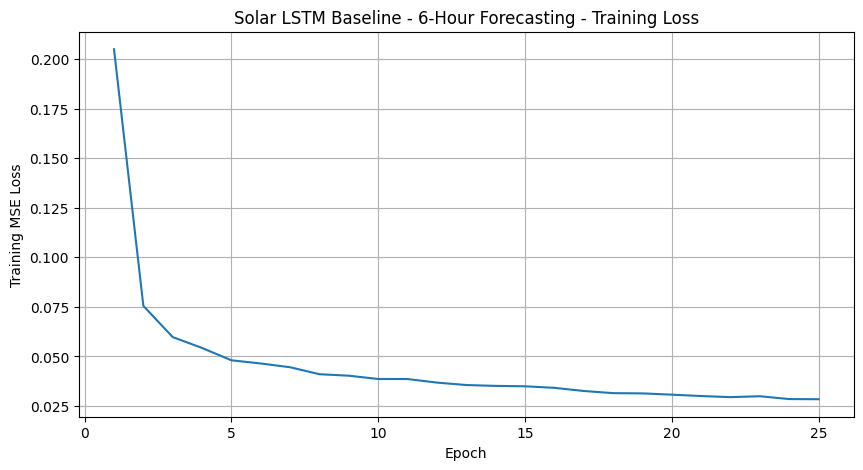

In [146]:
# Plot the 6-hour LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS_6H + 1),
    train_losses_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")

plt.title(
    "Solar LSTM Baseline - 6-Hour Forecasting - Training Loss"
)

plt.grid(True)

plt.show()

In [147]:
# Generate 6-hour predictions from the trained LSTM

def predict_6h(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(
                X_batch
            )

            predictions.append(
                outputs.cpu().numpy()
            )

            actuals.append(
                y_batch.numpy()
            )

    predictions = np.concatenate(
        predictions,
        axis=0
    )

    actuals = np.concatenate(
        actuals,
        axis=0
    )

    return predictions, actuals

In [148]:
# Generate 6-hour forecasts for the unseen 2025 test year

pred_6h_scaled, actual_6h_scaled = predict_6h(
    model_6h,
    test_loader_6h,
    device
)

print(
    "Prediction shape:",
    pred_6h_scaled.shape
)

print(
    "Actual shape    :",
    actual_6h_scaled.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [149]:
# Convert the 6-hour predictions and actual values back to MW

pred_6h = target_scaler.inverse_transform(
    pred_6h_scaled
)

actual_6h = target_scaler.inverse_transform(
    actual_6h_scaled
)

print(
    "Prediction shape:",
    pred_6h.shape
)

print(
    "Actual shape    :",
    actual_6h.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [150]:
# Evaluate overall 6-hour forecasting performance

pred_6h_flat = pred_6h.flatten()
actual_6h_flat = actual_6h.flatten()

mae_6h = mean_absolute_error(
    actual_6h_flat,
    pred_6h_flat
)

rmse_6h = np.sqrt(
    mean_squared_error(
        actual_6h_flat,
        pred_6h_flat
    )
)

r2_6h = r2_score(
    actual_6h_flat,
    pred_6h_flat
)

print("=" * 55)
print("SOLAR LSTM BASELINE - 6 HOUR FORECAST")
print("=" * 55)

print(
    f"MAE  : {mae_6h:.4f} MW"
)

print(
    f"RMSE : {rmse_6h:.4f} MW"
)

print(
    f"R²   : {r2_6h:.6f}"
)

print("=" * 55)

SOLAR LSTM BASELINE - 6 HOUR FORECAST
MAE  : 1447.9324 MW
RMSE : 2552.1136 MW
R²   : 0.927804


In [151]:
# Calculate forecasting performance separately for each future hour

horizon_results_6h = []

for h in range(HORIZON_6H):

    h_actual = actual_6h[:, h]
    h_pred = pred_6h[:, h]

    h_mae = mean_absolute_error(
        h_actual,
        h_pred
    )

    h_rmse = np.sqrt(
        mean_squared_error(
            h_actual,
            h_pred
        )
    )

    h_r2 = r2_score(
        h_actual,
        h_pred
    )

    horizon_results_6h.append({
        "Horizon": f"t+{h + 1}",
        "MAE_MW": h_mae,
        "RMSE_MW": h_rmse,
        "R2": h_r2
    })

horizon_results_6h = pd.DataFrame(
    horizon_results_6h
)

display(
    horizon_results_6h
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,762.974060,1263.899472,0.982282
1,t+2,1135.715576,1946.319218,0.957995
2,t+3,1410.050293,2395.409464,0.936391
3,t+4,1621.981323,2754.742638,0.915901
4,t+5,1803.149170,3065.296886,0.895899
5,t+6,1953.723999,3312.320486,0.878443


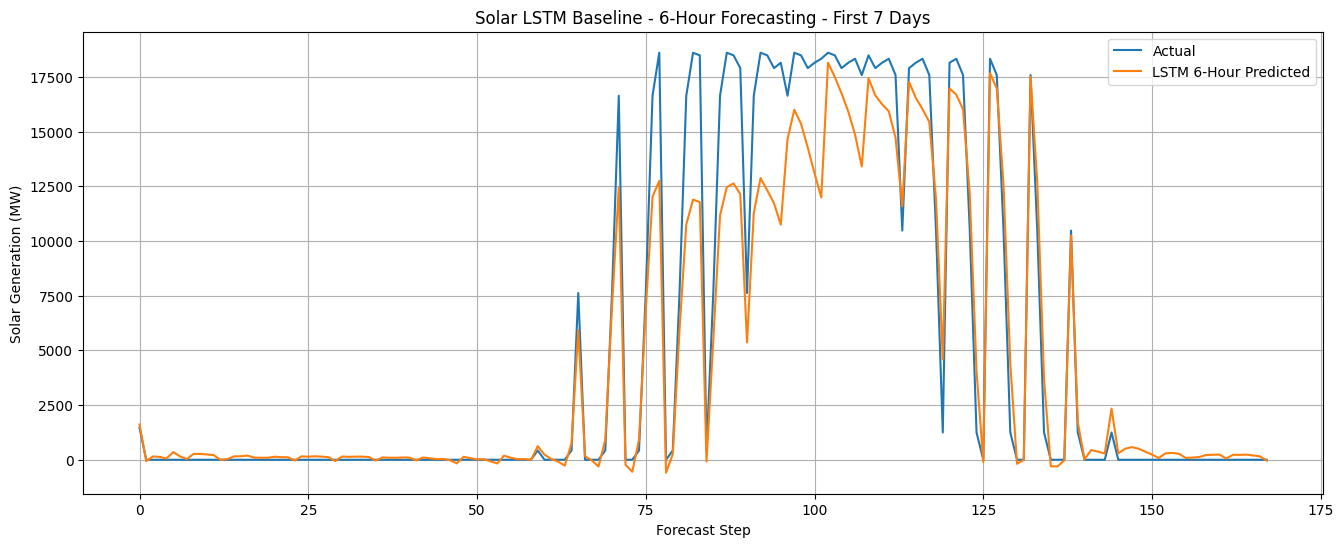

In [152]:
# Plot the 6-hour-ahead forecast against actual solar generation for the first seven days

HOURS_TO_PLOT_6H = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    actual_6h_flat[:HOURS_TO_PLOT_6H],
    label='Actual'
)

plt.plot(
    pred_6h_flat[:HOURS_TO_PLOT_6H],
    label='LSTM 6-Hour Predicted'
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar LSTM Baseline - 6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

In [153]:
# Calculate residual errors for the 6-hour baseline forecasts

residuals_6h = (
    actual_6h_flat -
    pred_6h_flat
)

print(
    "Mean residual:",
    residuals_6h.mean()
)

print(
    "Residual std:",
    residuals_6h.std()
)

Mean residual: 946.36035
Residual std: 2370.166


# Residual - LSTM 6 hrs

In [154]:
# Generate 6-hour baseline predictions on the training data

model_6h.eval()

base_train_pred_6h_scaled = []
base_train_actual_6h_scaled = []

with torch.no_grad():

    for X_batch, y_batch in train_loader_6h:

        X_batch = X_batch.to(device)

        outputs = model_6h(X_batch)

        base_train_pred_6h_scaled.append(
            outputs.cpu().numpy()
        )

        base_train_actual_6h_scaled.append(
            y_batch.numpy()
        )

base_train_pred_6h_scaled = np.concatenate(
    base_train_pred_6h_scaled,
    axis=0
)

base_train_actual_6h_scaled = np.concatenate(
    base_train_actual_6h_scaled,
    axis=0
)

print(
    "Base training prediction shape:",
    base_train_pred_6h_scaled.shape
)

print(
    "Base training actual shape    :",
    base_train_actual_6h_scaled.shape
)

Base training prediction shape: (17508, 6)
Base training actual shape    : (17508, 6)


In [155]:
# Calculate the six-step residual targets from the baseline LSTM

residual_train_6h_scaled = (
    base_train_actual_6h_scaled -
    base_train_pred_6h_scaled
)

print(
    "Residual target shape:",
    residual_train_6h_scaled.shape
)

print(
    "Mean residual:",
    residual_train_6h_scaled.mean()
)

print(
    "Residual std:",
    residual_train_6h_scaled.std()
)

Residual target shape: (17508, 6)
Mean residual: -0.006587022
Residual std: 0.13736339


In [156]:
# Create the DataLoader for 6-hour Residual-LSTM training

residual_train_dataset_6h = TensorDataset(
    X_train_6h_tensor,
    torch.tensor(
        residual_train_6h_scaled,
        dtype=torch.float32
    )
)

residual_train_loader_6h = DataLoader(
    residual_train_dataset_6h,
    batch_size=BATCH_SIZE_6H,
    shuffle=True
)

print(
    "Residual training samples:",
    len(residual_train_dataset_6h)
)

print(
    "Residual training batches:",
    len(residual_train_loader_6h)
)

Residual training samples: 17508
Residual training batches: 274


In [157]:
# Define the 6-hour Residual-LSTM model

class SolarResidualLSTM6H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=6
    ):

        super(SolarResidualLSTM6H, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        out, _ = self.lstm(x)

        # Use the final timestep representation
        out = out[:, -1, :]

        out = self.dropout(out)

        # Predict six residual corrections
        out = self.fc(out)

        return out

In [158]:
# Initialize the 6-hour Residual-LSTM

residual_model_6h = SolarResidualLSTM6H(
    input_size=INPUT_SIZE_6H,
    hidden_size=128,
    num_layers=1,
    dropout=0.2,
    horizon=6
).to(device)

print(residual_model_6h)

SolarResidualLSTM6H(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [159]:
# Count trainable parameters in the 6-hour Residual-LSTM

residual_parameters_6h = sum(
    p.numel()
    for p in residual_model_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    residual_parameters_6h
)

Trainable parameters: 73478


In [160]:
# Define the loss function and optimizer for the 6-hour Residual-LSTM

residual_criterion_6h = nn.MSELoss()

residual_optimizer_6h = torch.optim.Adam(
    residual_model_6h.parameters(),
    lr=0.001
)

In [161]:
# Train the 6-hour Residual-LSTM for one epoch

def train_residual_epoch_6h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, residual_batch in loader:

        X_batch = X_batch.to(device)
        residual_batch = residual_batch.to(device)

        optimizer.zero_grad()

        residual_prediction = model(
            X_batch
        )

        loss = criterion(
            residual_prediction,
            residual_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [162]:
# Train the 6-hour Residual-LSTM for 25 epochs

EPOCHS_RESIDUAL_6H = 25

residual_train_losses_6h = []

for epoch in range(EPOCHS_RESIDUAL_6H):

    train_loss = train_residual_epoch_6h(
        residual_model_6h,
        residual_train_loader_6h,
        residual_criterion_6h,
        residual_optimizer_6h,
        device
    )

    residual_train_losses_6h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_RESIDUAL_6H}] "
        f"Residual Train Loss: {train_loss:.6f}"
    )

Epoch [01/25] Residual Train Loss: 0.019387
Epoch [02/25] Residual Train Loss: 0.018995
Epoch [03/25] Residual Train Loss: 0.018944
Epoch [04/25] Residual Train Loss: 0.018902
Epoch [05/25] Residual Train Loss: 0.018907
Epoch [06/25] Residual Train Loss: 0.018884
Epoch [07/25] Residual Train Loss: 0.018882
Epoch [08/25] Residual Train Loss: 0.018873
Epoch [09/25] Residual Train Loss: 0.018876
Epoch [10/25] Residual Train Loss: 0.018864
Epoch [11/25] Residual Train Loss: 0.018864
Epoch [12/25] Residual Train Loss: 0.018860
Epoch [13/25] Residual Train Loss: 0.018858
Epoch [14/25] Residual Train Loss: 0.018857
Epoch [15/25] Residual Train Loss: 0.018862
Epoch [16/25] Residual Train Loss: 0.018848
Epoch [17/25] Residual Train Loss: 0.018841
Epoch [18/25] Residual Train Loss: 0.018843
Epoch [19/25] Residual Train Loss: 0.018844
Epoch [20/25] Residual Train Loss: 0.018842
Epoch [21/25] Residual Train Loss: 0.018844
Epoch [22/25] Residual Train Loss: 0.018837
Epoch [23/25] Residual Train Los

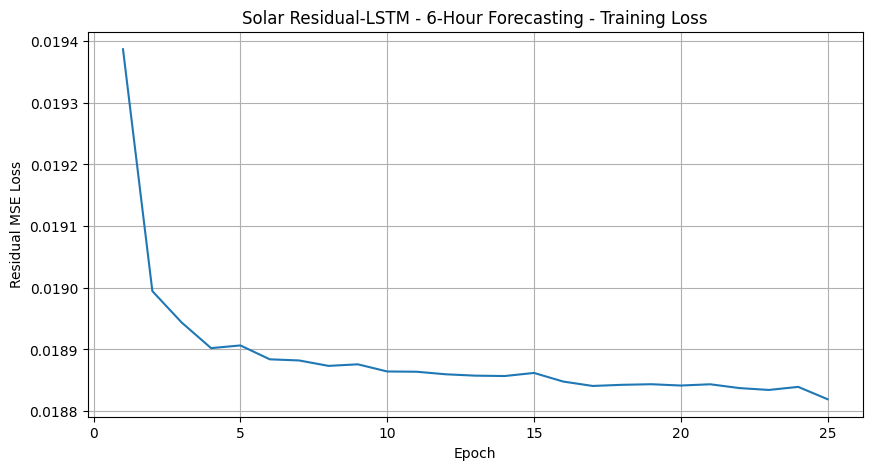

In [163]:
# Plot the 6-hour Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_6H + 1
    ),
    residual_train_losses_6h
)

plt.xlabel("Epoch")
plt.ylabel("Residual MSE Loss")

plt.title(
    "Solar Residual-LSTM - 6-Hour Forecasting - Training Loss"
)

plt.grid(True)

plt.show()

In [164]:
# Generate six-step residual corrections for the 2025 test period

residual_model_6h.eval()

predicted_residual_6h_scaled = []

with torch.no_grad():

    for X_batch, _ in test_loader_6h:

        X_batch = X_batch.to(device)

        outputs = residual_model_6h(
            X_batch
        )

        predicted_residual_6h_scaled.append(
            outputs.cpu().numpy()
        )

predicted_residual_6h_scaled = np.concatenate(
    predicted_residual_6h_scaled,
    axis=0
)

print(
    "Predicted residual shape:",
    predicted_residual_6h_scaled.shape
)

Predicted residual shape: (8755, 6)


In [165]:
# Combine the baseline forecast with the predicted residual correction

residual_pred_6h_scaled = (
    pred_6h_scaled +
    predicted_residual_6h_scaled
)

print(
    "Final Residual-LSTM prediction shape:",
    residual_pred_6h_scaled.shape
)

Final Residual-LSTM prediction shape: (8755, 6)


In [166]:
# Convert the 6-hour Residual-LSTM predictions back to MW

residual_pred_6h = target_scaler.inverse_transform(
    residual_pred_6h_scaled
)

residual_actual_6h = target_scaler.inverse_transform(
    actual_6h_scaled
)

print(
    "Prediction shape:",
    residual_pred_6h.shape
)

print(
    "Actual shape    :",
    residual_actual_6h.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [167]:
# Evaluate overall 6-hour Residual-LSTM forecasting performance

residual_pred_6h_flat = (
    residual_pred_6h.flatten()
)

residual_actual_6h_flat = (
    residual_actual_6h.flatten()
)

residual_mae_6h = mean_absolute_error(
    residual_actual_6h_flat,
    residual_pred_6h_flat
)

residual_rmse_6h = np.sqrt(
    mean_squared_error(
        residual_actual_6h_flat,
        residual_pred_6h_flat
    )
)

residual_r2_6h = r2_score(
    residual_actual_6h_flat,
    residual_pred_6h_flat
)

print("=" * 60)
print("SOLAR RESIDUAL-LSTM - 6 HOUR FORECAST")
print("=" * 60)

print(
    f"MAE  : {residual_mae_6h:.4f} MW"
)

print(
    f"RMSE : {residual_rmse_6h:.4f} MW"
)

print(
    f"R²   : {residual_r2_6h:.6f}"
)

print("=" * 60)

SOLAR RESIDUAL-LSTM - 6 HOUR FORECAST
MAE  : 1454.2849 MW
RMSE : 2562.0769 MW
R²   : 0.927239


In [168]:
# Compare the 6-hour Residual-LSTM with the 6-hour baseline

print(
    f"MAE improvement : "
    f"{((mae_6h - residual_mae_6h) / mae_6h) * 100:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{((rmse_6h - residual_rmse_6h) / rmse_6h) * 100:.2f}%"
)

print(
    f"R² improvement  : "
    f"{((residual_r2_6h - r2_6h) / r2_6h) * 100:.4f}%"
)

MAE improvement : -0.44%
RMSE improvement: -0.39%
R² improvement  : -0.0609%


In [169]:
# Compare baseline and Residual-LSTM performance at every forecast horizon

residual_horizon_results_6h = []

for h in range(HORIZON_6H):

    actual_h = residual_actual_6h[:, h]

    baseline_h = pred_6h[:, h]

    residual_h = residual_pred_6h[:, h]

    baseline_mae = mean_absolute_error(
        actual_h,
        baseline_h
    )

    residual_mae = mean_absolute_error(
        actual_h,
        residual_h
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            baseline_h
        )
    )

    residual_rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            residual_h
        )
    )

    baseline_r2 = r2_score(
        actual_h,
        baseline_h
    )

    residual_r2 = r2_score(
        actual_h,
        residual_h
    )

    residual_horizon_results_6h.append({

        "Horizon": f"t+{h + 1}",

        "Baseline_MAE": baseline_mae,

        "Residual_MAE": residual_mae,

        "Baseline_RMSE": baseline_rmse,

        "Residual_RMSE": residual_rmse,

        "Baseline_R2": baseline_r2,

        "Residual_R2": residual_r2
    })

residual_horizon_results_6h = pd.DataFrame(
    residual_horizon_results_6h
)

display(
    residual_horizon_results_6h
)

,Horizon,Baseline_MAE,Residual_MAE,Baseline_RMSE,Residual_RMSE,Baseline_R2,Residual_R2
0,t+1,762.974060,764.661194,1263.899472,1268.507883,0.982282,0.982152
1,t+2,1135.715576,1140.309326,1946.319218,1959.251132,0.957995,0.957435
2,t+3,1410.050293,1420.604858,2395.409464,2419.115851,0.936391,0.935126
3,t+4,1621.981323,1629.742676,2754.742638,2774.509236,0.915901,0.914690
4,t+5,1803.149170,1811.783813,3065.296886,3066.650290,0.895899,0.895807
5,t+6,1953.723999,1958.608154,3312.320486,3314.103951,0.878443,0.878312


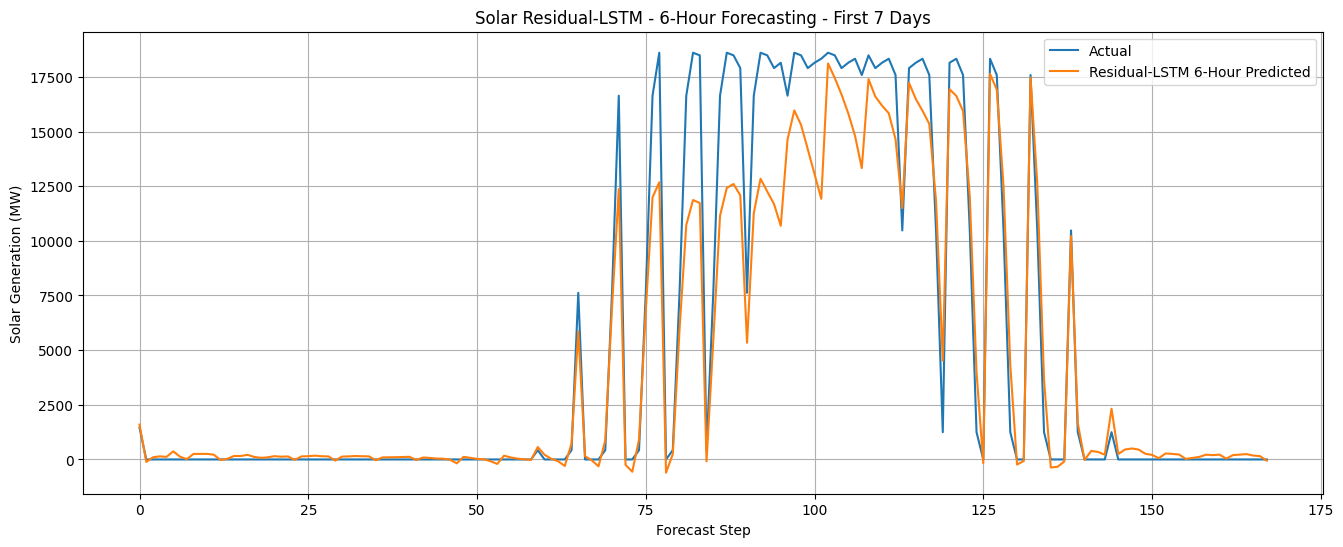

In [170]:
# Plot the 6-hour Residual-LSTM forecast for the first seven days

HOURS_TO_PLOT_RESIDUAL_6H = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    residual_actual_6h_flat[
        :HOURS_TO_PLOT_RESIDUAL_6H
    ],
    label='Actual'
)

plt.plot(
    residual_pred_6h_flat[
        :HOURS_TO_PLOT_RESIDUAL_6H
    ],
    label='Residual-LSTM 6-Hour Predicted'
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM - 6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

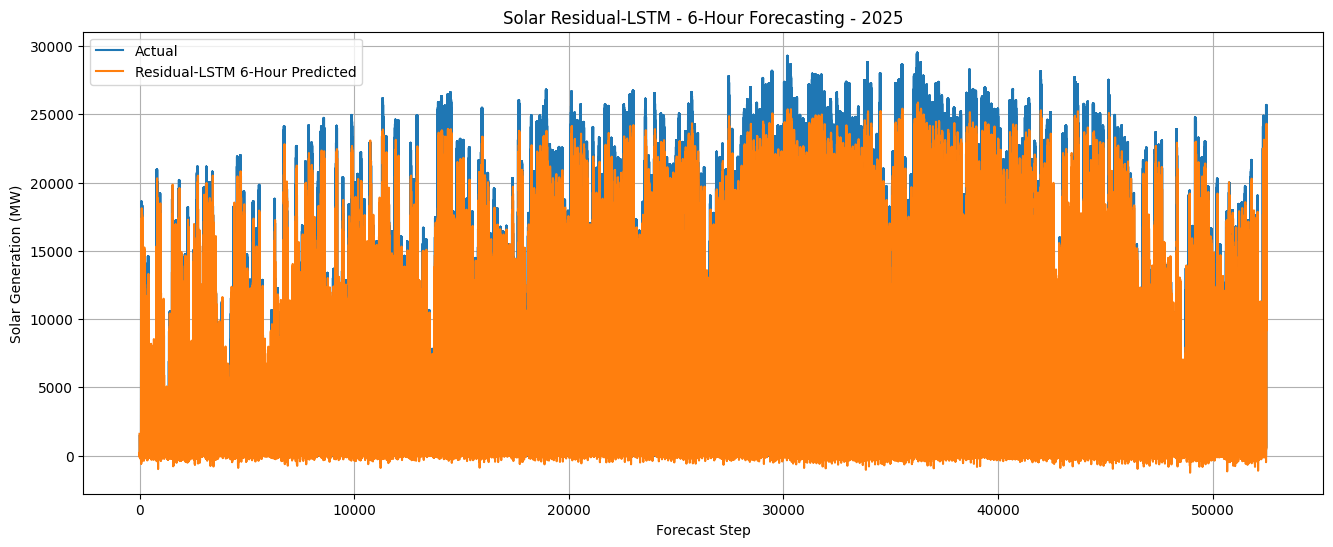

In [171]:
# Plot the complete 2025 Residual-LSTM 6-hour forecasts

plt.figure(figsize=(16, 6))

plt.plot(
    residual_actual_6h_flat,
    label='Actual'
)

plt.plot(
    residual_pred_6h_flat,
    label='Residual-LSTM 6-Hour Predicted'
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM - 6-Hour Forecasting - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

# CNN - LSTM 6hrs

In [172]:
# Define the CNN-LSTM model for 6-hour multi-step solar forecasting

class SolarCNNLSTM6H(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_filters_1=32,
        cnn_filters_2=64,
        kernel_size=3,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=6
    ):

        super(SolarCNNLSTM6H, self).__init__()

        # CNN extracts local temporal patterns
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_filters_1,
            kernel_size=kernel_size,
            padding=1
        )

        self.conv2 = nn.Conv1d(
            in_channels=cnn_filters_1,
            out_channels=cnn_filters_2,
            kernel_size=kernel_size,
            padding=1
        )

        self.relu = nn.ReLU()

        # LSTM learns longer temporal dependencies
        self.lstm = nn.LSTM(
            input_size=cnn_filters_2,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        # Predict next 6 hours simultaneously
        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        # Input:
        # (batch, sequence, features)

        # Conv1D requires:
        # (batch, channels, sequence)

        x = x.transpose(1, 2)

        x = self.relu(
            self.conv1(x)
        )

        x = self.relu(
            self.conv2(x)
        )

        # Convert back to:
        # (batch, sequence, features)

        x = x.transpose(1, 2)

        # LSTM
        out, _ = self.lstm(x)

        # Final timestep
        out = out[:, -1, :]

        out = self.dropout(out)

        # Six future predictions
        out = self.fc(out)

        return out

In [173]:
# Initialize the 6-hour CNN-LSTM model

model_cnn_lstm_6h = SolarCNNLSTM6H(
    input_size=INPUT_SIZE_6H,
    cnn_filters_1=32,
    cnn_filters_2=64,
    kernel_size=3,
    hidden_size=128,
    num_layers=1,
    dropout=0.2,
    horizon=HORIZON_6H
).to(device)

print(model_cnn_lstm_6h)

SolarCNNLSTM6H(
  (conv1): Conv1d(12, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(64, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [174]:
# Count trainable parameters in the 6-hour CNN-LSTM

cnn_lstm_parameters_6h = sum(
    p.numel()
    for p in model_cnn_lstm_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    cnn_lstm_parameters_6h
)

Trainable parameters: 107494


In [175]:
# Define the loss function and optimizer for the 6-hour CNN-LSTM

criterion_cnn_lstm_6h = nn.MSELoss()

optimizer_cnn_lstm_6h = torch.optim.Adam(
    model_cnn_lstm_6h.parameters(),
    lr=0.001
)

In [176]:
# Train the 6-hour CNN-LSTM for one epoch

def train_cnn_lstm_epoch_6h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [177]:
# Train the 6-hour CNN-LSTM for 25 epochs

EPOCHS_CNN_LSTM_6H = 25

cnn_lstm_train_losses_6h = []

for epoch in range(
    EPOCHS_CNN_LSTM_6H
):

    train_loss = train_cnn_lstm_epoch_6h(
        model_cnn_lstm_6h,
        train_loader_6h,
        criterion_cnn_lstm_6h,
        optimizer_cnn_lstm_6h,
        device
    )

    cnn_lstm_train_losses_6h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_CNN_LSTM_6H}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/25] Train Loss: 0.203350
Epoch [02/25] Train Loss: 0.069877
Epoch [03/25] Train Loss: 0.054898
Epoch [04/25] Train Loss: 0.049741
Epoch [05/25] Train Loss: 0.044980
Epoch [06/25] Train Loss: 0.043305
Epoch [07/25] Train Loss: 0.040786
Epoch [08/25] Train Loss: 0.037549
Epoch [09/25] Train Loss: 0.035756
Epoch [10/25] Train Loss: 0.036276
Epoch [11/25] Train Loss: 0.034262
Epoch [12/25] Train Loss: 0.033863
Epoch [13/25] Train Loss: 0.032486
Epoch [14/25] Train Loss: 0.032200
Epoch [15/25] Train Loss: 0.030943
Epoch [16/25] Train Loss: 0.029917
Epoch [17/25] Train Loss: 0.029066
Epoch [18/25] Train Loss: 0.029350
Epoch [19/25] Train Loss: 0.027539
Epoch [20/25] Train Loss: 0.027938
Epoch [21/25] Train Loss: 0.027608
Epoch [22/25] Train Loss: 0.026098
Epoch [23/25] Train Loss: 0.025817
Epoch [24/25] Train Loss: 0.025572
Epoch [25/25] Train Loss: 0.025001


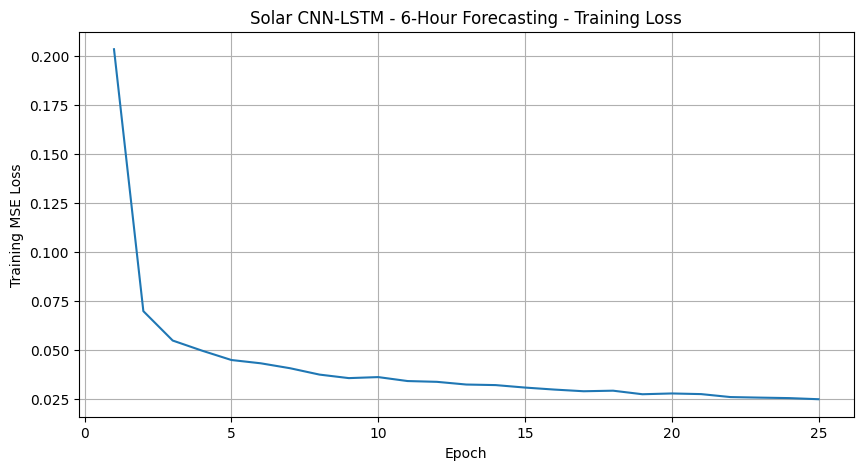

In [178]:
# Plot the 6-hour CNN-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_CNN_LSTM_6H + 1
    ),
    cnn_lstm_train_losses_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")

plt.title(
    "Solar CNN-LSTM - 6-Hour Forecasting - Training Loss"
)

plt.grid(True)

plt.show()

In [179]:
# Generate 6-hour CNN-LSTM forecasts for the 2025 test year

model_cnn_lstm_6h.eval()

cnn_lstm_pred_6h_scaled = []
cnn_lstm_actual_6h_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_6h:

        X_batch = X_batch.to(device)

        outputs = model_cnn_lstm_6h(
            X_batch
        )

        cnn_lstm_pred_6h_scaled.append(
            outputs.cpu().numpy()
        )

        cnn_lstm_actual_6h_scaled.append(
            y_batch.numpy()
        )

cnn_lstm_pred_6h_scaled = np.concatenate(
    cnn_lstm_pred_6h_scaled,
    axis=0
)

cnn_lstm_actual_6h_scaled = np.concatenate(
    cnn_lstm_actual_6h_scaled,
    axis=0
)

print(
    "Prediction shape:",
    cnn_lstm_pred_6h_scaled.shape
)

print(
    "Actual shape    :",
    cnn_lstm_actual_6h_scaled.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [180]:
# Convert the 6-hour CNN-LSTM predictions back to MW

cnn_lstm_pred_6h = target_scaler.inverse_transform(
    cnn_lstm_pred_6h_scaled
)

cnn_lstm_actual_6h = target_scaler.inverse_transform(
    cnn_lstm_actual_6h_scaled
)

print(
    "Prediction shape:",
    cnn_lstm_pred_6h.shape
)

print(
    "Actual shape    :",
    cnn_lstm_actual_6h.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [181]:
# Evaluate the overall 6-hour CNN-LSTM forecasting performance

cnn_lstm_pred_flat_6h = (
    cnn_lstm_pred_6h.flatten()
)

cnn_lstm_actual_flat_6h = (
    cnn_lstm_actual_6h.flatten()
)

cnn_lstm_mae_6h = mean_absolute_error(
    cnn_lstm_actual_flat_6h,
    cnn_lstm_pred_flat_6h
)

cnn_lstm_rmse_6h = np.sqrt(
    mean_squared_error(
        cnn_lstm_actual_flat_6h,
        cnn_lstm_pred_flat_6h
    )
)

cnn_lstm_r2_6h = r2_score(
    cnn_lstm_actual_flat_6h,
    cnn_lstm_pred_flat_6h
)

print("=" * 60)
print("SOLAR CNN-LSTM - 6 HOUR FORECAST")
print("=" * 60)

print(
    f"MAE  : {cnn_lstm_mae_6h:.4f} MW"
)

print(
    f"RMSE : {cnn_lstm_rmse_6h:.4f} MW"
)

print(
    f"R²   : {cnn_lstm_r2_6h:.6f}"
)

print("=" * 60)

SOLAR CNN-LSTM - 6 HOUR FORECAST
MAE  : 1606.5846 MW
RMSE : 2792.6817 MW
R²   : 0.913551


In [182]:
# Compare the 6-hour CNN-LSTM directly with the LSTM baseline

cnn_lstm_mae_improvement_6h = (
    (mae_6h - cnn_lstm_mae_6h)
    / mae_6h
) * 100

cnn_lstm_rmse_improvement_6h = (
    (rmse_6h - cnn_lstm_rmse_6h)
    / rmse_6h
) * 100

cnn_lstm_r2_improvement_6h = (
    (cnn_lstm_r2_6h - r2_6h)
    / r2_6h
) * 100

print(
    f"MAE improvement : "
    f"{cnn_lstm_mae_improvement_6h:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{cnn_lstm_rmse_improvement_6h:.2f}%"
)

print(
    f"R² improvement  : "
    f"{cnn_lstm_r2_improvement_6h:.4f}%"
)

MAE improvement : -10.96%
RMSE improvement: -9.43%
R² improvement  : -1.5361%


In [183]:
# Calculate CNN-LSTM performance separately for each forecast horizon

cnn_lstm_horizon_results_6h = []

for h in range(HORIZON_6H):

    h_actual = cnn_lstm_actual_6h[:, h]
    h_pred = cnn_lstm_pred_6h[:, h]

    h_mae = mean_absolute_error(
        h_actual,
        h_pred
    )

    h_rmse = np.sqrt(
        mean_squared_error(
            h_actual,
            h_pred
        )
    )

    h_r2 = r2_score(
        h_actual,
        h_pred
    )

    cnn_lstm_horizon_results_6h.append({

        "Horizon": f"t+{h + 1}",

        "MAE_MW": h_mae,

        "RMSE_MW": h_rmse,

        "R2": h_r2
    })

cnn_lstm_horizon_results_6h = pd.DataFrame(
    cnn_lstm_horizon_results_6h
)

display(
    cnn_lstm_horizon_results_6h
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1009.027161,1762.128401,0.965559
1,t+2,1367.429199,2341.421790,0.939210
2,t+3,1583.315918,2717.264985,0.918149
3,t+4,1735.241333,2969.085381,0.902304
4,t+5,1882.241821,3171.650517,0.888550
5,t+6,2062.252441,3456.690903,0.867616


In [184]:
# Compare baseline LSTM and CNN-LSTM at every forecast horizon

cnn_vs_lstm_6h = pd.DataFrame({

    "Horizon": [
        f"t+{h + 1}"
        for h in range(HORIZON_6H)
    ],

    "LSTM_MAE": [
        mae
        for mae in horizon_results_6h["MAE_MW"]
    ],

    "CNN_LSTM_MAE": [
        mae
        for mae in cnn_lstm_horizon_results_6h["MAE_MW"]
    ],

    "LSTM_RMSE": [
        rmse
        for rmse in horizon_results_6h["RMSE_MW"]
    ],

    "CNN_LSTM_RMSE": [
        rmse
        for rmse in cnn_lstm_horizon_results_6h["RMSE_MW"]
    ],

    "LSTM_R2": [
        r2
        for r2 in horizon_results_6h["R2"]
    ],

    "CNN_LSTM_R2": [
        r2
        for r2 in cnn_lstm_horizon_results_6h["R2"]
    ]
})

display(
    cnn_vs_lstm_6h
)

,Horizon,LSTM_MAE,CNN_LSTM_MAE,LSTM_RMSE,CNN_LSTM_RMSE,LSTM_R2,CNN_LSTM_R2
0,t+1,762.974060,1009.027161,1263.899472,1762.128401,0.982282,0.965559
1,t+2,1135.715576,1367.429199,1946.319218,2341.421790,0.957995,0.939210
2,t+3,1410.050293,1583.315918,2395.409464,2717.264985,0.936391,0.918149
3,t+4,1621.981323,1735.241333,2754.742638,2969.085381,0.915901,0.902304
4,t+5,1803.149170,1882.241821,3065.296886,3171.650517,0.895899,0.888550
5,t+6,1953.723999,2062.252441,3312.320486,3456.690903,0.878443,0.867616


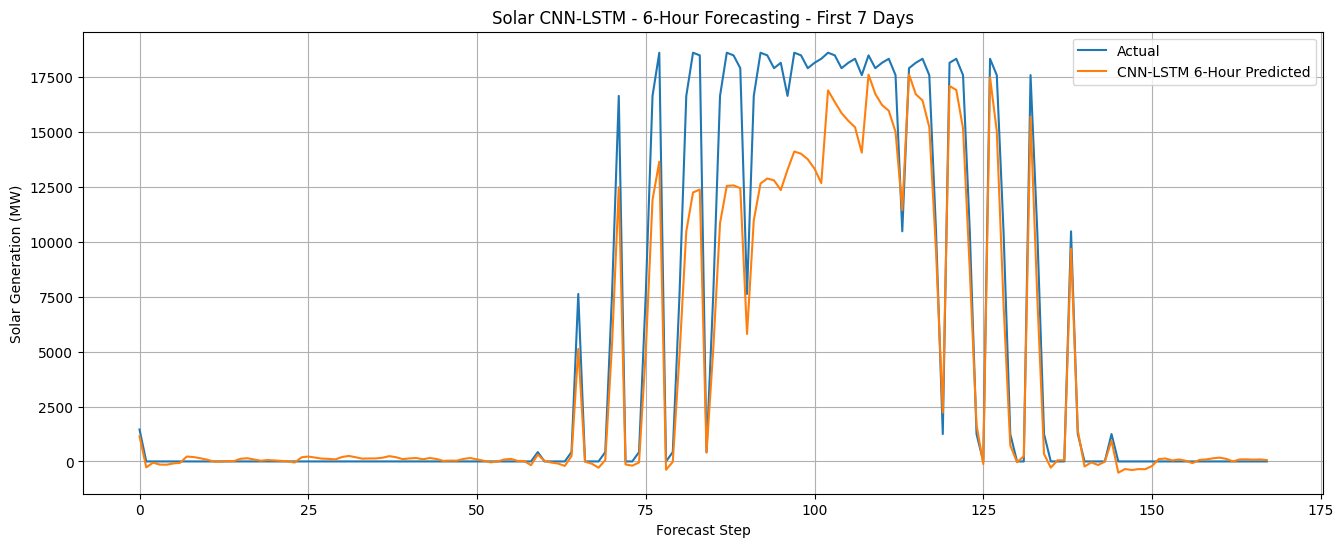

In [185]:
# Plot the 6-hour CNN-LSTM forecast for the first seven days

HOURS_TO_PLOT_CNN_6H = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    cnn_lstm_actual_flat_6h[
        :HOURS_TO_PLOT_CNN_6H
    ],
    label='Actual'
)

plt.plot(
    cnn_lstm_pred_flat_6h[
        :HOURS_TO_PLOT_CNN_6H
    ],
    label='CNN-LSTM 6-Hour Predicted'
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar CNN-LSTM - 6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

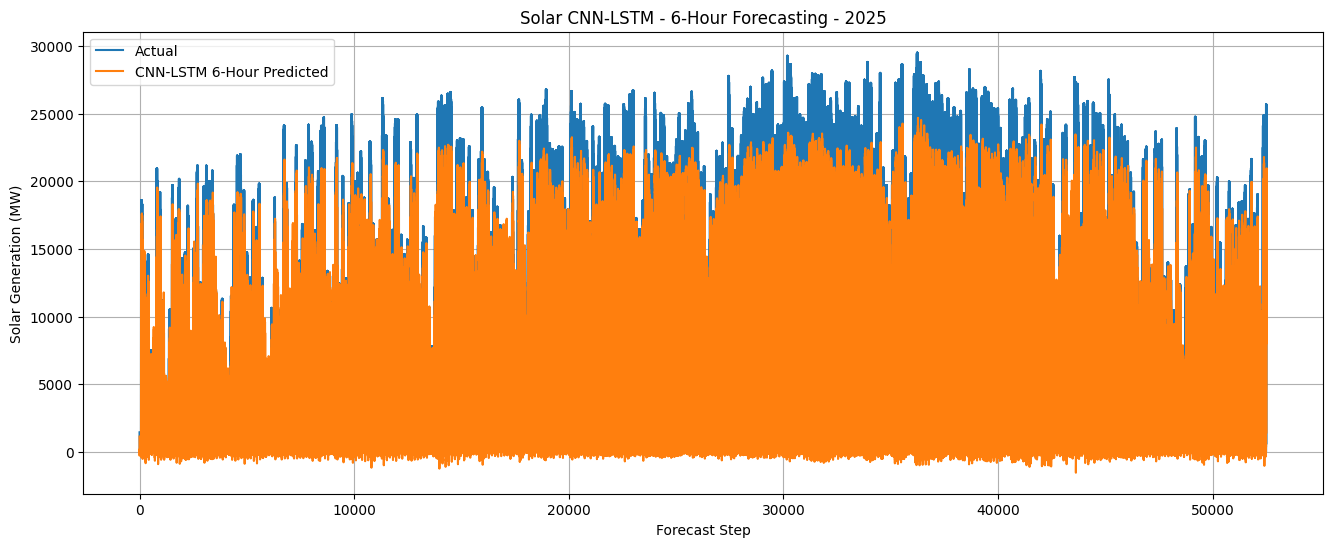

In [186]:
# Plot the complete 2025 CNN-LSTM 6-hour forecasts

plt.figure(figsize=(16, 6))

plt.plot(
    cnn_lstm_actual_flat_6h,
    label='Actual'
)

plt.plot(
    cnn_lstm_pred_flat_6h,
    label='CNN-LSTM 6-Hour Predicted'
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar CNN-LSTM - 6-Hour Forecasting - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

# CNN-LSTM-Attention

In [187]:
# Define the CNN-LSTM-Attention model for 6-hour solar forecasting

class SolarCNNLSTMAttention6H(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_filters_1=32,
        cnn_filters_2=64,
        kernel_size=3,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=6
    ):

        super(SolarCNNLSTMAttention6H, self).__init__()

        # CNN layers for local temporal pattern extraction
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_filters_1,
            kernel_size=kernel_size,
            padding=1
        )

        self.conv2 = nn.Conv1d(
            in_channels=cnn_filters_1,
            out_channels=cnn_filters_2,
            kernel_size=kernel_size,
            padding=1
        )

        self.relu = nn.ReLU()

        # LSTM for temporal dependency learning
        self.lstm = nn.LSTM(
            input_size=cnn_filters_2,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Attention mechanism
        self.attention = nn.Linear(
            hidden_size,
            1
        )

        self.dropout = nn.Dropout(
            dropout
        )

        # Six future-hour predictions
        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        # Input shape:
        # (batch, sequence, features)

        # CNN requires:
        # (batch, features, sequence)

        x = x.transpose(1, 2)

        x = self.relu(
            self.conv1(x)
        )

        x = self.relu(
            self.conv2(x)
        )

        # Back to:
        # (batch, sequence, features)

        x = x.transpose(1, 2)

        # LSTM
        lstm_out, _ = self.lstm(x)

        # Attention scores for every timestep
        attention_scores = self.attention(
            lstm_out
        )

        # Convert scores to attention weights
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Weighted combination of all LSTM timesteps
        context = torch.sum(
            attention_weights * lstm_out,
            dim=1
        )

        # Dropout
        context = self.dropout(
            context
        )

        # Predict 6 future hours
        output = self.fc(
            context
        )

        return output

In [188]:
# Initialize the 6-hour CNN-LSTM-Attention model

model_cnn_lstm_attention_6h = SolarCNNLSTMAttention6H(
    input_size=INPUT_SIZE_6H,
    cnn_filters_1=32,
    cnn_filters_2=64,
    kernel_size=3,
    hidden_size=128,
    num_layers=1,
    dropout=0.2,
    horizon=HORIZON_6H
).to(device)

print(model_cnn_lstm_attention_6h)

SolarCNNLSTMAttention6H(
  (conv1): Conv1d(12, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(64, 128, batch_first=True)
  (attention): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [189]:
# Count trainable parameters in the CNN-LSTM-Attention model

cnn_lstm_attention_parameters_6h = sum(
    p.numel()
    for p in model_cnn_lstm_attention_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    cnn_lstm_attention_parameters_6h
)

Trainable parameters: 107623


In [190]:
# Define loss function and optimizer for CNN-LSTM-Attention

criterion_cnn_lstm_attention_6h = nn.MSELoss()

optimizer_cnn_lstm_attention_6h = torch.optim.Adam(
    model_cnn_lstm_attention_6h.parameters(),
    lr=0.001
)

In [191]:
# Train the CNN-LSTM-Attention model for one epoch

def train_cnn_lstm_attention_epoch_6h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [210]:
# Train the CNN-LSTM-Attention model for 25 epochs

EPOCHS_CNN_LSTM_ATTENTION_6H = 25

cnn_lstm_attention_train_losses_6h = []

for epoch in range(
    EPOCHS_CNN_LSTM_ATTENTION_6H
):

    train_loss = train_cnn_lstm_attention_epoch_6h(
        model_cnn_lstm_attention_6h,
        train_loader_6h,
        criterion_cnn_lstm_attention_6h,
        optimizer_cnn_lstm_attention_6h,
        device
    )

    cnn_lstm_attention_train_losses_6h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_CNN_LSTM_ATTENTION_6H}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/25] Train Loss: 0.011480
Epoch [02/25] Train Loss: 0.012183
Epoch [03/25] Train Loss: 0.011769
Epoch [04/25] Train Loss: 0.011744
Epoch [05/25] Train Loss: 0.012019
Epoch [06/25] Train Loss: 0.011442
Epoch [07/25] Train Loss: 0.011175
Epoch [08/25] Train Loss: 0.011697
Epoch [09/25] Train Loss: 0.011490
Epoch [10/25] Train Loss: 0.011412
Epoch [11/25] Train Loss: 0.011058
Epoch [12/25] Train Loss: 0.011306
Epoch [13/25] Train Loss: 0.011309
Epoch [14/25] Train Loss: 0.011200
Epoch [15/25] Train Loss: 0.011101
Epoch [16/25] Train Loss: 0.011383
Epoch [17/25] Train Loss: 0.010669
Epoch [18/25] Train Loss: 0.011002
Epoch [19/25] Train Loss: 0.010877
Epoch [20/25] Train Loss: 0.010890
Epoch [21/25] Train Loss: 0.011106
Epoch [22/25] Train Loss: 0.010575
Epoch [23/25] Train Loss: 0.010468
Epoch [24/25] Train Loss: 0.010812
Epoch [25/25] Train Loss: 0.010701


In [1]:
# Plot CNN-LSTM-Attention training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_CNN_LSTM_ATTENTION_6H + 1
    ),
    cnn_lstm_attention_train_losses_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")

plt.title(
    "Solar CNN-LSTM-Attention - 6-Hour Training Loss"
)

plt.grid(True)

plt.show()

NameError: name 'plt' is not defined

In [212]:
# Generate 6-hour CNN-LSTM-Attention predictions for 2025

model_cnn_lstm_attention_6h.eval()

cnn_lstm_attention_pred_6h_scaled = []
cnn_lstm_attention_actual_6h_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_6h:

        X_batch = X_batch.to(device)

        outputs = model_cnn_lstm_attention_6h(
            X_batch
        )

        cnn_lstm_attention_pred_6h_scaled.append(
            outputs.cpu().numpy()
        )

        cnn_lstm_attention_actual_6h_scaled.append(
            y_batch.numpy()
        )

cnn_lstm_attention_pred_6h_scaled = np.concatenate(
    cnn_lstm_attention_pred_6h_scaled,
    axis=0
)

cnn_lstm_attention_actual_6h_scaled = np.concatenate(
    cnn_lstm_attention_actual_6h_scaled,
    axis=0
)

print(
    "Prediction shape:",
    cnn_lstm_attention_pred_6h_scaled.shape
)

print(
    "Actual shape    :",
    cnn_lstm_attention_actual_6h_scaled.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [213]:
# Convert CNN-LSTM-Attention predictions back to MW

cnn_lstm_attention_pred_6h = target_scaler.inverse_transform(
    cnn_lstm_attention_pred_6h_scaled
)

cnn_lstm_attention_actual_6h = target_scaler.inverse_transform(
    cnn_lstm_attention_actual_6h_scaled
)

print(
    "Prediction shape:",
    cnn_lstm_attention_pred_6h.shape
)

print(
    "Actual shape    :",
    cnn_lstm_attention_actual_6h.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [214]:
# Evaluate overall CNN-LSTM-Attention performance

cnn_lstm_attention_pred_flat_6h = (
    cnn_lstm_attention_pred_6h.flatten()
)

cnn_lstm_attention_actual_flat_6h = (
    cnn_lstm_attention_actual_6h.flatten()
)

cnn_lstm_attention_mae_6h = mean_absolute_error(
    cnn_lstm_attention_actual_flat_6h,
    cnn_lstm_attention_pred_flat_6h
)

cnn_lstm_attention_rmse_6h = np.sqrt(
    mean_squared_error(
        cnn_lstm_attention_actual_flat_6h,
        cnn_lstm_attention_pred_flat_6h
    )
)

cnn_lstm_attention_r2_6h = r2_score(
    cnn_lstm_attention_actual_flat_6h,
    cnn_lstm_attention_pred_flat_6h
)

print("=" * 60)
print("SOLAR CNN-LSTM-ATTENTION - 6 HOUR FORECAST")
print("=" * 60)

print(
    f"MAE  : {cnn_lstm_attention_mae_6h:.4f} MW"
)

print(
    f"RMSE : {cnn_lstm_attention_rmse_6h:.4f} MW"
)

print(
    f"R²   : {cnn_lstm_attention_r2_6h:.6f}"
)

print("=" * 60)

SOLAR CNN-LSTM-ATTENTION - 6 HOUR FORECAST
MAE  : 1594.3743 MW
RMSE : 2812.1844 MW
R²   : 0.912340


In [215]:
# Compare CNN-LSTM-Attention with the 6-hour LSTM baseline

cnn_lstm_attention_mae_improvement_6h = (
    (mae_6h - cnn_lstm_attention_mae_6h)
    / mae_6h
) * 100

cnn_lstm_attention_rmse_improvement_6h = (
    (rmse_6h - cnn_lstm_attention_rmse_6h)
    / rmse_6h
) * 100

cnn_lstm_attention_r2_improvement_6h = (
    (cnn_lstm_attention_r2_6h - r2_6h)
    / r2_6h
) * 100

print(
    f"MAE improvement : "
    f"{cnn_lstm_attention_mae_improvement_6h:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{cnn_lstm_attention_rmse_improvement_6h:.2f}%"
)

print(
    f"R² improvement  : "
    f"{cnn_lstm_attention_r2_improvement_6h:.4f}%"
)

MAE improvement : -10.11%
RMSE improvement: -10.19%
R² improvement  : -1.6667%


In [216]:
# Calculate CNN-LSTM-Attention performance at each forecast horizon

cnn_lstm_attention_horizon_results_6h = []

for h in range(HORIZON_6H):

    h_actual = cnn_lstm_attention_actual_6h[:, h]
    h_pred = cnn_lstm_attention_pred_6h[:, h]

    h_mae = mean_absolute_error(
        h_actual,
        h_pred
    )

    h_rmse = np.sqrt(
        mean_squared_error(
            h_actual,
            h_pred
        )
    )

    h_r2 = r2_score(
        h_actual,
        h_pred
    )

    cnn_lstm_attention_horizon_results_6h.append({

        "Horizon": f"t+{h + 1}",

        "MAE_MW": h_mae,

        "RMSE_MW": h_rmse,

        "R2": h_r2
    })

cnn_lstm_attention_horizon_results_6h = pd.DataFrame(
    cnn_lstm_attention_horizon_results_6h
)

display(
    cnn_lstm_attention_horizon_results_6h
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1053.347046,1820.638830,0.963234
1,t+2,1304.761353,2299.024250,0.941391
2,t+3,1555.129517,2733.328923,0.917178
3,t+4,1737.637451,3011.821874,0.899472
4,t+5,1870.942505,3217.156664,0.885329
5,t+6,2044.428589,3458.004193,0.867515


In [217]:
# Compare the main 6-hour models

solar_6h_model_comparison = pd.DataFrame({

    "Model": [
        "LSTM Baseline",
        "Residual-LSTM",
        "CNN-LSTM-Attention"
    ],

    "MAE_MW": [
        mae_6h,
        residual_mae_6h,
        cnn_lstm_attention_mae_6h
    ],

    "RMSE_MW": [
        rmse_6h,
        residual_rmse_6h,
        cnn_lstm_attention_rmse_6h
    ],

    "R2": [
        r2_6h,
        residual_r2_6h,
        cnn_lstm_attention_r2_6h
    ]
})

display(
    solar_6h_model_comparison
)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM Baseline,1447.932373,2552.113634,0.927804
1,Residual-LSTM,1454.284912,2562.076892,0.927239
2,CNN-LSTM-Attention,1594.374268,2812.184382,0.912340


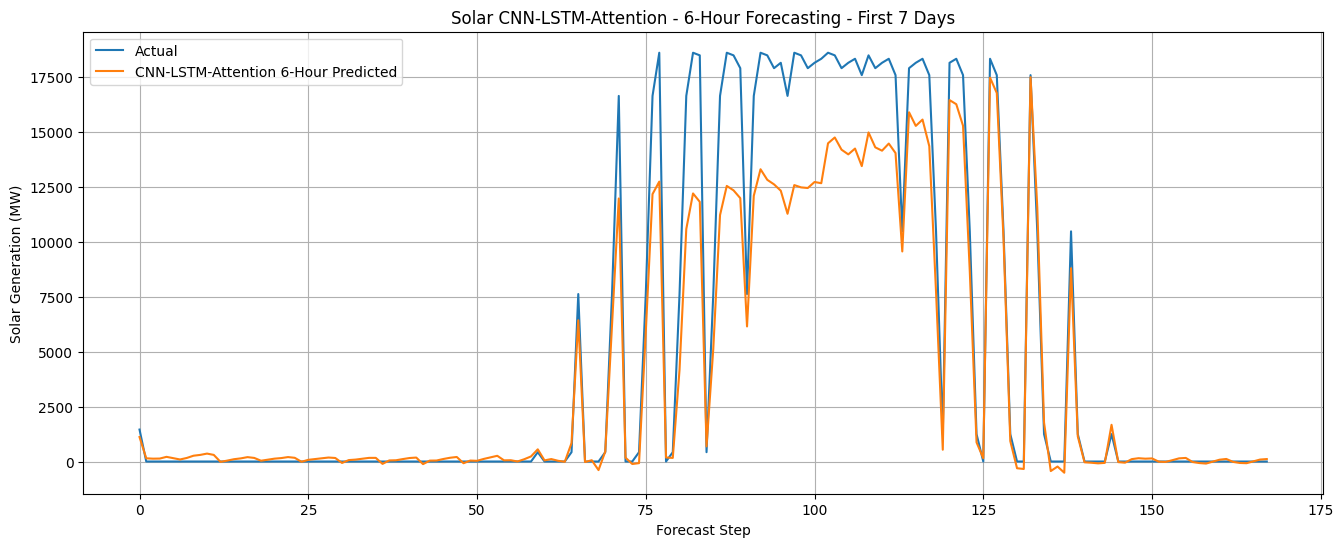

In [218]:
# Plot CNN-LSTM-Attention predictions for the first seven days

HOURS_TO_PLOT_CNN_ATTENTION_6H = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    cnn_lstm_attention_actual_flat_6h[
        :HOURS_TO_PLOT_CNN_ATTENTION_6H
    ],
    label="Actual"
)

plt.plot(
    cnn_lstm_attention_pred_flat_6h[
        :HOURS_TO_PLOT_CNN_ATTENTION_6H
    ],
    label="CNN-LSTM-Attention 6-Hour Predicted"
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar CNN-LSTM-Attention - 6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

# Updated architecture

In [2]:
# Import the libraries required for solar forecasting

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import random

In [3]:
# Set random seeds for reproducible model training

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
CUDA available: False


In [4]:
# Load the solar forecasting dataset

df = pd.read_csv("Solar_Forecasting.csv")

print("Shape:", df.shape)

display(df.head())

Shape: (26297, 14)


,Datetime_UTC,Solar_MW,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,0.449746,11.32,69.29,5.05,2.37,0.0,0.0,0.0,NaN,7,6,1,1
1,2023-01-01 08:00:00+00:00,0.454733,10.36,75.44,4.62,10.12,0.0,0.0,0.0,NaN,8,6,1,1
2,2023-01-01 09:00:00+00:00,0.443528,9.76,79.94,4.48,17.85,0.0,0.0,0.0,NaN,9,6,1,1
3,2023-01-01 10:00:00+00:00,0.458567,9.22,83.95,4.39,57.65,0.0,0.0,0.0,NaN,10,6,1,1
4,2023-01-01 11:00:00+00:00,0.451126,8.69,87.17,4.19,99.70,0.0,0.0,0.0,NaN,11,6,1,1


In [5]:
# Convert timestamps and sort the dataset chronologically

df['Datetime_UTC'] = pd.to_datetime(
    df['Datetime_UTC']
)

df = df.sort_values(
    'Datetime_UTC'
).reset_index(drop=True)

print("Start:", df['Datetime_UTC'].min())
print("End  :", df['Datetime_UTC'].max())

Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00


In [6]:
# Split 2023-2024 for training and 2025 for final testing

TRAIN_END = '2024-12-31 23:59:59'

train_df = df[
    df['Datetime_UTC'] <= TRAIN_END
].copy()

test_df = df[
    df['Datetime_UTC'] > TRAIN_END
].copy()

print("Training samples:", len(train_df))
print("Testing samples :", len(test_df))

print("\nTraining period:")
print(
    train_df['Datetime_UTC'].min(),
    "→",
    train_df['Datetime_UTC'].max()
)

print("\nTesting period:")
print(
    test_df['Datetime_UTC'].min(),
    "→",
    test_df['Datetime_UTC'].max()
)

Training samples: 17537
Testing samples : 8760

Training period:
2023-01-01 07:00:00+00:00 → 2024-12-31 23:00:00+00:00

Testing period:
2025-01-01 00:00:00+00:00 → 2025-12-31 23:00:00+00:00


In [7]:
# Define the same 12 input features used in the previous experiments

FEATURES = [
    'Solar_MW',
    'T2M',
    'RH2M',
    'WS10M',
    'CLOUD_AMT',
    'ALLSKY_SFC_SW_DWN',
    'ALLSKY_SFC_SW_DNI',
    'ALLSKY_SFC_SW_DIFF',
    'Hour',
    'DayOfWeek',
    'DayOfYear',
    'Month'
]

TARGET = 'Solar_MW'

print("Number of features:", len(FEATURES))
print("Target:", TARGET)

Number of features: 12
Target: Solar_MW


In [8]:
# Extract training and testing features and target values

X_train_raw = train_df[
    FEATURES
].values

y_train_raw = train_df[
    TARGET
].values.reshape(-1, 1)

X_test_raw = test_df[
    FEATURES
].values

y_test_raw = test_df[
    TARGET
].values.reshape(-1, 1)

print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)

print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

X_train: (17537, 12)
y_train: (17537, 1)
X_test : (8760, 12)
y_test : (8760, 1)


In [9]:
# Create scalers using training data only

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

In [13]:
# Fit scalers on 2023-2024 and transform both datasets

X_train_scaled = feature_scaler.fit_transform(
    X_train_raw
)

X_test_scaled = feature_scaler.transform(
    X_test_raw
)

y_train_scaled = target_scaler.fit_transform(
    y_train_raw
)

y_test_scaled = target_scaler.transform(
    y_test_raw
)

print(
    "Training feature mean:",
    X_train_scaled.mean(axis=0)
)

print(
    "Training feature std:",
    X_train_scaled.std(axis=0)
)

Training feature mean: [ 2.59307379e-17 -2.33376641e-16 -2.07445903e-16 -2.33376641e-16
 -5.83441603e-17  8.42748982e-17  9.39989250e-17 -1.73411810e-16
 -7.25250326e-17  3.48444291e-17  1.03722952e-16 -5.18614758e-17]
Training feature std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [14]:
# Define the new 48-hour lookback and forecasting horizon settings

LOOKBACK = 48

HORIZON = 6

print("Lookback:", LOOKBACK, "hours")
print("Forecast horizon:", HORIZON, "hours")

Lookback: 48 hours
Forecast horizon: 6 hours


In [15]:
# Create multi-step sequences using 48 hours of historical data

def create_multistep_sequences(
    X,
    y,
    lookback,
    horizon
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X) - horizon + 1
    ):

        X_seq.append(
            X[i - lookback:i]
        )

        y_seq.append(
            y[i:i + horizon]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )

In [16]:
# Create 48-hour input sequences with 6 future target hours

X_train_6h, y_train_6h = create_multistep_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK,
    HORIZON
)

print(
    "X_train_6h:",
    X_train_6h.shape
)

print(
    "y_train_6h:",
    y_train_6h.shape
)

X_train_6h: (17484, 48, 12)
y_train_6h: (17484, 6, 1)


In [17]:
# Reshape the six future target values into a flat six-hour target vector

y_train_6h = y_train_6h.squeeze(-1)

print(
    "X_train_6h:",
    X_train_6h.shape
)

print(
    "y_train_6h:",
    y_train_6h.shape
)

X_train_6h: (17484, 48, 12)
y_train_6h: (17484, 6)


In [18]:
# Create 6-hour test sequences using the end of 2024 as historical context

X_combined = np.concatenate(
    [
        X_train_scaled,
        X_test_scaled
    ],
    axis=0
)

y_combined = np.concatenate(
    [
        y_train_scaled,
        y_test_scaled
    ],
    axis=0
)

train_size = len(
    X_train_scaled
)

X_test_6h = []
y_test_6h = []

for i in range(
    train_size,
    len(X_combined) - HORIZON + 1
):

    X_test_6h.append(
        X_combined[
            i - LOOKBACK:i
        ]
    )

    y_test_6h.append(
        y_combined[
            i:i + HORIZON
        ]
    )

X_test_6h = np.array(
    X_test_6h
)

y_test_6h = np.array(
    y_test_6h
)

y_test_6h = y_test_6h.squeeze(-1)

print(
    "X_test_6h:",
    X_test_6h.shape
)

print(
    "y_test_6h:",
    y_test_6h.shape
)

X_test_6h: (8755, 48, 12)
y_test_6h: (8755, 6)


In [19]:
# Verify the first and last complete six-hour forecast periods

print("First 6-hour forecast:")
print(
    test_df['Datetime_UTC'].iloc[0]
)

print(
    "→",
    test_df['Datetime_UTC'].iloc[5]
)

print("\nLast complete 6-hour forecast:")

print(
    test_df['Datetime_UTC'].iloc[-6]
)

print(
    "→",
    test_df['Datetime_UTC'].iloc[-1]
)

print(
    "\nNumber of 6-hour forecasts:",
    len(y_test_6h)
)

First 6-hour forecast:
2025-01-01 00:00:00+00:00
→ 2025-01-01 05:00:00+00:00

Last complete 6-hour forecast:
2025-12-31 18:00:00+00:00
→ 2025-12-31 23:00:00+00:00

Number of 6-hour forecasts: 8755


In [20]:
# Convert the six-hour sequence data into PyTorch tensors

X_train_6h_tensor = torch.tensor(
    X_train_6h,
    dtype=torch.float32
)

y_train_6h_tensor = torch.tensor(
    y_train_6h,
    dtype=torch.float32
)

X_test_6h_tensor = torch.tensor(
    X_test_6h,
    dtype=torch.float32
)

y_test_6h_tensor = torch.tensor(
    y_test_6h,
    dtype=torch.float32
)

print(
    "X_train:",
    X_train_6h_tensor.shape
)

print(
    "y_train:",
    y_train_6h_tensor.shape
)

print(
    "X_test :",
    X_test_6h_tensor.shape
)

print(
    "y_test :",
    y_test_6h_tensor.shape
)

X_train: torch.Size([17484, 48, 12])
y_train: torch.Size([17484, 6])
X_test : torch.Size([8755, 48, 12])
y_test : torch.Size([8755, 6])


In [21]:
# Create DataLoaders for six-hour LSTM training and testing

BATCH_SIZE = 64

train_dataset_6h = TensorDataset(
    X_train_6h_tensor,
    y_train_6h_tensor
)

test_dataset_6h = TensorDataset(
    X_test_6h_tensor,
    y_test_6h_tensor
)

train_loader_6h = DataLoader(
    train_dataset_6h,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader_6h = DataLoader(
    test_dataset_6h,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(
    "Training batches:",
    len(train_loader_6h)
)

print(
    "Testing batches:",
    len(test_loader_6h)
)

Training batches: 274
Testing batches: 137


In [22]:
# Select GPU if available, otherwise use CPU

device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

print(
    "Using device:",
    device
)

Using device: cpu


In [23]:
# Define the new two-layer LSTM architecture for six-hour forecasting

class SolarLSTM6H_New(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        horizon=6
    ):

        super(
            SolarLSTM6H_New,
            self
        ).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        # Process the 48-hour sequence

        out, _ = self.lstm(x)

        # Use the final timestep representation

        out = out[:, -1, :]

        # Apply dropout before the output layer

        out = self.dropout(out)

        # Predict all future hours simultaneously

        out = self.fc(out)

        return out

In [24]:
# Initialize the new 64-neuron two-layer LSTM

INPUT_SIZE = len(FEATURES)

HIDDEN_SIZE = 64

NUM_LAYERS = 2

DROPOUT = 0.2

HORIZON_6H = 6

model_6h_new = SolarLSTM6H_New(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    horizon=HORIZON_6H
).to(device)

print(model_6h_new)

SolarLSTM6H_New(
  (lstm): LSTM(12, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [25]:
# Count trainable parameters in the new six-hour LSTM

parameters_6h_new = sum(
    p.numel()
    for p in model_6h_new.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    parameters_6h_new
)

Trainable parameters: 53638


In [26]:
# Define the MSE loss and Adam optimizer

criterion_6h_new = nn.MSELoss()

optimizer_6h_new = torch.optim.Adam(
    model_6h_new.parameters(),
    lr=0.001
)

In [27]:
# Train the new six-hour LSTM for one complete epoch

def train_epoch_6h_new(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)

        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [28]:
# Train the new six-hour LSTM for 30 epochs

EPOCHS_6H_NEW = 30

train_losses_6h_new = []

for epoch in range(
    EPOCHS_6H_NEW
):

    train_loss = train_epoch_6h_new(
        model_6h_new,
        train_loader_6h,
        criterion_6h_new,
        optimizer_6h_new,
        device
    )

    train_losses_6h_new.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_6H_NEW}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/30] Train Loss: 0.238162
Epoch [02/30] Train Loss: 0.083866
Epoch [03/30] Train Loss: 0.067497
Epoch [04/30] Train Loss: 0.061237
Epoch [05/30] Train Loss: 0.055606
Epoch [06/30] Train Loss: 0.053857
Epoch [07/30] Train Loss: 0.050458
Epoch [08/30] Train Loss: 0.049249
Epoch [09/30] Train Loss: 0.047445
Epoch [10/30] Train Loss: 0.045538
Epoch [11/30] Train Loss: 0.044679
Epoch [12/30] Train Loss: 0.043301
Epoch [13/30] Train Loss: 0.041874
Epoch [14/30] Train Loss: 0.040036
Epoch [15/30] Train Loss: 0.040007
Epoch [16/30] Train Loss: 0.039406
Epoch [17/30] Train Loss: 0.038608
Epoch [18/30] Train Loss: 0.037154
Epoch [19/30] Train Loss: 0.036508
Epoch [20/30] Train Loss: 0.036220
Epoch [21/30] Train Loss: 0.034292
Epoch [22/30] Train Loss: 0.034613
Epoch [23/30] Train Loss: 0.034317
Epoch [24/30] Train Loss: 0.034135
Epoch [25/30] Train Loss: 0.032559
Epoch [26/30] Train Loss: 0.031629
Epoch [27/30] Train Loss: 0.030947
Epoch [28/30] Train Loss: 0.030872
Epoch [29/30] Train 

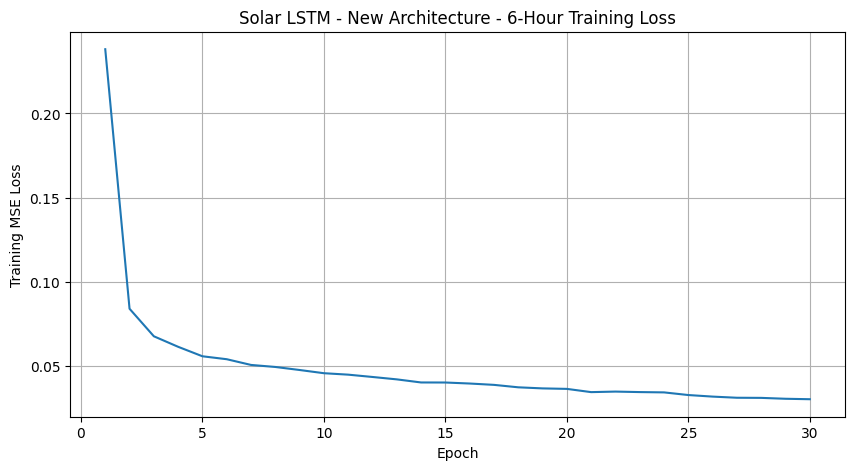

In [29]:
# Plot the training loss of the new six-hour LSTM

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_6H_NEW + 1
    ),
    train_losses_6h_new
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")

plt.title(
    "Solar LSTM - New Architecture - 6-Hour Training Loss"
)

plt.grid(True)

plt.show()

In [30]:
# Generate six-hour forecasts from the trained LSTM

def predict_6h_new(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(
                X_batch
            )

            predictions.append(
                outputs.cpu().numpy()
            )

            actuals.append(
                y_batch.numpy()
            )

    predictions = np.concatenate(
        predictions,
        axis=0
    )

    actuals = np.concatenate(
        actuals,
        axis=0
    )

    return predictions, actuals

In [31]:
# Generate predictions for the complete 2025 six-hour test period

pred_6h_new_scaled, actual_6h_new_scaled = predict_6h_new(
    model_6h_new,
    test_loader_6h,
    device
)

print(
    "Prediction shape:",
    pred_6h_new_scaled.shape
)

print(
    "Actual shape    :",
    actual_6h_new_scaled.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [32]:
# Convert the six-hour predictions back to MW

pred_6h_new = target_scaler.inverse_transform(
    pred_6h_new_scaled
)

actual_6h_new = target_scaler.inverse_transform(
    actual_6h_new_scaled
)

print(
    "Prediction shape:",
    pred_6h_new.shape
)

print(
    "Actual shape    :",
    actual_6h_new.shape
)

Prediction shape: (8755, 6)
Actual shape    : (8755, 6)


In [33]:
# Evaluate overall performance of the new six-hour LSTM

pred_6h_new_flat = (
    pred_6h_new.flatten()
)

actual_6h_new_flat = (
    actual_6h_new.flatten()
)

mae_6h_new = mean_absolute_error(
    actual_6h_new_flat,
    pred_6h_new_flat
)

rmse_6h_new = np.sqrt(
    mean_squared_error(
        actual_6h_new_flat,
        pred_6h_new_flat
    )
)

r2_6h_new = r2_score(
    actual_6h_new_flat,
    pred_6h_new_flat
)

print("=" * 60)
print(
    "SOLAR LSTM - NEW ARCHITECTURE - 6 HOUR FORECAST"
)
print("=" * 60)

print(
    f"MAE  : {mae_6h_new:.4f} MW"
)

print(
    f"RMSE : {rmse_6h_new:.4f} MW"
)

print(
    f"R²   : {r2_6h_new:.6f}"
)

print("=" * 60)

SOLAR LSTM - NEW ARCHITECTURE - 6 HOUR FORECAST
MAE  : 1746.2437 MW
RMSE : 3048.3149 MW
R²   : 0.897001


In [34]:
# Calculate performance separately for each future hour

horizon_results_6h_new = []

for h in range(6):

    h_actual = actual_6h_new[:, h]

    h_pred = pred_6h_new[:, h]

    h_mae = mean_absolute_error(
        h_actual,
        h_pred
    )

    h_rmse = np.sqrt(
        mean_squared_error(
            h_actual,
            h_pred
        )
    )

    h_r2 = r2_score(
        h_actual,
        h_pred
    )

    horizon_results_6h_new.append({

        "Horizon": f"t+{h + 1}",

        "MAE_MW": h_mae,

        "RMSE_MW": h_rmse,

        "R2": h_r2
    })

horizon_results_6h_new = pd.DataFrame(
    horizon_results_6h_new
)

display(
    horizon_results_6h_new
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1200.759888,2086.224341,0.951725
1,t+2,1477.555054,2535.495711,0.928715
2,t+3,1723.618164,2964.339218,0.902587
3,t+4,1918.155151,3277.602020,0.880947
4,t+5,2025.988403,3488.180615,0.865195
5,t+6,2131.385254,3643.471696,0.852923


In [35]:
# Compare the new 48-hour-lookback LSTM with the previous 24-hour LSTM

lstm_6h_comparison = pd.DataFrame({

    "Model": [
        "Old LSTM - 24h LB - 128x1",
        "New LSTM - 48h LB - 64x2"
    ],

    "MAE_MW": [
        1447.9324,
        mae_6h_new
    ],

    "RMSE_MW": [
        2552.1136,
        rmse_6h_new
    ],

    "R2": [
        0.927804,
        r2_6h_new
    ]
})

display(
    lstm_6h_comparison
)

,Model,MAE_MW,RMSE_MW,R2
0,Old LSTM - 24h LB - 128x1,1447.932400,2552.113600,0.927804
1,New LSTM - 48h LB - 64x2,1746.243652,3048.314944,0.897001


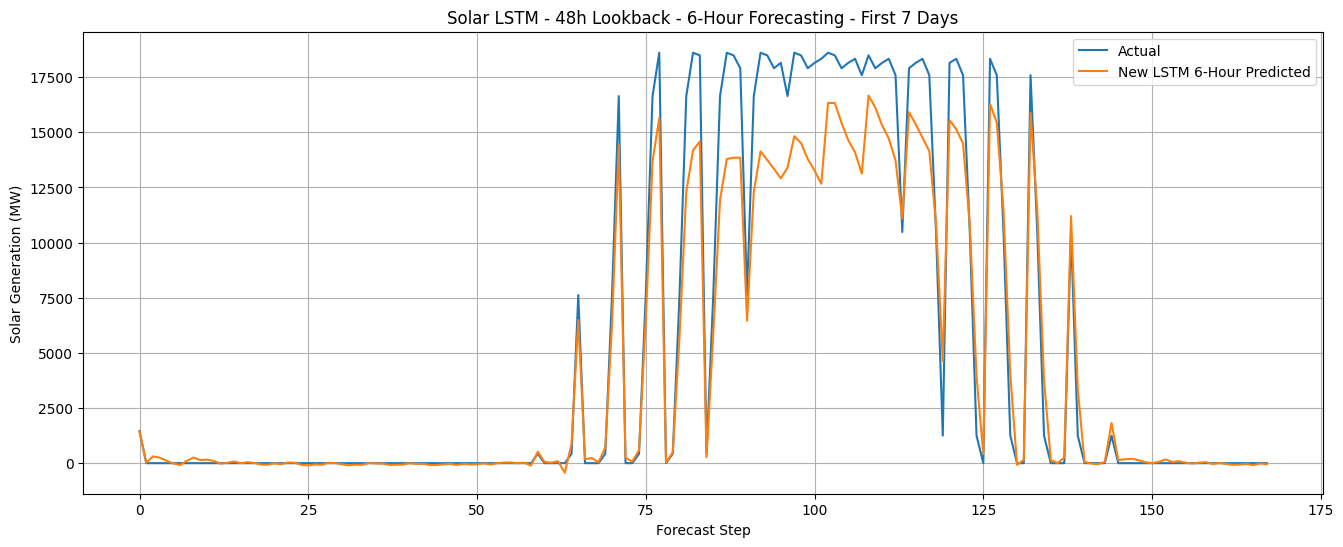

In [36]:
# Plot the new six-hour LSTM forecast for the first seven days

HOURS_TO_PLOT_6H_NEW = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    actual_6h_new_flat[
        :HOURS_TO_PLOT_6H_NEW
    ],
    label="Actual"
)

plt.plot(
    pred_6h_new_flat[
        :HOURS_TO_PLOT_6H_NEW
    ],
    label="New LSTM 6-Hour Predicted"
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar LSTM - 48h Lookback - 6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

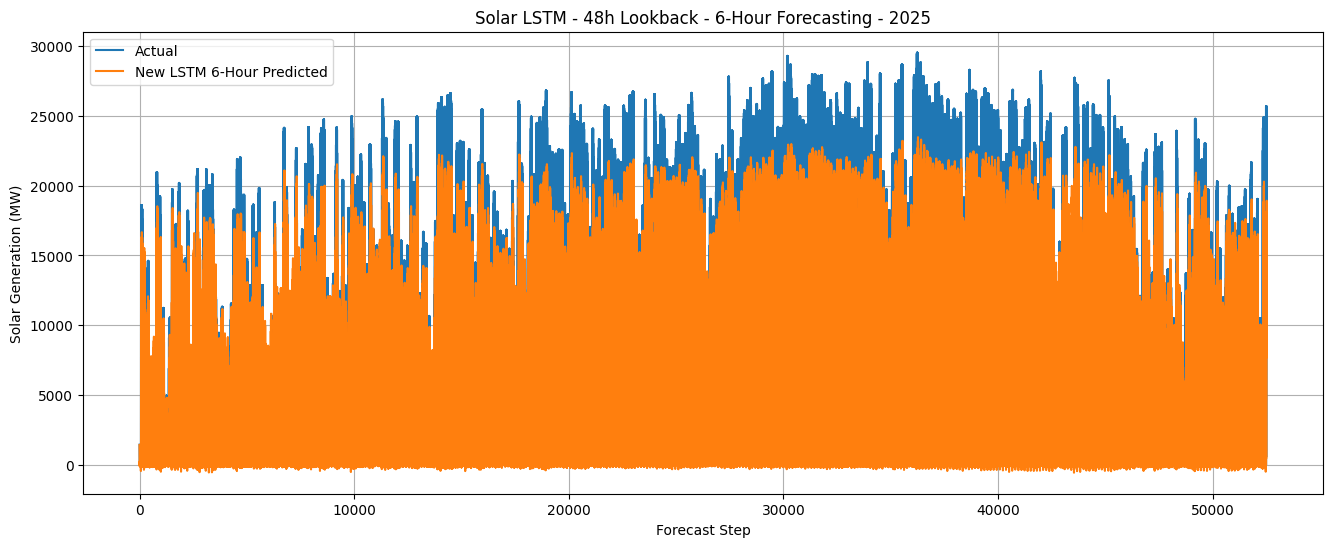

In [37]:
# Plot the complete 2025 six-hour LSTM forecast

plt.figure(figsize=(16, 6))

plt.plot(
    actual_6h_new_flat,
    label="Actual"
)

plt.plot(
    pred_6h_new_flat,
    label="New LSTM 6-Hour Predicted"
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar LSTM - 48h Lookback - 6-Hour Forecasting - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

# Residual -LSTM

In [39]:
# Generate base LSTM predictions on training data

model_6h_new.eval()

with torch.no_grad():

    base_train_pred_6h_new = model_6h_new(
        X_train_6h_tensor.to(device)
    ).cpu().numpy()

print(
    "Base train prediction shape:",
    base_train_pred_6h_new.shape
)

print(
    "Training target shape:",
    y_train_6h.shape
)

Base train prediction shape: (17484, 6)
Training target shape: (17484, 6)


In [40]:
# Calculate training residuals

residual_train_6h_new = (
    y_train_6h -
    base_train_pred_6h_new
)

print(
    "Residual training shape:",
    residual_train_6h_new.shape
)

print(
    "Mean residual:",
    residual_train_6h_new.mean()
)

print(
    "Residual std:",
    residual_train_6h_new.std()
)

Residual training shape: (17484, 6)
Mean residual: 0.01250148905199035
Residual std: 0.12478901316663746


In [41]:
# Create Residual-LSTM training DataLoader

residual_train_dataset_6h_new = TensorDataset(
    X_train_6h_tensor,
    torch.tensor(
        residual_train_6h_new,
        dtype=torch.float32
    )
)

residual_train_loader_6h_new = DataLoader(
    residual_train_dataset_6h_new,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print(
    "Residual training samples:",
    len(residual_train_dataset_6h_new)
)

print(
    "Residual training batches:",
    len(residual_train_loader_6h_new)
)

Residual training samples: 17484
Residual training batches: 274


In [43]:
# Define the 6-hour Residual-LSTM

class SolarResidualLSTM6H_New(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        horizon=6
    ):

        super(
            SolarResidualLSTM6H_New,
            self
        ).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        out, _ = self.lstm(x)

        out = out[:, -1, :]

        out = self.dropout(out)

        out = self.fc(out)

        return out

In [44]:
# Initialize Residual-LSTM

residual_model_6h_new = SolarResidualLSTM6H_New(
    input_size=len(FEATURES),
    hidden_size=64,
    num_layers=2,
    dropout=0.2,
    horizon=6
).to(device)

print(residual_model_6h_new)

SolarResidualLSTM6H_New(
  (lstm): LSTM(12, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [45]:
# Count trainable parameters

residual_parameters_6h_new = sum(
    p.numel()
    for p in residual_model_6h_new.parameters()
    if p.requires_grad
)

print(
    "Residual-LSTM trainable parameters:",
    residual_parameters_6h_new
)

Residual-LSTM trainable parameters: 53638


In [46]:
# Define loss and optimizer

criterion_residual_6h_new = nn.MSELoss()

optimizer_residual_6h_new = torch.optim.Adam(
    residual_model_6h_new.parameters(),
    lr=0.001
)

In [47]:
# Train one epoch

def train_residual_epoch_6h_new(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, residual_batch in loader:

        X_batch = X_batch.to(device)
        residual_batch = residual_batch.to(device)

        optimizer.zero_grad()

        residual_prediction = model(
            X_batch
        )

        loss = criterion(
            residual_prediction,
            residual_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    return epoch_loss

In [48]:
# Train Residual-LSTM

EPOCHS_RESIDUAL_6H_NEW = 30

residual_train_losses_6h_new = []

for epoch in range(
    EPOCHS_RESIDUAL_6H_NEW
):

    train_loss = train_residual_epoch_6h_new(
        residual_model_6h_new,
        residual_train_loader_6h_new,
        criterion_residual_6h_new,
        optimizer_residual_6h_new,
        device
    )

    residual_train_losses_6h_new.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_RESIDUAL_6H_NEW}] "
        f"Residual Train Loss: {train_loss:.6f}"
    )

Epoch [01/30] Residual Train Loss: 0.015417
Epoch [02/30] Residual Train Loss: 0.014824
Epoch [03/30] Residual Train Loss: 0.014647
Epoch [04/30] Residual Train Loss: 0.014510
Epoch [05/30] Residual Train Loss: 0.014380
Epoch [06/30] Residual Train Loss: 0.014182
Epoch [07/30] Residual Train Loss: 0.014064
Epoch [08/30] Residual Train Loss: 0.013870
Epoch [09/30] Residual Train Loss: 0.013659
Epoch [10/30] Residual Train Loss: 0.013441
Epoch [11/30] Residual Train Loss: 0.013063
Epoch [12/30] Residual Train Loss: 0.012724
Epoch [13/30] Residual Train Loss: 0.012151
Epoch [14/30] Residual Train Loss: 0.011788
Epoch [15/30] Residual Train Loss: 0.011185
Epoch [16/30] Residual Train Loss: 0.010649
Epoch [17/30] Residual Train Loss: 0.010037
Epoch [18/30] Residual Train Loss: 0.009563
Epoch [19/30] Residual Train Loss: 0.009024
Epoch [20/30] Residual Train Loss: 0.008666
Epoch [21/30] Residual Train Loss: 0.008565
Epoch [22/30] Residual Train Loss: 0.007803
Epoch [23/30] Residual Train Los

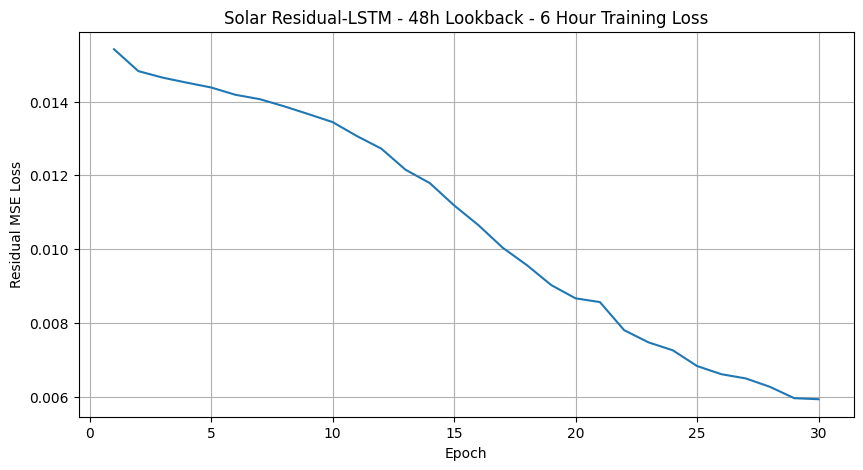

In [49]:
# Plot Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_6H_NEW + 1
    ),
    residual_train_losses_6h_new
)

plt.xlabel("Epoch")
plt.ylabel("Residual MSE Loss")

plt.title(
    "Solar Residual-LSTM - 48h Lookback - 6 Hour Training Loss"
)

plt.grid(True)

plt.show()

In [50]:
# Generate residual corrections for the test set

residual_model_6h_new.eval()

with torch.no_grad():

    predicted_residual_6h_new = (
        residual_model_6h_new(
            X_test_6h_tensor.to(device)
        )
        .cpu()
        .numpy()
    )

print(
    "Predicted residual shape:",
    predicted_residual_6h_new.shape
)

Predicted residual shape: (8755, 6)


In [51]:
# Combine base forecast and residual correction

residual_pred_6h_new_scaled = (
    pred_6h_new_scaled +
    predicted_residual_6h_new
)

print(
    "Final prediction shape:",
    residual_pred_6h_new_scaled.shape
)

Final prediction shape: (8755, 6)


In [52]:
# Convert predictions to MW

residual_pred_6h_new = target_scaler.inverse_transform(
    residual_pred_6h_new_scaled
)

residual_actual_6h_new = target_scaler.inverse_transform(
    actual_6h_new_scaled
)

print(
    "Prediction shape:",
    residual_pred_6h_new.shape
)

print(
    "Actual shape:",
    residual_actual_6h_new.shape
)

print(
    "Prediction min:",
    residual_pred_6h_new.min()
)

print(
    "Prediction max:",
    residual_pred_6h_new.max()
)

Prediction shape: (8755, 6)
Actual shape: (8755, 6)
Prediction min: -1348.604
Prediction max: 23538.447


In [53]:
# Evaluate overall Residual-LSTM performance

residual_pred_6h_new_flat = (
    residual_pred_6h_new.flatten()
)

residual_actual_6h_new_flat = (
    residual_actual_6h_new.flatten()
)

residual_mae_6h_new = mean_absolute_error(
    residual_actual_6h_new_flat,
    residual_pred_6h_new_flat
)

residual_rmse_6h_new = np.sqrt(
    mean_squared_error(
        residual_actual_6h_new_flat,
        residual_pred_6h_new_flat
    )
)

residual_r2_6h_new = r2_score(
    residual_actual_6h_new_flat,
    residual_pred_6h_new_flat
)

print("=" * 60)
print(
    "SOLAR RESIDUAL-LSTM - 48h LOOKBACK - 6 HOUR FORECAST"
)
print("=" * 60)

print(
    f"MAE  : {residual_mae_6h_new:.4f} MW"
)

print(
    f"RMSE : {residual_rmse_6h_new:.4f} MW"
)

print(
    f"R²   : {residual_r2_6h_new:.6f}"
)

print("=" * 60)

SOLAR RESIDUAL-LSTM - 48h LOOKBACK - 6 HOUR FORECAST
MAE  : 1685.4000 MW
RMSE : 2972.3336 MW
R²   : 0.902071


In [54]:
# Compare Residual-LSTM with the new LSTM

residual_mae_improvement_6h_new = (
    (mae_6h_new - residual_mae_6h_new)
    / mae_6h_new
) * 100

residual_rmse_improvement_6h_new = (
    (rmse_6h_new - residual_rmse_6h_new)
    / rmse_6h_new
) * 100

residual_r2_improvement_6h_new = (
    (residual_r2_6h_new - r2_6h_new)
    / r2_6h_new
) * 100

print(
    f"MAE improvement : "
    f"{residual_mae_improvement_6h_new:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{residual_rmse_improvement_6h_new:.2f}%"
)

print(
    f"R² improvement  : "
    f"{residual_r2_improvement_6h_new:.4f}%"
)

MAE improvement : 3.48%
RMSE improvement: 2.49%
R² improvement  : 0.5653%


In [55]:
# Calculate performance for each forecast horizon

residual_horizon_results_6h_new = []

for h in range(6):

    actual_h = residual_actual_6h_new[:, h]

    pred_h = residual_pred_6h_new[:, h]

    mae_h = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse_h = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2_h = r2_score(
        actual_h,
        pred_h
    )

    residual_horizon_results_6h_new.append({

        "Horizon": f"t+{h + 1}",

        "MAE_MW": mae_h,

        "RMSE_MW": rmse_h,

        "R2": r2_h
    })

residual_horizon_results_6h_new = pd.DataFrame(
    residual_horizon_results_6h_new
)

display(
    residual_horizon_results_6h_new
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1175.459106,2064.549345,0.952723
1,t+2,1449.046753,2512.002687,0.930029
2,t+3,1682.690063,2914.864319,0.905812
3,t+4,1839.677490,3190.297008,0.887204
4,t+5,1946.475342,3383.315977,0.873178
5,t+6,2019.052368,3509.248922,0.863559


In [56]:
# Compare the new 6-hour models

solar_6h_new_comparison = pd.DataFrame({

    "Model": [
        "LSTM - 48h LB - 64x2",
        "Residual-LSTM - 48h LB - 64x2"
    ],

    "MAE_MW": [
        mae_6h_new,
        residual_mae_6h_new
    ],

    "RMSE_MW": [
        rmse_6h_new,
        residual_rmse_6h_new
    ],

    "R2": [
        r2_6h_new,
        residual_r2_6h_new
    ]
})

display(
    solar_6h_new_comparison
)

,Model,MAE_MW,RMSE_MW,R2
0,LSTM - 48h LB - 64x2,1746.243652,3048.314944,0.897001
1,Residual-LSTM - 48h LB - 64x2,1685.400024,2972.333595,0.902071


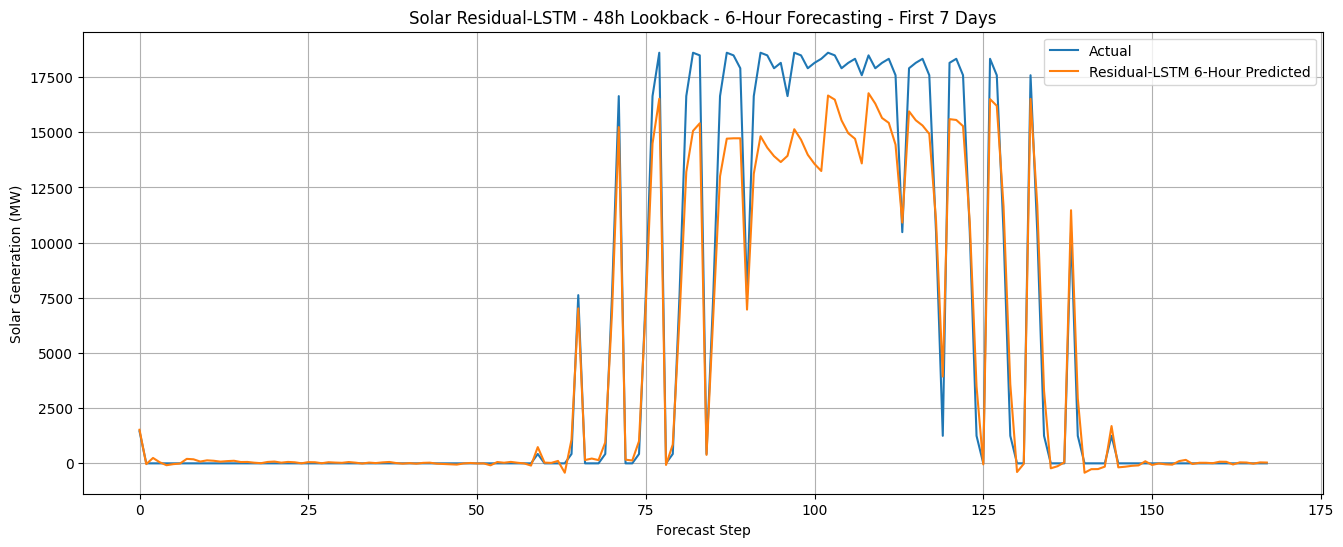

In [57]:
# Plot first seven days

HOURS_TO_PLOT_RESIDUAL_6H_NEW = 24 * 7

plt.figure(figsize=(16, 6))

plt.plot(
    residual_actual_6h_new_flat[
        :HOURS_TO_PLOT_RESIDUAL_6H_NEW
    ],
    label="Actual"
)

plt.plot(
    residual_pred_6h_new_flat[
        :HOURS_TO_PLOT_RESIDUAL_6H_NEW
    ],
    label="Residual-LSTM 6-Hour Predicted"
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM - 48h Lookback - "
    "6-Hour Forecasting - First 7 Days"
)

plt.legend()
plt.grid(True)

plt.show()

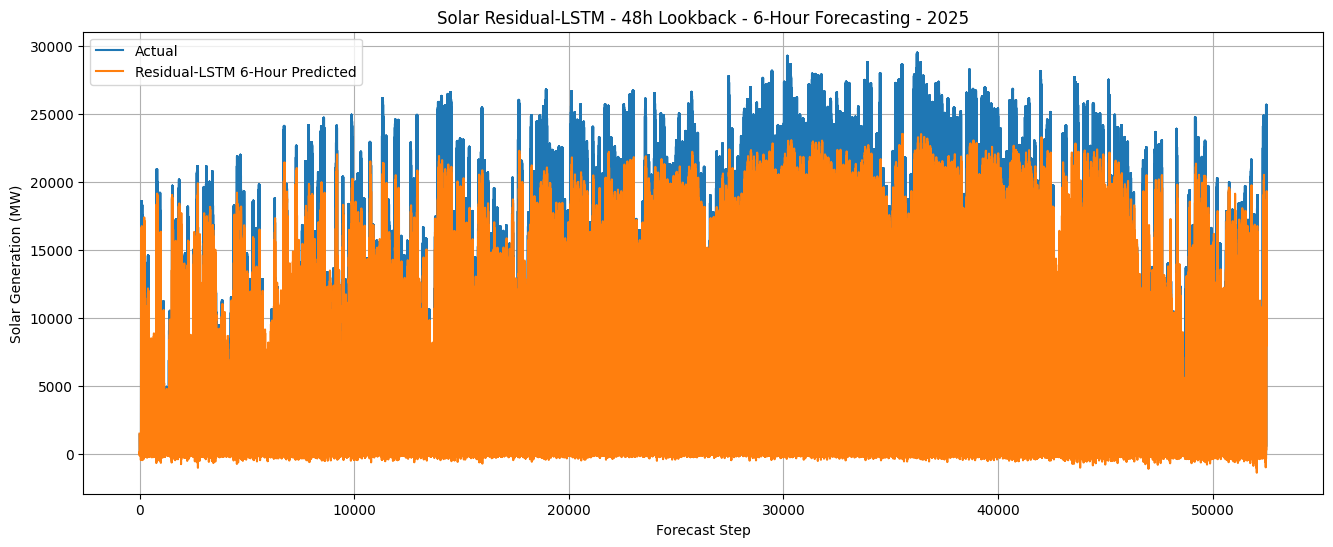

In [58]:
# Plot complete 2025 forecast

plt.figure(figsize=(16, 6))

plt.plot(
    residual_actual_6h_new_flat,
    label="Actual"
)

plt.plot(
    residual_pred_6h_new_flat,
    label="Residual-LSTM 6-Hour Predicted"
)

plt.xlabel("Forecast Step")
plt.ylabel("Solar Generation (MW)")

plt.title(
    "Solar Residual-LSTM - 48h Lookback - "
    "6-Hour Forecasting - 2025"
)

plt.legend()
plt.grid(True)

plt.show()

# 24hr forecast

In [9]:
# Extract training and testing features and targets

X_train_raw = train_df[
    FEATURES
].values

y_train_raw = train_df[
    TARGET
].values.reshape(-1, 1)

X_test_raw = test_df[
    FEATURES
].values

y_test_raw = test_df[
    TARGET
].values.reshape(-1, 1)

print(
    "X_train:",
    X_train_raw.shape
)

print(
    "y_train:",
    y_train_raw.shape
)

print(
    "X_test :",
    X_test_raw.shape
)

print(
    "y_test :",
    y_test_raw.shape
)

X_train: (17537, 12)
y_train: (17537, 1)
X_test : (8760, 12)
y_test : (8760, 1)


In [10]:
# Create scalers using training data only

feature_scaler = StandardScaler()

target_scaler = StandardScaler()

In [11]:
# Fit scalers only on 2023-2024 training data
# and transform both training and testing data

X_train_scaled = feature_scaler.fit_transform(
    X_train_raw
)

X_test_scaled = feature_scaler.transform(
    X_test_raw
)

y_train_scaled = target_scaler.fit_transform(
    y_train_raw
)

y_test_scaled = target_scaler.transform(
    y_test_raw
)

print(
    "Training feature mean:",
    X_train_scaled.mean(axis=0)
)

print(
    "Training feature std :",
    X_train_scaled.std(axis=0)
)

Training feature mean: [ 2.59307379e-17 -2.33376641e-16 -2.07445903e-16 -2.33376641e-16
 -5.83441603e-17  8.42748982e-17  9.39989250e-17 -1.73411810e-16
 -7.25250326e-17  3.48444291e-17  1.03722952e-16 -5.18614758e-17]
Training feature std : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
# Define the historical lookback window
# and forecasting horizon

LOOKBACK_24H = 24
HORIZON_24H = 24

print(
    "Lookback :",
    LOOKBACK_24H,
    "hours"
)

print(
    "Horizon  :",
    HORIZON_24H,
    "hours"
)

Lookback : 24 hours
Horizon  : 24 hours


In [13]:
# Create multi-step sequences

def create_multistep_sequences(
    X,
    y,
    lookback,
    horizon
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X) - horizon + 1
    ):

        # Historical input window
        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        # Future target window
        y_seq.append(
            y[
                i:i + horizon
            ].flatten()
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )

In [14]:
# Create 24-hour input sequences
# with 24 future target hours

X_train_24h, y_train_24h = (
    create_multistep_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK_24H,
        HORIZON_24H
    )
)

print(
    "X_train_24h:",
    X_train_24h.shape
)

print(
    "y_train_24h:",
    y_train_24h.shape
)

X_train_24h: (17490, 24, 12)
y_train_24h: (17490, 24)


In [15]:
# Combine training and testing data so that
# the first 2025 forecast can use late-2024 history

X_combined_24h = np.concatenate(
    [
        X_train_scaled,
        X_test_scaled
    ],
    axis=0
)

y_combined_24h = np.concatenate(
    [
        y_train_scaled,
        y_test_scaled
    ],
    axis=0
)

train_size_24h = len(
    X_train_scaled
)

X_test_24h = []
y_test_24h = []

for i in range(
    train_size_24h,
    len(X_combined_24h) - HORIZON_24H + 1
):

    X_test_24h.append(
        X_combined_24h[
            i - LOOKBACK_24H:i
        ]
    )

    y_test_24h.append(
        y_combined_24h[
            i:i + HORIZON_24H
        ].flatten()
    )

X_test_24h = np.array(
    X_test_24h
)

y_test_24h = np.array(
    y_test_24h
)

print(
    "X_test_24h:",
    X_test_24h.shape
)

print(
    "y_test_24h:",
    y_test_24h.shape
)

X_test_24h: (8737, 24, 12)
y_test_24h: (8737, 24)


In [16]:
# Verify the first and last complete 24-hour forecast periods

print(
    "First 24-hour forecast:"
)

print(
    test_df[
        'Datetime_UTC'
    ].iloc[0]
)

print(
    "→"
)

print(
    test_df[
        'Datetime_UTC'
    ].iloc[23]
)

print(
    "\nLast complete 24-hour forecast:"
)

print(
    test_df[
        'Datetime_UTC'
    ].iloc[-24]
)

print(
    "→"
)

print(
    test_df[
        'Datetime_UTC'
    ].iloc[-1]
)

print(
    "\nNumber of 24-hour forecasts:",
    len(y_test_24h)
)

First 24-hour forecast:
2025-01-01 00:00:00+00:00
→
2025-01-01 23:00:00+00:00

Last complete 24-hour forecast:
2025-12-31 00:00:00+00:00
→
2025-12-31 23:00:00+00:00

Number of 24-hour forecasts: 8737


In [17]:
# Convert the 24-hour sequence data into PyTorch tensors

X_train_24h_tensor = torch.tensor(
    X_train_24h,
    dtype=torch.float32
)

y_train_24h_tensor = torch.tensor(
    y_train_24h,
    dtype=torch.float32
)

X_test_24h_tensor = torch.tensor(
    X_test_24h,
    dtype=torch.float32
)

y_test_24h_tensor = torch.tensor(
    y_test_24h,
    dtype=torch.float32
)

print(
    "X_train:",
    X_train_24h_tensor.shape
)

print(
    "y_train:",
    y_train_24h_tensor.shape
)

print(
    "X_test :",
    X_test_24h_tensor.shape
)

print(
    "y_test :",
    y_test_24h_tensor.shape
)

X_train: torch.Size([17490, 24, 12])
y_train: torch.Size([17490, 24])
X_test : torch.Size([8737, 24, 12])
y_test : torch.Size([8737, 24])


In [18]:
# Create DataLoaders for 24-hour LSTM forecasting

BATCH_SIZE_24H = 64

train_dataset_24h = TensorDataset(
    X_train_24h_tensor,
    y_train_24h_tensor
)

test_dataset_24h = TensorDataset(
    X_test_24h_tensor,
    y_test_24h_tensor
)

train_loader_24h = DataLoader(
    train_dataset_24h,
    batch_size=BATCH_SIZE_24H,
    shuffle=True
)

test_loader_24h = DataLoader(
    test_dataset_24h,
    batch_size=BATCH_SIZE_24H,
    shuffle=False
)

print(
    "Training batches:",
    len(train_loader_24h)
)

print(
    "Testing batches :",
    len(test_loader_24h)
)

Training batches: 274
Testing batches : 137


In [19]:
# Define the baseline LSTM model
# for 24-hour multi-output forecasting

class SolarLSTM24H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=24
    ):

        super(
            SolarLSTM24H,
            self
        ).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        # LSTM output:
        # (batch, sequence, hidden)

        out, _ = self.lstm(x)

        # Use the final timestep representation

        out = out[:, -1, :]

        out = self.dropout(
            out
        )

        # Predict next 24 hours simultaneously

        out = self.fc(
            out
        )

        return out

In [21]:
# Select GPU if available, otherwise use CPU

device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

print(
    "Using device:",
    device
)

Using device: cpu


In [22]:
# Initialize the 24-hour baseline LSTM

INPUT_SIZE_24H = len(
    FEATURES
)

HIDDEN_SIZE_24H = 128

NUM_LAYERS_24H = 1

DROPOUT_24H = 0.2

model_24h = SolarLSTM24H(
    input_size=INPUT_SIZE_24H,
    hidden_size=HIDDEN_SIZE_24H,
    num_layers=NUM_LAYERS_24H,
    dropout=DROPOUT_24H,
    horizon=HORIZON_24H
).to(device)

print(
    model_24h
)

SolarLSTM24H(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=24, bias=True)
)


In [23]:
# Count the trainable parameters

parameters_24h = sum(
    p.numel()
    for p in model_24h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    parameters_24h
)

Trainable parameters: 75800


In [24]:
# Define the loss function and optimizer

criterion_24h = nn.MSELoss()

optimizer_24h = torch.optim.Adam(
    model_24h.parameters(),
    lr=0.001
)

In [25]:
# Train the 24-hour LSTM for one complete epoch

def train_epoch_24h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(
            device
        )

        y_batch = y_batch.to(
            device
        )

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        # Prevent excessively large gradients

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item()
            *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss
        /
        len(loader.dataset)
    )

    return epoch_loss

In [26]:
# Train the baseline 24-hour LSTM for 25 epochs

EPOCHS_24H = 25

train_losses_24h = []

for epoch in range(
    EPOCHS_24H
):

    train_loss = train_epoch_24h(
        model_24h,
        train_loader_24h,
        criterion_24h,
        optimizer_24h,
        device
    )

    train_losses_24h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_24H}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/25] Train Loss: 0.229809
Epoch [02/25] Train Loss: 0.104269
Epoch [03/25] Train Loss: 0.091192
Epoch [04/25] Train Loss: 0.083782
Epoch [05/25] Train Loss: 0.079274
Epoch [06/25] Train Loss: 0.074230
Epoch [07/25] Train Loss: 0.070422
Epoch [08/25] Train Loss: 0.067118
Epoch [09/25] Train Loss: 0.063211
Epoch [10/25] Train Loss: 0.061136
Epoch [11/25] Train Loss: 0.057663
Epoch [12/25] Train Loss: 0.054998
Epoch [13/25] Train Loss: 0.052916
Epoch [14/25] Train Loss: 0.051071
Epoch [15/25] Train Loss: 0.049180
Epoch [16/25] Train Loss: 0.047924
Epoch [17/25] Train Loss: 0.045473
Epoch [18/25] Train Loss: 0.044353
Epoch [19/25] Train Loss: 0.043677
Epoch [20/25] Train Loss: 0.042179
Epoch [21/25] Train Loss: 0.041591
Epoch [22/25] Train Loss: 0.040212
Epoch [23/25] Train Loss: 0.040021
Epoch [24/25] Train Loss: 0.039100
Epoch [25/25] Train Loss: 0.037642


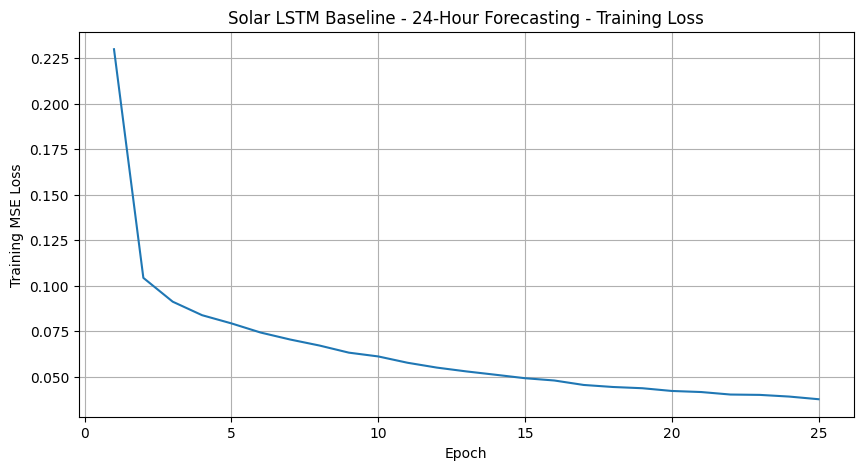

In [27]:
# Plot the 24-hour LSTM training loss

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(
        1,
        EPOCHS_24H + 1
    ),
    train_losses_24h
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Training MSE Loss"
)

plt.title(
    "Solar LSTM Baseline - "
    "24-Hour Forecasting - Training Loss"
)

plt.grid(True)

plt.show()

In [28]:
# Generate 24-hour predictions from the trained LSTM

def predict_24h(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(
                device
            )

            outputs = model(
                X_batch
            )

            predictions.append(
                outputs.cpu().numpy()
            )

            actuals.append(
                y_batch.numpy()
            )

    predictions = np.concatenate(
        predictions,
        axis=0
    )

    actuals = np.concatenate(
        actuals,
        axis=0
    )

    return (
        predictions,
        actuals
    )

In [29]:
# Generate 24-hour forecasts
# for the unseen 2025 test year

pred_24h_scaled, actual_24h_scaled = (
    predict_24h(
        model_24h,
        test_loader_24h,
        device
    )
)

print(
    "Prediction shape:",
    pred_24h_scaled.shape
)

print(
    "Actual shape    :",
    actual_24h_scaled.shape
)

Prediction shape: (8737, 24)
Actual shape    : (8737, 24)


In [30]:
# Convert 24-hour predictions and actual values
# back to MW

pred_24h = target_scaler.inverse_transform(
    pred_24h_scaled
)

actual_24h = target_scaler.inverse_transform(
    actual_24h_scaled
)

print(
    "Prediction shape:",
    pred_24h.shape
)

print(
    "Actual shape    :",
    actual_24h.shape
)

Prediction shape: (8737, 24)
Actual shape    : (8737, 24)


In [31]:
# Evaluate overall 24-hour forecasting performance

pred_24h_flat = (
    pred_24h.flatten()
)

actual_24h_flat = (
    actual_24h.flatten()
)

mae_24h = mean_absolute_error(
    actual_24h_flat,
    pred_24h_flat
)

rmse_24h = np.sqrt(
    mean_squared_error(
        actual_24h_flat,
        pred_24h_flat
    )
)

r2_24h = r2_score(
    actual_24h_flat,
    pred_24h_flat
)

print("=" * 55)

print(
    "SOLAR LSTM BASELINE - "
    "24 HOUR FORECAST"
)

print("=" * 55)

print(
    f"MAE  : {mae_24h:.4f} MW"
)

print(
    f"RMSE : {rmse_24h:.4f} MW"
)

print(
    f"R²   : {r2_24h:.6f}"
)

print("=" * 55)

SOLAR LSTM BASELINE - 24 HOUR FORECAST
MAE  : 2116.9197 MW
RMSE : 3508.1085 MW
R²   : 0.863530


In [32]:
# Calculate MAPE only for periods
# with meaningful solar generation

daylight_mask_24h = (
    actual_24h_flat > 10
)

daylight_mape_24h = np.mean(
    np.abs(
        (
            actual_24h_flat[
                daylight_mask_24h
            ]
            -
            pred_24h_flat[
                daylight_mask_24h
            ]
        )
        /
        actual_24h_flat[
            daylight_mask_24h
        ]
    )
) * 100

print(
    f"Daylight MAPE: "
    f"{daylight_mape_24h:.2f}%"
)

Daylight MAPE: 119.40%


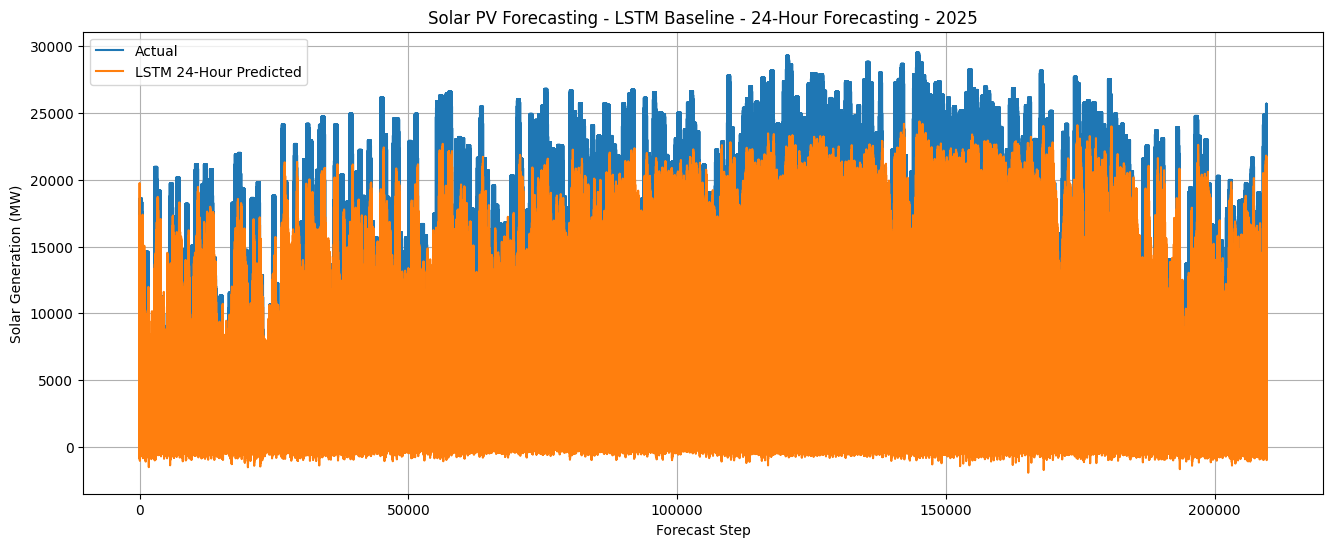

In [33]:
# Plot actual and predicted solar generation
# for the complete 2025 test period

plt.figure(
    figsize=(16, 6)
)

plt.plot(
    actual_24h_flat,
    label='Actual'
)

plt.plot(
    pred_24h_flat,
    label='LSTM 24-Hour Predicted'
)

plt.xlabel(
    "Forecast Step"
)

plt.ylabel(
    "Solar Generation (MW)"
)

plt.title(
    "Solar PV Forecasting - "
    "LSTM Baseline - 24-Hour Forecasting - 2025"
)

plt.legend()

plt.grid(True)

plt.show()

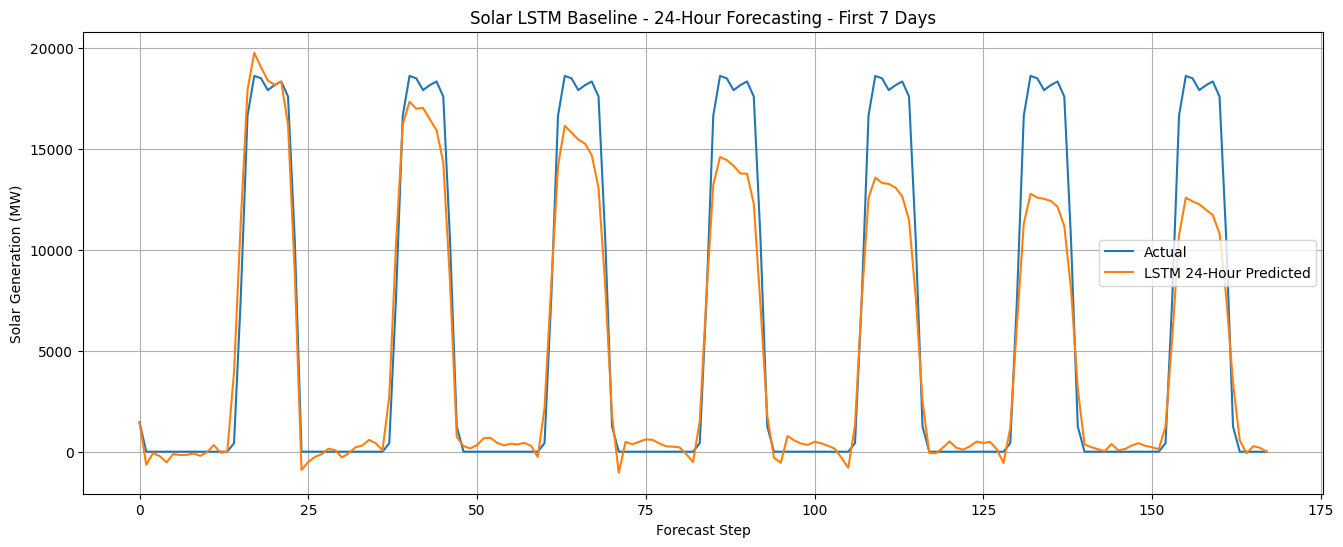

In [34]:
# Plot 24-hour forecasting results
# for the first seven days

HOURS_TO_PLOT_24H = 24 * 7

plt.figure(
    figsize=(16, 6)
)

plt.plot(
    actual_24h_flat[
        :HOURS_TO_PLOT_24H
    ],
    label='Actual'
)

plt.plot(
    pred_24h_flat[
        :HOURS_TO_PLOT_24H
    ],
    label='LSTM 24-Hour Predicted'
)

plt.xlabel(
    "Forecast Step"
)

plt.ylabel(
    "Solar Generation (MW)"
)

plt.title(
    "Solar LSTM Baseline - "
    "24-Hour Forecasting - First 7 Days"
)

plt.legend()

plt.grid(True)

plt.show()

# Residual-LSTM -24hr

In [35]:
# ============================================================
# 24-HOUR RESIDUAL-LSTM
# ============================================================

# Generate base LSTM predictions on training data

model_24h.eval()

with torch.no_grad():

    base_train_pred_24h = model_24h(
        X_train_24h_tensor.to(device)
    ).cpu().numpy()

print(
    "Base train prediction shape:",
    base_train_pred_24h.shape
)

print(
    "Training target shape:",
    y_train_24h.shape
)

Base train prediction shape: (17490, 24)
Training target shape: (17490, 24)


In [36]:
# Calculate the training residuals
# produced by the base 24-hour LSTM

residual_train_24h = (
    y_train_24h -
    base_train_pred_24h
)

print(
    "Residual training shape:",
    residual_train_24h.shape
)

print(
    "Mean residual:",
    residual_train_24h.mean()
)

print(
    "Residual std:",
    residual_train_24h.std()
)

Residual training shape: (17490, 24)
Mean residual: -0.0036646781499406977
Residual std: 0.15118522351546299


In [37]:
# Create Residual-LSTM training DataLoader

residual_train_dataset_24h = TensorDataset(
    X_train_24h_tensor,
    torch.tensor(
        residual_train_24h,
        dtype=torch.float32
    )
)

residual_train_loader_24h = DataLoader(
    residual_train_dataset_24h,
    batch_size=BATCH_SIZE_24H,
    shuffle=True
)

print(
    "Residual training samples:",
    len(residual_train_dataset_24h)
)

print(
    "Residual training batches:",
    len(residual_train_loader_24h)
)

Residual training samples: 17490
Residual training batches: 274


In [38]:
# Define the 24-hour Residual-LSTM

class SolarResidualLSTM24H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=1,
        dropout=0.2,
        horizon=24
    ):

        super(
            SolarResidualLSTM24H,
            self
        ).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        # Process the 24-hour historical sequence

        out, _ = self.lstm(x)

        # Use final timestep representation

        out = out[:, -1, :]

        # Apply dropout

        out = self.dropout(
            out
        )

        # Predict 24-hour residual correction

        out = self.fc(
            out
        )

        return out

In [39]:
# Set Residual-LSTM architecture parameters

RESIDUAL_INPUT_SIZE_24H = len(
    FEATURES
)

RESIDUAL_HIDDEN_SIZE_24H = 128

RESIDUAL_NUM_LAYERS_24H = 1

RESIDUAL_DROPOUT_24H = 0.2

RESIDUAL_HORIZON_24H = 24

print(
    "Input features :",
    RESIDUAL_INPUT_SIZE_24H
)

print(
    "Hidden neurons :",
    RESIDUAL_HIDDEN_SIZE_24H
)

print(
    "LSTM layers    :",
    RESIDUAL_NUM_LAYERS_24H
)

print(
    "Dropout        :",
    RESIDUAL_DROPOUT_24H
)

print(
    "Output horizon :",
    RESIDUAL_HORIZON_24H
)

Input features : 12
Hidden neurons : 128
LSTM layers    : 1
Dropout        : 0.2
Output horizon : 24


In [40]:
# Initialize the 24-hour Residual-LSTM

residual_model_24h = SolarResidualLSTM24H(
    input_size=RESIDUAL_INPUT_SIZE_24H,
    hidden_size=RESIDUAL_HIDDEN_SIZE_24H,
    num_layers=RESIDUAL_NUM_LAYERS_24H,
    dropout=RESIDUAL_DROPOUT_24H,
    horizon=RESIDUAL_HORIZON_24H
).to(device)

print(
    residual_model_24h
)

SolarResidualLSTM24H(
  (lstm): LSTM(12, 128, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=24, bias=True)
)


In [41]:
# Count trainable parameters

residual_parameters_24h = sum(
    p.numel()
    for p in residual_model_24h.parameters()
    if p.requires_grad
)

print(
    "Residual-LSTM trainable parameters:",
    residual_parameters_24h
)

Residual-LSTM trainable parameters: 75800


In [42]:
# Define loss and optimizer

criterion_residual_24h = nn.MSELoss()

optimizer_residual_24h = torch.optim.Adam(
    residual_model_24h.parameters(),
    lr=0.001
)

In [43]:
# Train the Residual-LSTM for one complete epoch

def train_residual_epoch_24h(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for X_batch, residual_batch in loader:

        X_batch = X_batch.to(
            device
        )

        residual_batch = residual_batch.to(
            device
        )

        optimizer.zero_grad()

        residual_prediction = model(
            X_batch
        )

        loss = criterion(
            residual_prediction,
            residual_batch
        )

        loss.backward()

        # Prevent excessively large gradients

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item()
            *
            X_batch.size(0)
        )

    epoch_loss = (
        running_loss
        /
        len(loader.dataset)
    )

    return epoch_loss

In [44]:
# Train the 24-hour Residual-LSTM

EPOCHS_RESIDUAL_24H = 30

residual_train_losses_24h = []

for epoch in range(
    EPOCHS_RESIDUAL_24H
):

    train_loss = train_residual_epoch_24h(
        residual_model_24h,
        residual_train_loader_24h,
        criterion_residual_24h,
        optimizer_residual_24h,
        device
    )

    residual_train_losses_24h.append(
        train_loss
    )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_RESIDUAL_24H}] "
        f"Residual Train Loss: {train_loss:.6f}"
    )

Epoch [01/30] Residual Train Loss: 0.021629
Epoch [02/30] Residual Train Loss: 0.020863
Epoch [03/30] Residual Train Loss: 0.020567
Epoch [04/30] Residual Train Loss: 0.020334
Epoch [05/30] Residual Train Loss: 0.020089
Epoch [06/30] Residual Train Loss: 0.019871
Epoch [07/30] Residual Train Loss: 0.019604
Epoch [08/30] Residual Train Loss: 0.019325
Epoch [09/30] Residual Train Loss: 0.018773
Epoch [10/30] Residual Train Loss: 0.018133
Epoch [11/30] Residual Train Loss: 0.017277
Epoch [12/30] Residual Train Loss: 0.016318
Epoch [13/30] Residual Train Loss: 0.015378
Epoch [14/30] Residual Train Loss: 0.014406
Epoch [15/30] Residual Train Loss: 0.013388
Epoch [16/30] Residual Train Loss: 0.012586
Epoch [17/30] Residual Train Loss: 0.011984
Epoch [18/30] Residual Train Loss: 0.011377
Epoch [19/30] Residual Train Loss: 0.010956
Epoch [20/30] Residual Train Loss: 0.010531
Epoch [21/30] Residual Train Loss: 0.010198
Epoch [22/30] Residual Train Loss: 0.009830
Epoch [23/30] Residual Train Los

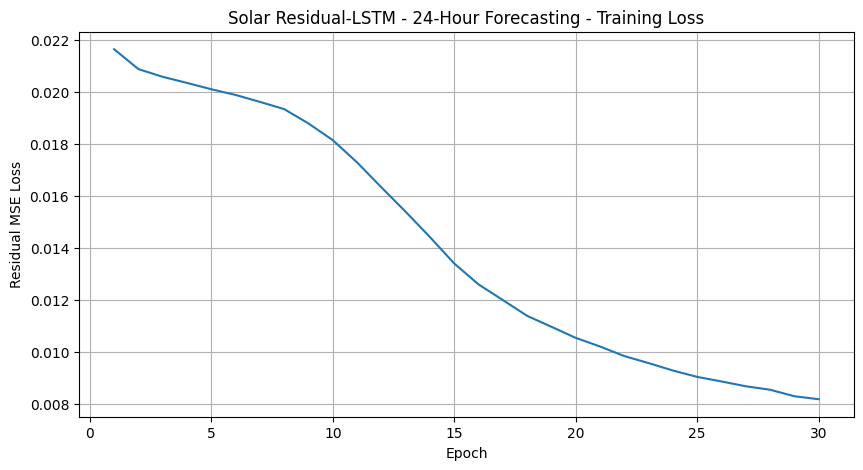

In [45]:
# Plot Residual-LSTM training loss

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_24H + 1
    ),
    residual_train_losses_24h
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Residual MSE Loss"
)

plt.title(
    "Solar Residual-LSTM - "
    "24-Hour Forecasting - Training Loss"
)

plt.grid(True)

plt.show()

In [46]:
# Generate residual corrections for the
# unseen 2025 test data

residual_model_24h.eval()

with torch.no_grad():

    predicted_residual_24h = (
        residual_model_24h(
            X_test_24h_tensor.to(device)
        )
        .cpu()
        .numpy()
    )

print(
    "Predicted residual shape:",
    predicted_residual_24h.shape
)

Predicted residual shape: (8737, 24)


In [47]:
# Add predicted residual correction
# to the base 24-hour forecast

residual_pred_24h_scaled = (
    pred_24h_scaled +
    predicted_residual_24h
)

print(
    "Final prediction shape:",
    residual_pred_24h_scaled.shape
)

Final prediction shape: (8737, 24)


In [48]:
# Convert Residual-LSTM corrected predictions
# back to MW

residual_pred_24h = (
    target_scaler.inverse_transform(
        residual_pred_24h_scaled
    )
)

residual_actual_24h = (
    target_scaler.inverse_transform(
        actual_24h_scaled
    )
)

print(
    "Prediction shape:",
    residual_pred_24h.shape
)

print(
    "Actual shape:",
    residual_actual_24h.shape
)

print(
    "Prediction min:",
    residual_pred_24h.min()
)

print(
    "Prediction max:",
    residual_pred_24h.max()
)

Prediction shape: (8737, 24)
Actual shape: (8737, 24)
Prediction min: -2769.9722
Prediction max: 25846.957


In [49]:
# Evaluate overall Residual-LSTM performance

residual_pred_24h_flat = (
    residual_pred_24h.flatten()
)

residual_actual_24h_flat = (
    residual_actual_24h.flatten()
)

residual_mae_24h = mean_absolute_error(
    residual_actual_24h_flat,
    residual_pred_24h_flat
)

residual_rmse_24h = np.sqrt(
    mean_squared_error(
        residual_actual_24h_flat,
        residual_pred_24h_flat
    )
)

residual_r2_24h = r2_score(
    residual_actual_24h_flat,
    residual_pred_24h_flat
)

print("=" * 60)

print(
    "SOLAR RESIDUAL-LSTM - 24 HOUR FORECAST"
)

print("=" * 60)

print(
    f"MAE  : {residual_mae_24h:.4f} MW"
)

print(
    f"RMSE : {residual_rmse_24h:.4f} MW"
)

print(
    f"R²   : {residual_r2_24h:.6f}"
)

print("=" * 60)

SOLAR RESIDUAL-LSTM - 24 HOUR FORECAST
MAE  : 2234.1057 MW
RMSE : 3703.3061 MW
R²   : 0.847921


In [50]:
# Compare Residual-LSTM against
# the 24-hour baseline LSTM

residual_mae_improvement_24h = (
    (
        mae_24h -
        residual_mae_24h
    )
    /
    mae_24h
) * 100

residual_rmse_improvement_24h = (
    (
        rmse_24h -
        residual_rmse_24h
    )
    /
    rmse_24h
) * 100

residual_r2_improvement_24h = (
    (
        residual_r2_24h -
        r2_24h
    )
    /
    abs(r2_24h)
) * 100

print(
    f"MAE improvement : "
    f"{residual_mae_improvement_24h:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{residual_rmse_improvement_24h:.2f}%"
)

print(
    f"R² improvement  : "
    f"{residual_r2_improvement_24h:.4f}%"
)

MAE improvement : -5.54%
RMSE improvement: -5.56%
R² improvement  : -1.8076%


In [51]:
# Calculate performance for every
# individual forecast horizon

residual_horizon_results_24h = []

for h in range(
    RESIDUAL_HORIZON_24H
):

    actual_h = (
        residual_actual_24h[:, h]
    )

    pred_h = (
        residual_pred_24h[:, h]
    )

    mae_h = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse_h = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2_h = r2_score(
        actual_h,
        pred_h
    )

    residual_horizon_results_24h.append({

        "Horizon":
            f"t+{h + 1}",

        "MAE_MW":
            mae_h,

        "RMSE_MW":
            rmse_h,

        "R2":
            r2_h
    })

residual_horizon_results_24h = pd.DataFrame(
    residual_horizon_results_24h
)

display(
    residual_horizon_results_24h
)

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1141.971802,1818.954782,0.963297
1,t+2,1500.588013,2392.562329,0.936500
2,t+3,1738.881104,2770.280040,0.914868
3,t+4,1929.125122,3098.826552,0.893478
4,t+5,2091.762451,3354.731435,0.875158
5,t+6,2192.432617,3554.277845,0.859865
6,t+7,2268.409424,3687.072551,0.849198
7,t+8,2325.888916,3797.897840,0.839996
8,t+9,2362.673828,3849.551532,0.835614
9,t+10,2344.529297,3832.120040,0.837099


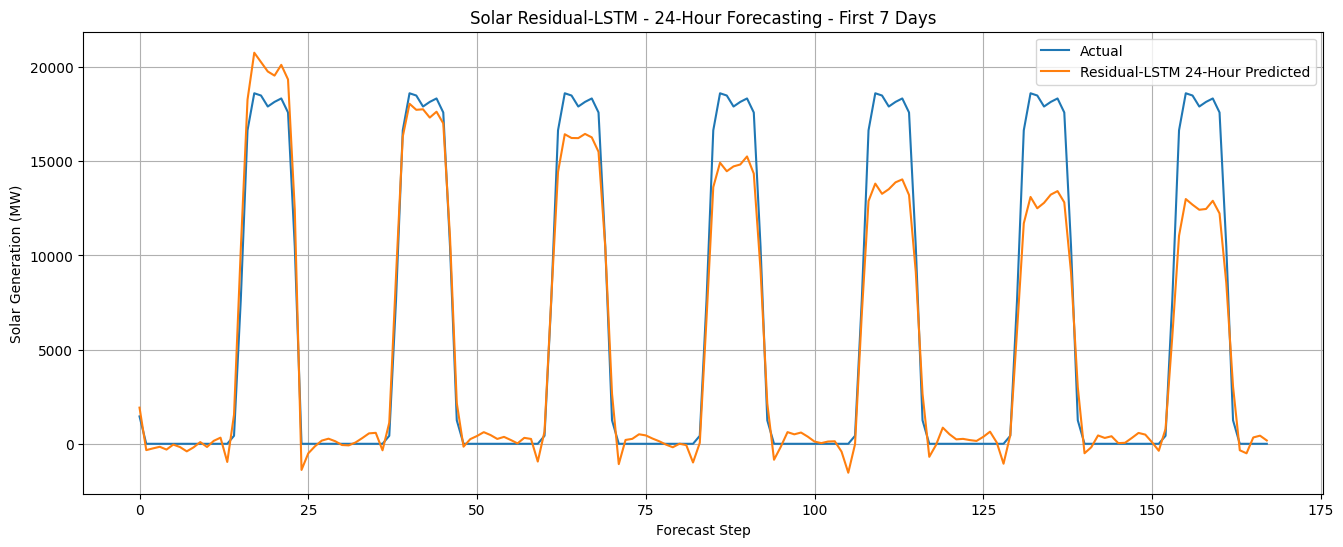

In [52]:
# Plot first seven days

HOURS_TO_PLOT_RESIDUAL_24H = 24 * 7

plt.figure(
    figsize=(16, 6)
)

plt.plot(
    residual_actual_24h_flat[
        :HOURS_TO_PLOT_RESIDUAL_24H
    ],
    label="Actual"
)

plt.plot(
    residual_pred_24h_flat[
        :HOURS_TO_PLOT_RESIDUAL_24H
    ],
    label="Residual-LSTM 24-Hour Predicted"
)

plt.xlabel(
    "Forecast Step"
)

plt.ylabel(
    "Solar Generation (MW)"
)

plt.title(
    "Solar Residual-LSTM - "
    "24-Hour Forecasting - First 7 Days"
)

plt.legend()

plt.grid(True)

plt.show()

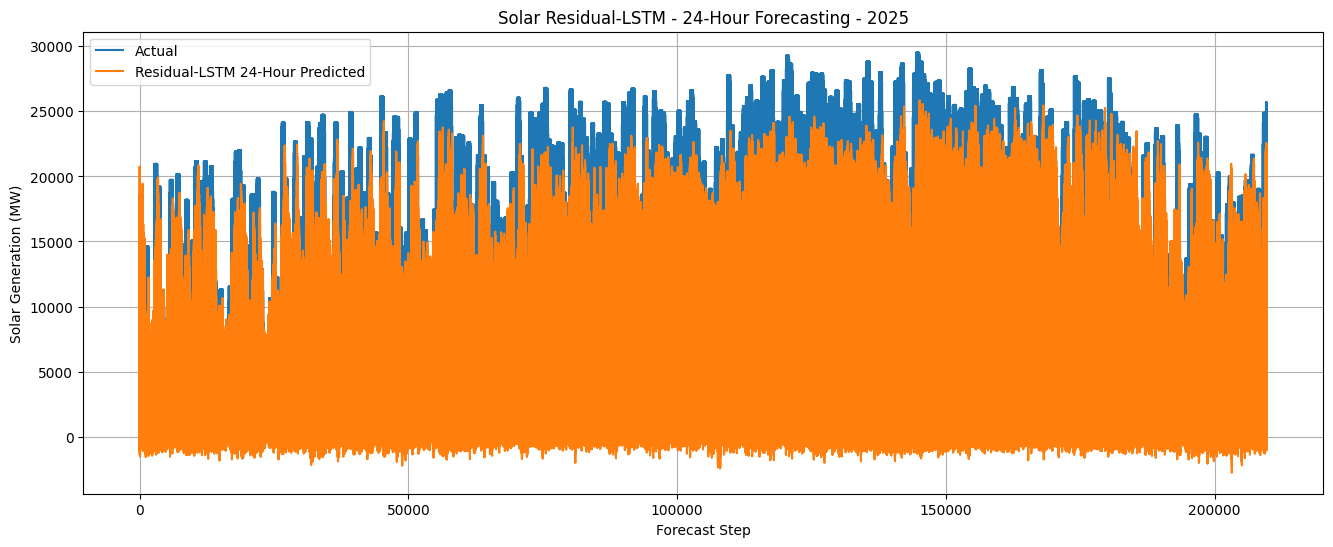

In [53]:
# Plot complete 2025 forecast

plt.figure(
    figsize=(16, 6)
)

plt.plot(
    residual_actual_24h_flat,
    label="Actual"
)

plt.plot(
    residual_pred_24h_flat,
    label="Residual-LSTM 24-Hour Predicted"
)

plt.xlabel(
    "Forecast Step"
)

plt.ylabel(
    "Solar Generation (MW)"
)

plt.title(
    "Solar Residual-LSTM - "
    "24-Hour Forecasting - 2025"
)

plt.legend()

plt.grid(True)

plt.show()

In [54]:
import pandas as pd

# ============================================================
# 1 HOUR FORECASTING
# ============================================================

results_1h = [
    ["1 Hour", "Baseline LSTM",               513.8299,  910.8867, 0.990805],
    ["1 Hour", "CNN-LSTM",                    651.1410, 1077.3985, 0.987136],
    ["1 Hour", "Attention-LSTM",              541.2037,  970.1069, 0.989571],
    ["1 Hour", "Residual-LSTM",               536.0579,  924.4362, 0.990530],
    ["1 Hour", "Residual-LSTM + Non-Negative",483.3971,  918.3333, 0.990654],
]


# ============================================================
# 6 HOUR FORECASTING
# ============================================================

results_6h = [

    # 24-hour lookback
    ["6 Hour", "Baseline LSTM (24h LB)",        1447.9324, 2552.1136, 0.927804],
    ["6 Hour", "Residual-LSTM (24h LB)",       1454.2849, 2562.0769, 0.927239],
    ["6 Hour", "CNN-LSTM (24h LB)",            1606.5846, 2792.6817, 0.913551],
    ["6 Hour", "CNN-LSTM-Attention (24h LB)",  1594.3743, 2812.1844, 0.912340],

    # 48-hour lookback
    ["6 Hour", "Baseline LSTM (48h LB)",       1746.2437, 3048.3149, 0.897001],
    ["6 Hour", "Residual-LSTM (48h LB)",       1685.4000, 2972.3336, 0.902071],
]


# ============================================================
# 24 HOUR FORECASTING
# ============================================================

results_24h = [

    ["24 Hour", "Baseline LSTM (24h LB)",   2116.9197, 3508.1085, 0.863530],
    ["24 Hour", "Residual-LSTM (24h LB)",   2234.1057, 3703.3061, 0.847921],

]


# ============================================================
# CREATE DATAFRAMES
# ============================================================

columns = [
    "Forecasting_Time",
    "Model",
    "MAE_MW",
    "RMSE_MW",
    "R2"
]

results_1h_df = pd.DataFrame(
    results_1h,
    columns=columns
)

results_6h_df = pd.DataFrame(
    results_6h,
    columns=columns
)

results_24h_df = pd.DataFrame(
    results_24h,
    columns=columns
)


# ============================================================
# DISPLAY 1 HOUR RESULTS
# ============================================================

print("=" * 75)
print("1 HOUR FORECASTING")
print("=" * 75)

display(
    results_1h_df.style.format({
        "MAE_MW": "{:.4f}",
        "RMSE_MW": "{:.4f}",
        "R2": "{:.6f}"
    })
)


# ============================================================
# DISPLAY 6 HOUR RESULTS
# ============================================================

print("\n" + "=" * 75)
print("6 HOUR FORECASTING")
print("=" * 75)

display(
    results_6h_df.style.format({
        "MAE_MW": "{:.4f}",
        "RMSE_MW": "{:.4f}",
        "R2": "{:.6f}"
    })
)


# ============================================================
# DISPLAY 24 HOUR RESULTS
# ============================================================

print("\n" + "=" * 75)
print("24 HOUR FORECASTING")
print("=" * 75)

display(
    results_24h_df.style.format({
        "MAE_MW": "{:.4f}",
        "RMSE_MW": "{:.4f}",
        "R2": "{:.6f}"
    })
)

1 HOUR FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,1 Hour,Baseline LSTM,513.8299,910.8867,0.990805
1,1 Hour,CNN-LSTM,651.1410,1077.3985,0.987136
2,1 Hour,Attention-LSTM,541.2037,970.1069,0.989571
3,1 Hour,Residual-LSTM,536.0579,924.4362,0.990530
4,1 Hour,Residual-LSTM + Non-Negative,483.3971,918.3333,0.990654



6 HOUR FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,6 Hour,Baseline LSTM (24h LB),1447.9324,2552.1136,0.927804
1,6 Hour,Residual-LSTM (24h LB),1454.2849,2562.0769,0.927239
2,6 Hour,CNN-LSTM (24h LB),1606.5846,2792.6817,0.913551
3,6 Hour,CNN-LSTM-Attention (24h LB),1594.3743,2812.1844,0.912340
4,6 Hour,Baseline LSTM (48h LB),1746.2437,3048.3149,0.897001
5,6 Hour,Residual-LSTM (48h LB),1685.4000,2972.3336,0.902071



24 HOUR FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,24 Hour,Baseline LSTM (24h LB),2116.9197,3508.1085,0.863530
1,24 Hour,Residual-LSTM (24h LB),2234.1057,3703.3061,0.847921
